# DSA8003 — Data Mining | Group 4
## Movement Organisation, Variability and Unusualness in Smartphone Sensor Measurements

**Integrated research notebook · 2026/27**

**Overarching research question:** *What can smartphone sensor data reveal about how human movement is naturally organised, how different movement patterns vary, and why certain observations appear unusual?*

| Research stream | Contributors and source of analytical work |
|---|---|
| Data integrity and representation | Atharva; original EDA and RQ1 investigations |
| RQ1 — Movement organisation | Atharva and Abrar; RQ1 final investigation |
| RQ2 — Movement variability | Youssef and Sushanth; standalone RQ2, original EDA and shared anomaly analyses |
| RQ3 — Individual differences | Muhatasim and Subhashini; participant and temporal work from the group investigations |
| Overall synthesis and validation | Integrated analysis; confirm individual validation contributions before submission |

This notebook combines and revises the contributors' substantive experiments using a **single training-derived representation**. It preserves alternative methods, negative results and physical interpretation while avoiding separate, conflicting preprocessing pipelines. The original papers and authorship should be acknowledged in the final submission.

**Execution status:** This integrated edition includes newly reorganised and additional experiments. Code cells are intentionally provided without stale output from earlier, different pipelines. Execute **Run All** on the UCI HAR dataset, then check all numerical conclusions and complete the team's AI-use disclosure before submission. Earlier notebooks' figures and numerical findings are not represented as outputs of this unexecuted integrated edition.

# 1. Introduction and Research Objectives

The dataset records six labelled activities, but the existence of six labels does not imply six compact or naturally separated regions of sensor-feature space. Similarly, an observation may be unusual under a global distance measure without representing erroneous or pathological behaviour. The scientific problem is to distinguish **organisation**, **variation** and **individual context**.

This investigation addresses three research questions:

1. **RQ1.** *Does human movement naturally organise into distinct categories, or into broader families containing overlapping and more specialised movement patterns?*
2. **RQ2.** *Are some forms of human movement inherently more variable than others, and does this diversity explain why they appear disproportionately unusual?*
3. **RQ3.** *Do unusual movement observations represent consistent differences in how individuals move, or isolated departures from otherwise typical movement behaviour?*

The concluding section synthesises the three answers and uses the nine **held-out participants** to examine how far the findings generalise. This is **not a fourth research question**.

## 1.1 Dataset and inferential scope

The UCI HAR dataset contains 128-sample (2.56-second) windows sampled at 50 Hz, with a 50% overlap. Each window has 561 engineered features and an activity and participant identifier. Windows are **correlated measurements**, not independent human subjects; clusters are descriptive partitions; anomaly flags represent unusualness **relative to a detector and reference group**, not labelled abnormal events.

**Separation of roles.** Activity and participant labels are metadata for describing discovered structure, investigating variation and performing explanatory or supervised checks. They are not used to choose the primary unsupervised representation or the number of clusters. The original subject-disjoint test split is reserved until the final synthesis.

# 2. Dataset Preparation and Data Quality

## 2.1 Data loading

The analysis uses the supplied training split for preprocessing, exploratory analysis and model development. The original held-out split is first loaded in Section 8. All numerical transformations are fitted on training observations. Duplicate feature names are disambiguated so every engineered measurement can be tracked unambiguously.

In [1]:
import os, re, zipfile, urllib.request, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr, median_abs_deviation
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, adjusted_rand_score, adjusted_mutual_info_score,
                             confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             balanced_accuracy_score, f1_score)
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})

# Set HAR_DATA_DIR (or assign DATA_DIR_OVERRIDE) to the folder containing features.txt and train/.
DATA_DIR_OVERRIDE = None
DATA_URL = 'https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip'

def locate_dataset():
    if DATA_DIR_OVERRIDE is not None:
        candidate = Path(DATA_DIR_OVERRIDE).expanduser()
        if (candidate/'features.txt').exists(): return candidate
        raise FileNotFoundError(f'Not a UCI HAR dataset folder: {candidate}')
    env = os.environ.get('HAR_DATA_DIR')
    if env:
        candidate = Path(env).expanduser()
        if (candidate/'features.txt').exists(): return candidate
        raise FileNotFoundError(f'HAR_DATA_DIR lacks features.txt: {candidate}')
    roots = [Path('.'),Path('./data'),Path('/kaggle/input'),Path('/kaggle/working'),Path('/content')]
    for root in roots:
        if not root.exists(): continue
        if (root/'features.txt').exists() and (root/'train/X_train.txt').exists(): return root
        for candidate in root.glob('**/features.txt'):
            if len(candidate.parts)-len(root.parts)>7: continue
            if (candidate.parent/'train/X_train.txt').exists(): return candidate.parent
    return None

def extract_nested(zfile, destination):
    with zipfile.ZipFile(zfile) as z: z.extractall(destination)
    for inner in destination.rglob('UCI HAR Dataset.zip'):
        with zipfile.ZipFile(inner) as z: z.extractall(inner.parent)

DATA_DIR = locate_dataset()
if DATA_DIR is None:
    cache=Path('uci_har_cache'); cache.mkdir(exist_ok=True)
    archive=cache/'uci_har.zip'
    if not archive.exists():
        print('Downloading the public UCI HAR dataset because a local copy was not found...')
        urllib.request.urlretrieve(DATA_URL,archive)
    extract_nested(archive,cache)
    DATA_DIR=locate_dataset()
if DATA_DIR is None:
    raise FileNotFoundError('UCI HAR dataset missing. Set HAR_DATA_DIR to the folder containing features.txt and train/.')
print('Dataset folder:', DATA_DIR)

raw_names=pd.read_csv(DATA_DIR/'features.txt', sep=r'\s+',header=None)[1].tolist()
counts=pd.Series(raw_names).value_counts()
seen={}; feature_names=[]
for name in raw_names:
    k=seen.get(name,0); seen[name]=k+1
    feature_names.append(f'{name}-{("XYZ"[k] if k<3 else str(k+1))}' if counts[name]>1 else name)
assert len(feature_names)==561 and len(set(feature_names))==561

label_frame=pd.read_csv(DATA_DIR/'activity_labels.txt',sep=r'\s+',header=None,names=['id','activity'])
label_map=dict(zip(label_frame.id,label_frame.activity))
ACTIVITIES=[label_map[i] for i in sorted(label_map)]
ACTIVITY_COLORS=dict(zip(ACTIVITIES,sns.color_palette('tab10',len(ACTIVITIES))))

def load_split(name):
    root=DATA_DIR/name
    X=pd.read_csv(root/f'X_{name}.txt',sep=r'\s+',header=None,names=feature_names)
    act=pd.read_csv(root/f'y_{name}.txt',sep=r'\s+',header=None).iloc[:,0].rename('activity_id')
    subj=pd.read_csv(root/f'subject_{name}.txt',sep=r'\s+',header=None).iloc[:,0].rename('subject_id')
    meta=pd.concat([subj,act],axis=1)
    meta['activity']=meta.activity_id.map(label_map)
    meta['window_id']=np.arange(len(meta))
    assert len(X)==len(meta)
    return X,meta

X_train_raw,meta_train=load_split('train')  # No test data are loaded during EDA or RQ1-3
print(f'Training windows: {len(X_train_raw):,}; participants: {meta_train.subject_id.nunique()}; original features: {X_train_raw.shape[1]}')

Dataset folder: UCI HAR Dataset
Training windows: 7,352; participants: 21; original features: 561


## 2.2 Data integrity and duplicate features

We examine missing and non-finite values, constant features, repeated windows, and columns with exactly identical values. Exact duplicate columns convey no additional numerical information and are removed before representation selection. Highly correlated *non-identical* columns are addressed separately in Section 3 because removing them is a modelling decision, not a data-integrity correction.

In [2]:
# Train-only data integrity audit; show concise factual results, not six diagnostic figures.
constant_cols=X_train_raw.columns[X_train_raw.nunique(dropna=False)<=1].tolist()
exact_dup_mask=X_train_raw.T.duplicated(keep='first')
exact_dropped=X_train_raw.columns[exact_dup_mask].tolist()
X_train_clean=X_train_raw.drop(columns=sorted(set(constant_cols+exact_dropped)))
quality=pd.Series({
    'training windows':len(X_train_raw),
    'participants':meta_train.subject_id.nunique(),
    'original features':X_train_raw.shape[1],
    'missing entries':int(X_train_raw.isna().sum().sum()),
    'non-finite entries':int((~np.isfinite(X_train_raw.to_numpy())).sum()),
    'duplicate complete windows':int(X_train_raw.duplicated().sum()),
    'constant features':len(constant_cols),
    'identical feature copies':len(exact_dropped),
    'unique usable features':X_train_clean.shape[1],
})
display(quality.to_frame('training split only'))
assert np.isfinite(X_train_clean.to_numpy()).all(), 'Investigate missing/non-finite values before continuing.'
assert not X_train_clean.T.duplicated().any()
print('Cleaning outcome:',X_train_clean.shape,'— no correlation-based reduction applied yet.')

,training split only
training windows,7352
participants,21
original features,561
missing entries,0
non-finite entries,0
duplicate complete windows,0
constant features,0
identical feature copies,21
unique usable features,540


Cleaning outcome: (7352, 540) — no correlation-based reduction applied yet.


**Data quality interpretation.** The earlier data audit reported no missing values or constant features and 21 exactly redundant columns. This audit recomputes those quantities using the training split alone. Feature redundancy should not be confused with duplicated measurements or failed recordings: the original dataset deliberately contains overlapping engineered summaries of related physical signals.

# 3. Feature Representation and Preprocessing

## 3.1 Physical feature groups and redundancy

The supplied features describe time- and frequency-domain summaries of acceleration, rotation, jerk, gravity and orientation-related quantities. Two columns measuring related phenomena can become strongly correlated even if they originate from different sensors. The principal representation therefore removes exactly repeated features, filters high-correlation features **within their physical groups**, and preserves separate physical measurement families. The within-group threshold is fixed at an absolute Pearson correlation of 0.95.

The filtering rule gives priority to readily interpretable mean, standard-deviation and energy summaries, then applies a deterministic order to the remaining features. This preserves an auditable set of original feature names, although it does not guarantee an information-optimal subset.

In [3]:
def physical_group(name):
    """Ten non-overlapping groups matching the original group's Task 1 physical taxonomy."""
    if name.startswith('angle('): return 'Angle vs gravity'
    prefix=name[0].lower()
    stem=name.split('-',1)[0].replace('BodyBody','Body')
    if 'GravityAcc' in stem: part='Gravity acceleration'
    elif 'Gyro' in stem: part='Body rotation'+(' jerk' if 'Jerk' in stem else '')
    else: part='Body acceleration'+(' jerk' if 'Jerk' in stem else '')
    return ('Time' if prefix=='t' else 'Frequency')+' · '+part

GROUP_ORDER=[
    'Time · Body acceleration','Time · Body acceleration jerk','Time · Gravity acceleration',
    'Time · Body rotation','Time · Body rotation jerk',
    'Frequency · Body acceleration','Frequency · Body acceleration jerk',
    'Frequency · Body rotation','Frequency · Body rotation jerk','Angle vs gravity'
]

class HARPhysicalFeatureSelector(BaseEstimator,TransformerMixin):
    """Train-only exact-duplicate removal and within-physical-group correlation filtering.

    A deterministic priority favours common interpretable summaries, followed by source order.
    No activity or participant label is read by this transformer.
    """
    def __init__(self, threshold=0.95): self.threshold=threshold
    def fit(self, X, y=None):
        X=pd.DataFrame(X).copy()
        self.original_cols_=X.columns.tolist()
        constant=(X.nunique(dropna=False)<=1)
        X=X.loc[:,~constant]
        X=X.loc[:,~X.T.duplicated(keep='first')]
        self.cleaned_cols_=X.columns.tolist()
        self.groups_={name:physical_group(name) for name in X.columns}
        kept=[]
        for group in GROUP_ORDER:
            names=[n for n in X.columns if self.groups_[n]==group]
            if not names: continue
            def priority(n):
                return (0 if '-mean()' in n else (1 if '-std()' in n else (2 if '-energy()' in n else 3)),
                        self.cleaned_cols_.index(n))
            ordered=sorted(names,key=priority)
            cor=X[ordered].corr().abs().fillna(0)
            group_keep=[]
            for name in ordered:
                if not group_keep or cor.loc[name,group_keep].max()<self.threshold:
                    group_keep.append(name)
            kept.extend(group_keep)
        self.selected_cols_=[name for name in X.columns if name in set(kept)]
        if not self.selected_cols_: raise ValueError('No columns survived feature selection')
        return self
    def transform(self, X):
        X=pd.DataFrame(X)
        missing=set(self.selected_cols_)-set(X.columns)
        if missing: raise ValueError(f'Missing selected features: {sorted(missing)[:5]}')
        return X.loc[:,self.selected_cols_].to_numpy()

selector=HARPhysicalFeatureSelector(threshold=0.95).fit(X_train_raw)
selected_names=selector.selected_cols_
scaler=StandardScaler().fit(selector.transform(X_train_raw))
X_repr=scaler.transform(selector.transform(X_train_raw))
X_repr_df=pd.DataFrame(X_repr,columns=selected_names,index=X_train_raw.index)
assert X_repr.shape[0]==len(meta_train)
print('Original:',X_train_raw.shape[1], '→ after exact cleaning:',len(selector.cleaned_cols_),
      '→ after within-group filtering:',len(selected_names))
print('Shared analytical matrix:',X_repr.shape)


Original: 561 → after exact cleaning: 540 → after within-group filtering: 327
Shared analytical matrix: (7352, 327)


## 3.2 Retained feature coverage

The following comparison shows the change in feature coverage across the physical groups. It is a diagnostic of the representation, not a measure of how important each sensor family is to human activity recognition.

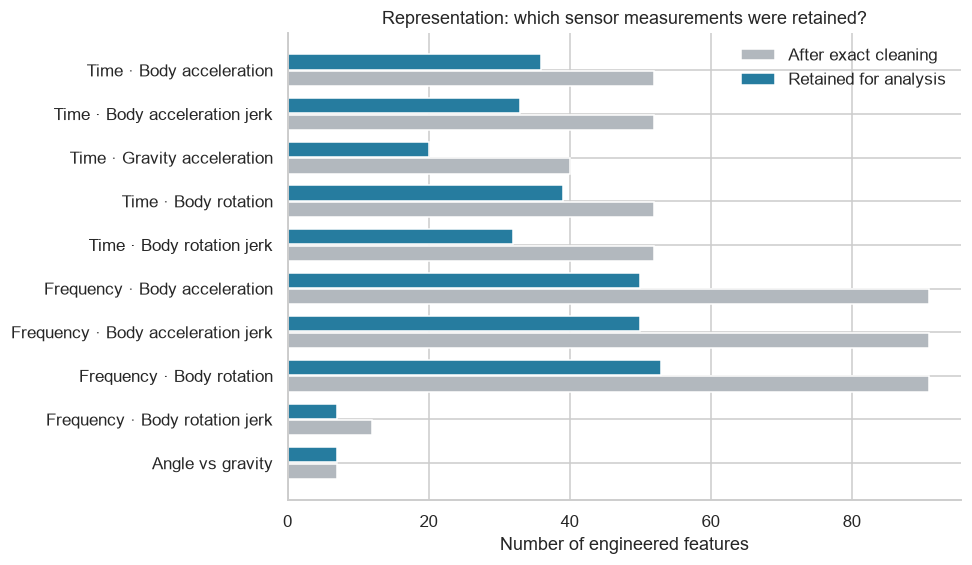

Limitations: threshold is heuristic; correlation does not imply identical physical information; group sizes still differ.


In [4]:
# Directly show what feature information was kept from each physical group.
before=pd.Series([physical_group(c) for c in selector.cleaned_cols_]).value_counts().reindex(GROUP_ORDER,fill_value=0)
after=pd.Series([physical_group(c) for c in selected_names]).value_counts().reindex(GROUP_ORDER,fill_value=0)
fig,ax=plt.subplots(figsize=(9,5.3))
pos=np.arange(len(GROUP_ORDER)); ax.barh(pos+0.19,before.values,height=.35,color='#b2b8be',label='After exact cleaning')
ax.barh(pos-0.19,after.values,height=.35,color='#267c9f',label='Retained for analysis')
ax.set_yticks(pos,GROUP_ORDER);ax.invert_yaxis()
ax.set(xlabel='Number of engineered features',title='Representation: which sensor measurements were retained?')
ax.legend(frameon=False)
plt.tight_layout();plt.show()
print('Limitations: threshold is heuristic; correlation does not imply identical physical information; group sizes still differ.')

**Representation interpretation.** The output establishes the number of retained measurements in each physical group. A substantial reduction within one family indicates that many engineered summaries were statistically similar in the training data. Retaining a range of families is intentional: a modest number of gravity-related features may encode posture information that is absent from more numerous acceleration statistics. StandardScaler is then fitted to the selected features, yielding the shared `X_repr` matrix.

## 3.3 Effect on local similarity

A reasonable feature reduction should not be evaluated only by how many columns it removes. As a sensitivity check, we compare the nearest neighbours obtained from the exactly cleaned, scaled feature space with those obtained from the selected representation. This is a diagnostic of changed geometry; perfect agreement is neither expected nor necessarily desirable, because the original representation overweights redundant measurements.

In [5]:
# Optional diagnostic in words: measure how much the correlation-based reduction changes local neighbours.
# A high overlap is NOT a target to optimise: the original space is known to be redundant.
reference_scaler=StandardScaler().fit(X_train_clean)
X_reference=reference_scaler.transform(X_train_clean)
probe_idx=rng.choice(len(X_repr),size=min(600,len(X_repr)),replace=False)
k_probe=min(10,len(X_repr)-1)
old_n=NearestNeighbors(n_neighbors=k_probe+1).fit(X_reference)
new_n=NearestNeighbors(n_neighbors=k_probe+1).fit(X_repr)
old_ids=old_n.kneighbors(X_reference[probe_idx],return_distance=False)
new_ids=new_n.kneighbors(X_repr[probe_idx],return_distance=False)
overlap=np.mean([len(set(a)-{idx} & (set(b)-{idx}))/k_probe for idx,a,b in zip(probe_idx,old_ids,new_ids)])
print(f'Average {k_probe}-neighbour overlap with the exact-cleaned baseline: {overlap:.1%}.')
print('This diagnoses the consequence of feature reduction; it does not validate activity groups or select clusters.')

Average 10-neighbour overlap with the exact-cleaned baseline: 82.8%.
This diagnoses the consequence of feature reduction; it does not validate activity groups or select clusters.


**Methodological assessment.** The selected representation is used consistently in RQ1–RQ3. PCA is fitted separately to two components solely to show the distribution of observations in figures. Neither a prescribed explained-variance threshold nor a projection chosen to maximise activity-label agreement determines the modelling space. Correlation filtering cannot remove nonlinear redundancy and does not eliminate differences in the number of retained features per physical group; these are relevant limitations when interpreting Euclidean distances.

# 4. Exploratory Data Analysis

Exploration first characterises the underlying signals and sensor-feature distributions, then examines overlap among the recorded activities and participants. The objective is to identify phenomena that later experiments need to explain; activity labels here are used descriptively, not to select the modelling representation.

## 4.1 Raw inertial traces

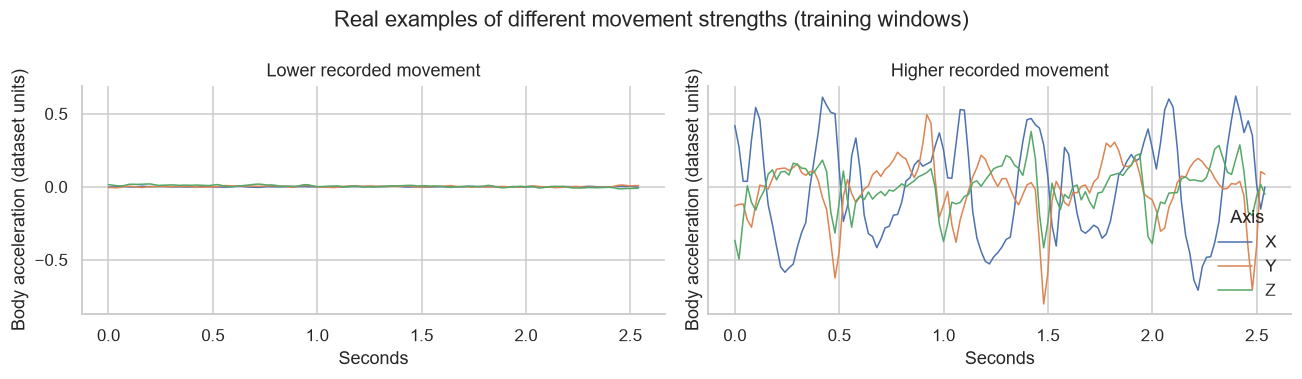

In [6]:
# Figure: actual training acceleration windows at low and high measured body movement.
# These are chosen without activity labels, by root-mean-square body acceleration.
def load_signal(split,signal,axis):
    f=DATA_DIR/split/'Inertial Signals'/f'{signal}_{axis}_{split}.txt'
    return pd.read_csv(f,sep=r'\s+',header=None).to_numpy()

signals_available=(DATA_DIR/'train'/'Inertial Signals'/'body_acc_x_train.txt').exists()
if signals_available:
    body_acc={axis:load_signal('train','body_acc',axis) for axis in 'xyz'}
    acc_magnitude=np.sqrt(sum(body_acc[a]**2 for a in 'xyz'))
    strength=np.sqrt(np.mean(acc_magnitude**2,axis=1))
    weak=int(np.argmin(np.abs(strength-np.quantile(strength,.20))))
    strong=int(np.argmin(np.abs(strength-np.quantile(strength,.90))))
    fig,axes=plt.subplots(1,2,figsize=(12,3.5),sharey=True)
    for ax,i,title in zip(axes,[weak,strong],['Lower recorded movement','Higher recorded movement']):
        for axis in 'xyz': ax.plot(np.arange(128)/50,body_acc[axis][i],lw=1,label=axis.upper())
        ax.set(title=title,xlabel='Seconds',ylabel='Body acceleration (dataset units)')
    axes[1].legend(title='Axis',frameon=False)
    plt.suptitle('Real examples of different movement strengths (training windows)')
    plt.tight_layout();plt.show()
else:
    print('Raw inertial-signal files not found; skipping the raw-signal figure.')

**Interpretation.** High-motion recordings exhibit larger changes in body acceleration within a short window, while lower-motion recordings are relatively stable. Such differences are evident in the raw recordings without requiring a clustering model. They do not on their own determine the number of movement groups, and variations in phone orientation or contact can also influence the recorded amplitudes.

## 4.2 Overall feature-space structure

A two-dimensional PCA projection provides an initial view of the distribution of movement windows. The projection is fitted once using `X_repr` and reused for subsequent cluster and anomaly figures, enabling direct visual comparison without changing the plotting coordinates.

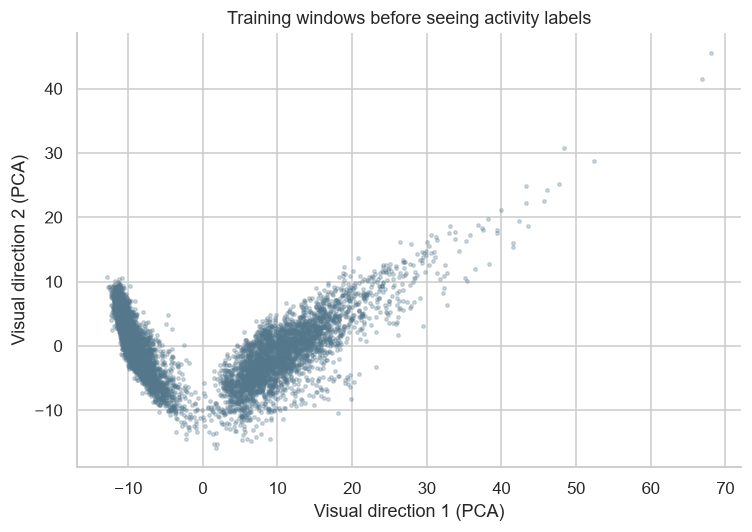

This 2-D picture retains 45.6% of variance; visible gaps/overlaps do not by themselves prove clustering in the full feature space.


In [7]:
# One common, frozen 2-D map used for presentation throughout the notebook.
# Clustering and anomaly scoring NEVER use these two coordinates.
pca_view=PCA(n_components=2,random_state=RANDOM_STATE).fit(X_repr)
view_train=pca_view.transform(X_repr)
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(view_train[:,0],view_train[:,1],s=5,alpha=.27,color='#54778b',rasterized=True)
ax.set(xlabel='Visual direction 1 (PCA)',ylabel='Visual direction 2 (PCA)',
       title='Training windows before seeing activity labels')
plt.tight_layout();plt.show()
print(f'This 2-D picture retains {pca_view.explained_variance_ratio_.sum():.1%} of variance; '
      'visible gaps/overlaps do not by themselves prove clustering in the full feature space.')

**Interpretation.** The original group's PCA analysis showed a strong broad axis of variation and overlap within the more detailed movement patterns. The current projection allows that observation to be reassessed after physically informed feature selection. Apparent concentrations or gaps in two dimensions are suggestive only: clustering quality and neighbourhood relationships will be evaluated in the full selected feature space in RQ1.

## 4.3 Distribution of representative sensor features

Three original engineered measurements are used to illustrate different kinds of signal variation. They are kept on their source scale so that the figures describe the supplied measurements, rather than transformed PCA components. The features are representative examples, not a basis for selecting the final modelling variables.

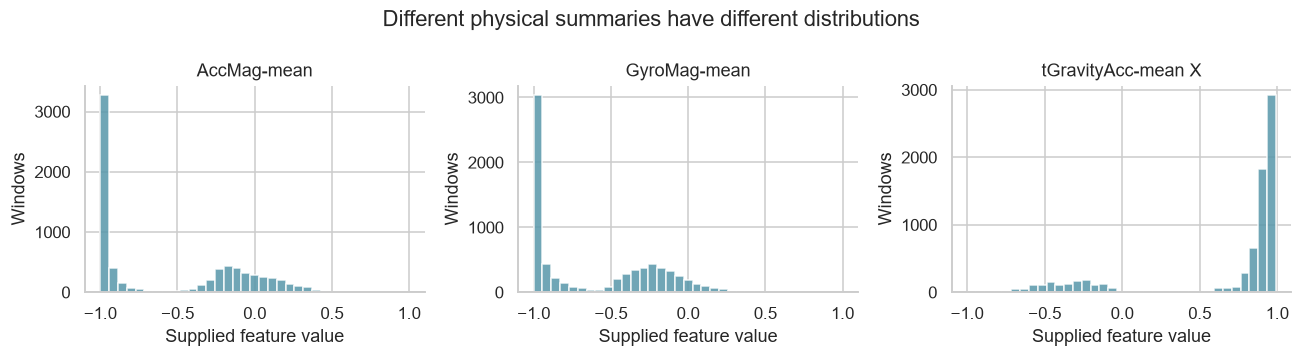

In [8]:
# Three interpretable engineered sensor measurements; these are not calibrated SI units.
example_features=[f for f in ['tBodyAccMag-mean()','tBodyGyroMag-mean()','tGravityAcc-mean()-X'] if f in X_train_raw.columns]
if len(example_features)<3:
    example_features=list(X_train_raw.columns[:3])
fig,axes=plt.subplots(1,len(example_features),figsize=(12,3.3))
for ax,name in zip(np.ravel(axes),example_features):
    ax.hist(X_train_raw[name],bins=35,color='#5797aa',alpha=.85)
    ax.set(title=name.replace('tBody','').replace('()-',' ').replace('()',''),xlabel='Supplied feature value',ylabel='Windows')
plt.suptitle('Different physical summaries have different distributions')
plt.tight_layout();plt.show()

**Interpretation.** Differences between feature distributions reinforce the need to treat movement as multivariate. Acceleration, angular motion and gravity-related features do not encode identical physical information, and their marginal distributions alone cannot establish the structure of joint movement patterns. The formal questions of how windows group and which windows are unusual are examined next.

## 4.4 Local overlap among recorded activities

A PCA picture is not a test of whether activities form distinct groups. Here we examine the **local neighbourhoods** in the full shared feature representation: for each training window, what fraction of its ten nearest *other* windows have the same recorded activity? The resulting confusion-like matrix describes local overlap, not prediction performance (neighbours include other windows from the same participant and overlapping recordings).

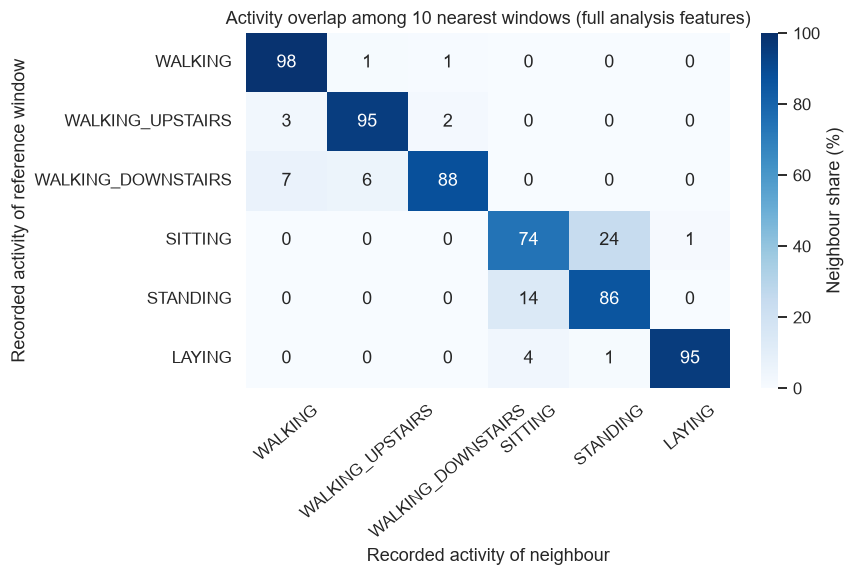

Same-activity neighbourhood share: 0.892


In [9]:
K_EDA = 10
nn_eda = NearestNeighbors(n_neighbors=K_EDA+1, n_jobs=-1).fit(X_repr)
eda_neighbors = nn_eda.kneighbors(X_repr, return_distance=False)[:,1:]
act_values = meta_train.activity.to_numpy()
neighbor_mix = np.zeros((len(ACTIVITIES),len(ACTIVITIES)))
for j, a in enumerate(ACTIVITIES):
    nearby = act_values[eda_neighbors[act_values==a]].ravel()
    neighbor_mix[j] = pd.Series(nearby).value_counts().reindex(ACTIVITIES,fill_value=0).to_numpy()
neighbor_mix = neighbor_mix / np.maximum(neighbor_mix.sum(1,keepdims=True),1)
fig, ax = plt.subplots(figsize=(8,5.4))
sns.heatmap(100*neighbor_mix,annot=True,fmt='.0f',cmap='Blues',vmin=0,vmax=100,ax=ax,
            xticklabels=ACTIVITIES,yticklabels=ACTIVITIES,cbar_kws={'label':'Neighbour share (%)'})
ax.set(xlabel='Recorded activity of neighbour',ylabel='Recorded activity of reference window',
       title='Activity overlap among 10 nearest windows (full analysis features)')
ax.tick_params(axis='x',rotation=40)
plt.tight_layout();plt.show()
print('Same-activity neighbourhood share:',round(float(np.mean(act_values[eda_neighbors]==act_values[:,None])),3))

**Interpretive relevance.** Diagonal concentration supports local similarity among similarly labelled movements, while off-diagonal entries reveal which activities overlap. Because windows from the same participant and recording may be adjacent in feature space, this is a descriptive feature-space analysis, not evidence of subject-independent activity recognition. RQ1 tests whether the resulting geometry produces stable *unlabelled* clusters.

### 4.4.1 Participant concentration within local neighbourhoods

Among windows belonging to the same recorded activity, how often do nearby points come from the **same participant**? This extends the EDA team's finding that person-related structure can remain even after conditioning on the activity. The result motivates RQ3, but contiguous overlapping windows from the same recording may inflate this share.

In [10]:
neighbour_subjects=sub_arr_eda=meta_train.subject_id.to_numpy()[eda_neighbors]
same_act=(act_values[eda_neighbors]==act_values[:,None])
same_person=(neighbour_subjects==meta_train.subject_id.to_numpy()[:,None])
if same_act.any():
    print('Same-person share among same-activity neighbour links:',
          f'{np.mean(same_person[same_act]):.1%}')
    print('Random-person baseline (participant frequency-weighted):',
          f'{np.square(meta_train.subject_id.value_counts(normalize=True).to_numpy()).sum():.1%}')
    print('Caution: these are window-level neighbour links with overlapping observations, not independent events.')

Same-person share among same-activity neighbour links: 60.9%
Random-person baseline (participant frequency-weighted): 4.8%
Caution: these are window-level neighbour links with overlapping observations, not independent events.


## 4.5 Physical features underlying posture overlap

The original EDA investigated the sitting–standing overlap directly rather than assuming that a global projection captures all discriminating information. Here we inspect an acceleration summary (movement intensity) alongside gravity/angle measurements (posture/orientation). The original engineering scale is retained for interpretation.

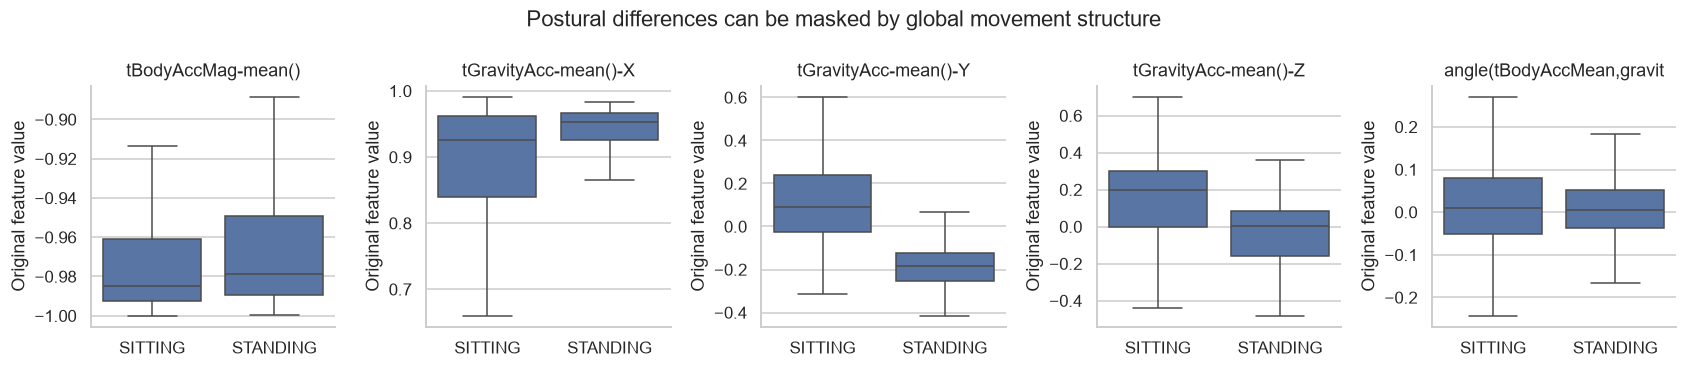

In [11]:
posture_features=[n for n in ['tBodyAccMag-mean()','tGravityAcc-mean()-X','tGravityAcc-mean()-Y',
                               'tGravityAcc-mean()-Z','angle(tBodyAccMean,gravity)'] if n in X_train_raw.columns]
posture_ids=meta_train.activity.isin(['SITTING','STANDING'])
if posture_features:
    raw_posture=X_train_raw.loc[posture_ids,posture_features].copy()
    raw_posture['Activity']=meta_train.loc[posture_ids,'activity'].to_numpy()
    fig,axes=plt.subplots(1,len(posture_features),figsize=(max(12,3.1*len(posture_features)),3.4))
    for ax,feat in zip(np.atleast_1d(axes),posture_features):
        sns.boxplot(data=raw_posture,x='Activity',y=feat,order=['SITTING','STANDING'],showfliers=False,ax=ax)
        ax.set(title=feat[:25],ylabel='Original feature value',xlabel='')
    plt.suptitle('Postural differences can be masked by global movement structure')
    plt.tight_layout();plt.show()
else:
    print('No requested posture/orientation feature found; inspect feature naming.')

# 5. RQ1 — Movement Organisation

**Investigators: Atharva and Abrar.** The analysis first determines which clustering resolutions are *plausible*, then challenges them using alternative assumptions, participant-level stability and representation sensitivity. Only after these checks are the proposed groups interpreted physically and against the recorded activities. An exploratory fine partition may be useful without being uniquely supported as a natural number of movement categories.

## 5.1 Evidence of clustering tendency

In [12]:
# Hopkins-style tendency diagnostic: values above ~0.5 can indicate nonuniform structure,
# but high-dimensional distances and feature dependencies limit a simple interpretation.
def hopkins_statistic(X, sample=250,seed=42):
    rr=np.random.default_rng(seed); X=np.asarray(X)
    m=min(sample,len(X)//2)
    nn=NearestNeighbors(n_neighbors=2).fit(X)
    real=X[rr.choice(len(X),size=m,replace=False)]
    artificial=rr.uniform(X.min(axis=0),X.max(axis=0),size=(m,X.shape[1]))
    wr=nn.kneighbors(real)[0][:,1]
    wa=nn.kneighbors(artificial,n_neighbors=1)[0][:,0]
    return wa.sum()/(wr.sum()+wa.sum())

In [13]:
hopkins=hopkins_statistic(X_repr,seed=RANDOM_STATE)
print(f'Hopkins statistic: {hopkins:.3f}')

Hopkins statistic: 0.879


**Interpretation.** The original investigation reported strong clustering tendency under several PCA representations. The present statistic tests whether non-uniformity remains apparent after correlation-based feature selection. A high value supports further investigation but does not establish the number of groups, their shape or their relationship to recorded activities.

## 5.2 K-Means clustering across resolutions

We fit K-Means over a range of partitions and compare their within-cluster separation using silhouette scores. The silhouette is computed in the selected feature space, rather than from the two-dimensional display. We report additional internal measures numerically where they are relevant to a methodological decision, but the principal figure focuses on how separation changes as partitions become finer.

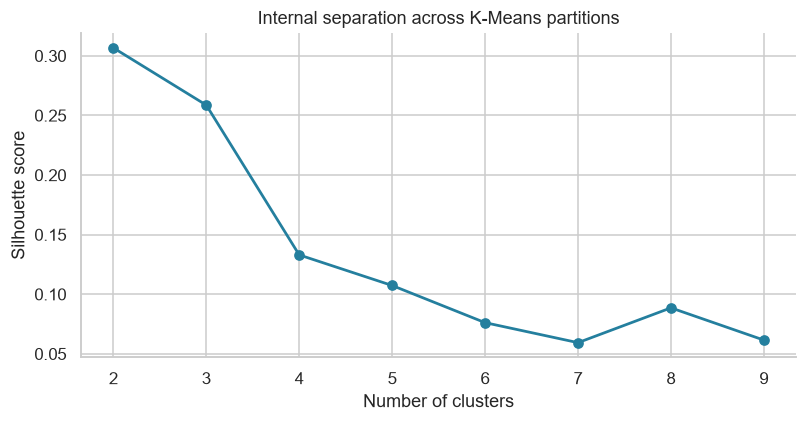

Internal measures for the broad, intermediate and finer partitions:


,silhouette,davies_bouldin,calinski_harabasz
k,,,
2,0.307,1.374,3507.826
3,0.259,2.062,2222.088
6,0.076,2.760,1166.186


In [14]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
CLUSTER_RANGE=list(range(2,10))
cluster_models={}; evaluations=[]
for k in CLUSTER_RANGE:
    fit=KMeans(n_clusters=k,n_init=8,random_state=RANDOM_STATE,max_iter=300).fit(X_repr)
    cluster_models[k]=fit
    labels_k=fit.labels_
    silhouette=silhouette_score(X_repr,labels_k,sample_size=min(1800,len(X_repr)),random_state=RANDOM_STATE)
    evaluations.append({'k':k,'silhouette':silhouette,'davies_bouldin':davies_bouldin_score(X_repr,labels_k),
                        'calinski_harabasz':calinski_harabasz_score(X_repr,labels_k),'inertia':fit.inertia_})
cluster_eval=pd.DataFrame(evaluations).set_index('k')
fig,ax=plt.subplots(figsize=(7.5,4))
ax.plot(cluster_eval.index,cluster_eval.silhouette,marker='o',lw=1.8,color='#247f9e')
ax.set(xlabel='Number of clusters',ylabel='Silhouette score',title='Internal separation across K-Means partitions')
ax.set_xticks(CLUSTER_RANGE)
plt.tight_layout();plt.show()
print('Internal measures for the broad, intermediate and finer partitions:')
display(cluster_eval.loc[[k for k in [2,3,6] if k in CLUSTER_RANGE],['silhouette','davies_bouldin','calinski_harabasz']].round(3))

**Interpretation.** The earlier executed analysis found the clearest separation for two clusters, with progressively weaker separation at finer resolutions. The current curve establishes whether that pattern persists in the selected representation. A lower silhouette at higher *k* indicates greater overlap or fragmentation, but does not rule out informative smaller groups. The alternative internal indices provide a check that the conclusion is not driven solely by one score.

## 5.3 Candidate broad and fine resolutions

The silhouette comparison gives an initial separation assessment, not a final cluster-number decision. We carry forward **two groups** as the broad candidate and **three and six groups** as illustrative finer candidates to test. Six is examined for interpretability and for comparison with the source investigations; it is **not selected because six activities are labelled**. These are working partitions until the checks below have been considered.

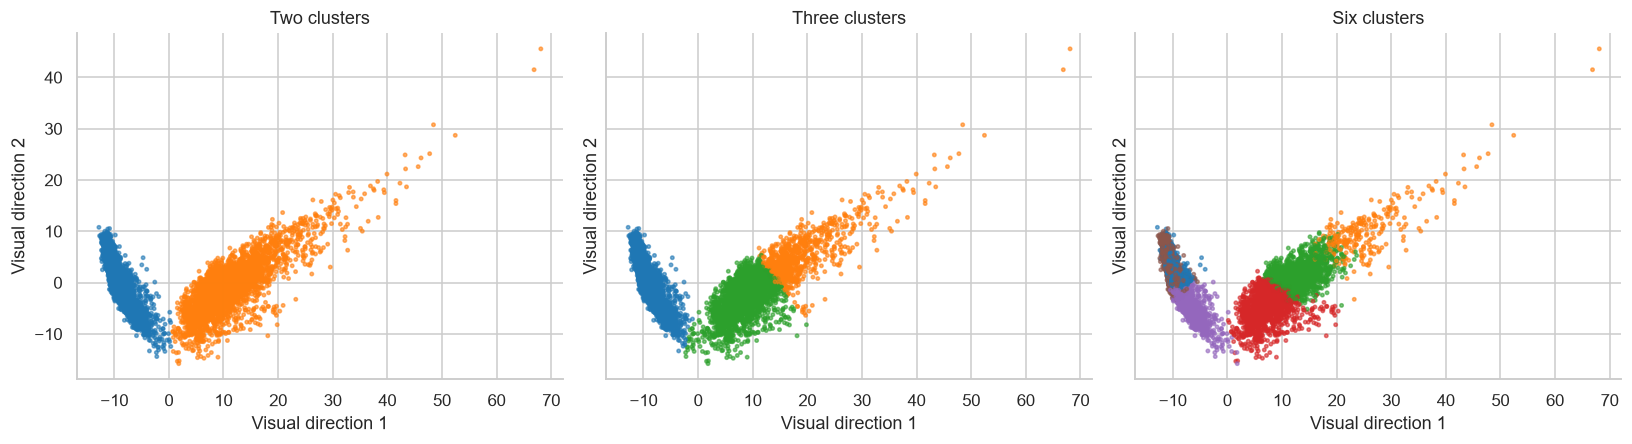

In [15]:
model_broad=cluster_models[2]
model_intermediate=cluster_models[3]
k_fine=6
model_fine=cluster_models[k_fine]
cluster_broad=model_broad.labels_
cluster_intermediate=model_intermediate.labels_
cluster_fine=model_fine.labels_
fig,axes=plt.subplots(1,3,figsize=(15,4.2),sharex=True,sharey=True)
for ax,lab,title in zip(axes,[cluster_broad,cluster_intermediate,cluster_fine],
                        ['Two clusters','Three clusters','Six clusters']):
    ax.scatter(view_train[:,0],view_train[:,1],c=lab,cmap='tab10',vmin=0,vmax=9,
               s=5,alpha=.6,rasterized=True)
    ax.set(xlabel='Visual direction 1',ylabel='Visual direction 2',title=title)
plt.tight_layout();plt.show()

**Interpretation.** In the earlier execution of the same 327-feature representation, the **two-cluster silhouette (0.307)** was much higher than the **six-cluster silhouette (0.076)**. The PCA views illustrate why the distinction matters: the dominant global division is much clearer than the finer subdivisions. These candidate resolutions are examined further below before any of them is treated as established. Visual separation is not a substitute for the subsequent stability and method-sensitivity tests.

## 5.4 Dependence on clustering assumptions

K-Means emphasises compact groups under Euclidean distance. Gaussian mixtures permit different spreads and soft assignments. Their BIC values assess penalised likelihood **within the fitted mixture family**; they do not certify physically meaningful movement classes. Agreement with K-Means reveals whether the same population division survives a change in model assumptions.

,covariance,k,BIC,agreement_with_KMeans
0,spherical,2,5732094.874,0.933
1,spherical,3,5494997.042,0.912
2,spherical,6,5194284.591,0.521
3,diag,2,1927433.934,0.818
4,diag,3,1448038.470,0.635
5,diag,6,493431.521,0.467


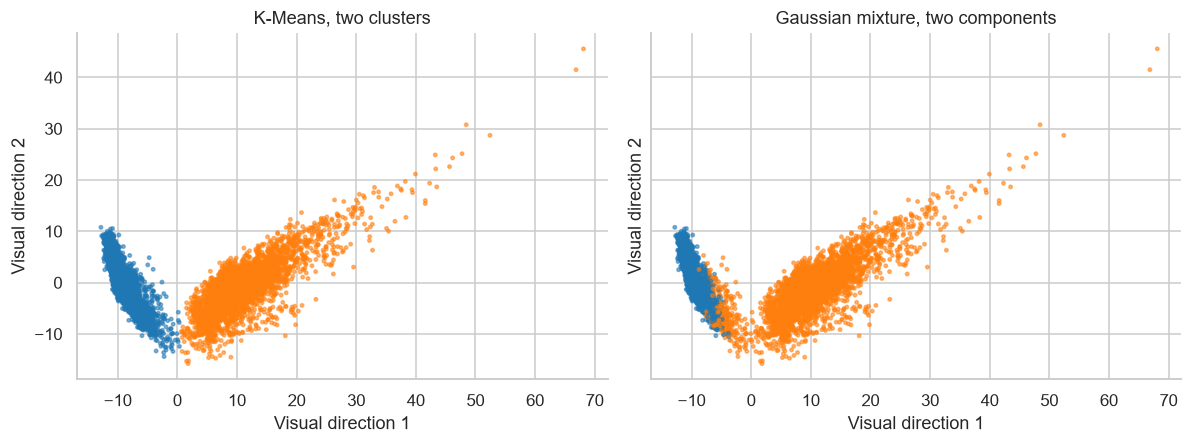

In [16]:
from sklearn.mixture import GaussianMixture
mixture_models={}; mixture_fit=[]
for covariance in ['spherical','diag']:
    for k in [2,3,6]:
        mix=GaussianMixture(n_components=k,covariance_type=covariance,reg_covar=1e-4,
                            n_init=2,max_iter=220,random_state=RANDOM_STATE).fit(X_repr)
        mixture_models[(covariance,k)]=mix
        mixture_fit.append({'covariance':covariance,'k':k,'BIC':mix.bic(X_repr),
                            'agreement_with_KMeans':adjusted_rand_score(cluster_models[k].labels_,mix.predict(X_repr))})
mixture_fit=pd.DataFrame(mixture_fit)
display(mixture_fit.round(3))
gmm_broad=mixture_models[('diag',2)]
gmm_fine=mixture_models[('diag',k_fine)]
fig,axes=plt.subplots(1,2,figsize=(11,4.2),sharex=True,sharey=True)
for ax,ids,title in [(axes[0],cluster_broad,'K-Means, two clusters'),
                     (axes[1],gmm_broad.predict(X_repr),'Gaussian mixture, two components')]:
    ax.scatter(view_train[:,0],view_train[:,1],c=ids,s=5,cmap='tab10',vmin=0,vmax=9,alpha=.55,rasterized=True)
    ax.set(xlabel='Visual direction 1',ylabel='Visual direction 2',title=title)
plt.tight_layout();plt.show()

**Interpretation.** The two visualisations allow a direct examination of where cluster-shape assumptions lead to different assignments. The adjusted Rand index quantifies agreement between the partitions, while BIC compares Gaussian mixture specifications on a common dataset. A mixture with better likelihood-based fit need not correspond more closely to supplied activity labels, nor is it automatically a better description of meaningful human movement. The interpretation should address which regions are reassigned and whether the broad organisation is preserved.

### 5.4.1 Membership uncertainty in the mixture representation

A Gaussian mixture assigns posterior probabilities rather than only hard labels. We examine the distribution of maximum posterior probability, avoiding a claim that posterior confidence alone measures physical ambiguity; it depends on covariance assumptions and fitted model calibration.

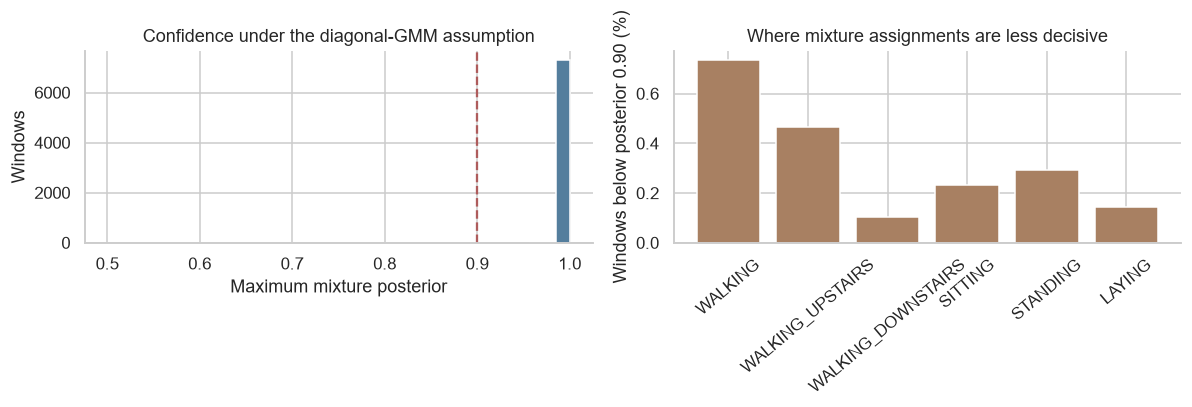

Overall share below posterior 0.90: 0.3%


In [17]:
mix_prob = gmm_fine.predict_proba(X_repr)
max_post = mix_prob.max(axis=1)
uncertain = max_post < 0.90
fig,axes=plt.subplots(1,2,figsize=(11,3.7))
axes[0].hist(max_post,bins=35,color='#547e9d')
axes[0].axvline(.90,color='#ae5c5c',ls='--')
axes[0].set(xlabel='Maximum mixture posterior',ylabel='Windows',title='Confidence under the diagonal-GMM assumption')
uncertain_rates=pd.DataFrame({'activity':meta_train.activity,'uncertain':uncertain}).groupby('activity').uncertain.mean().reindex(ACTIVITIES)*100
axes[1].bar(ACTIVITIES,uncertain_rates,color='#a88062')
axes[1].tick_params(axis='x',rotation=40)
axes[1].set(ylabel='Windows below posterior 0.90 (%)',title='Where mixture assignments are less decisive')
plt.tight_layout();plt.show()
print(f'Overall share below posterior 0.90: {uncertain.mean():.1%}')

## 5.5 Ward hierarchy and nested substructure

Ward linkage is fitted to a **uniform random sample of training windows** for tractability (not a participant-balanced sample). The dendrogram displays the actual final merges, before the corresponding scatterplots. A prominent late merge supports a coarse division under Ward's criterion, but does not demonstrate a unique true hierarchy.

,k,agreement_with_KMeans
0,2,0.980
1,3,0.858
2,6,0.529


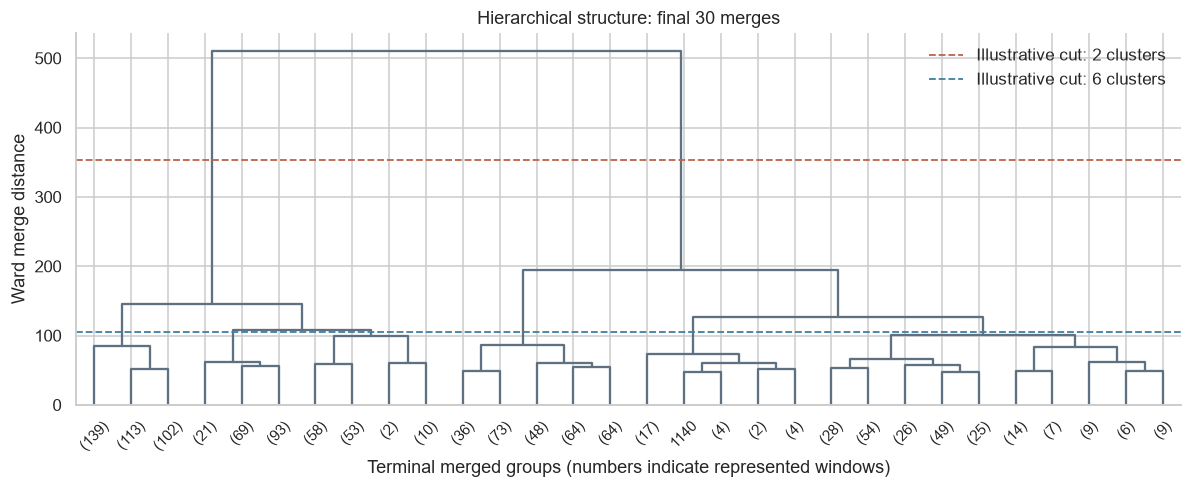

Last / preceding merge height: 2.62


In [18]:
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
ward_n=min(1200,len(X_repr))
idx_ward=np.random.default_rng(RANDOM_STATE+7).choice(len(X_repr),size=ward_n,replace=False)
ward_linkage=linkage(X_repr[idx_ward],method='ward')
ward_labels={k:fcluster(ward_linkage,k,criterion='maxclust')-1 for k in [2,3,6]}
ward_summary=pd.DataFrame([{'k':k,'agreement_with_KMeans':adjusted_rand_score(cluster_models[k].labels_[idx_ward],lab)}
                           for k,lab in ward_labels.items()])
display(ward_summary.round(3))
fig,ax=plt.subplots(figsize=(11,4.6))
dendrogram(ward_linkage,truncate_mode='lastp',p=30,show_leaf_counts=True,
           color_threshold=0,above_threshold_color='#5f7180',ax=ax)
for k,colour in [(2,'#bd654d'),(6,'#4380a4')]:
    h=(ward_linkage[-k,2]+ward_linkage[-(k-1),2])/2
    ax.axhline(h,ls='--',lw=1.2,color=colour,label=f'Illustrative cut: {k} clusters')
ax.set(xlabel='Terminal merged groups (numbers indicate represented windows)',
       ylabel='Ward merge distance',title='Hierarchical structure: final 30 merges')
ax.legend(frameon=False);plt.tight_layout();plt.show()
print('Last / preceding merge height:',round(float(ward_linkage[-1,2]/max(ward_linkage[-2,2],1e-12)),2))

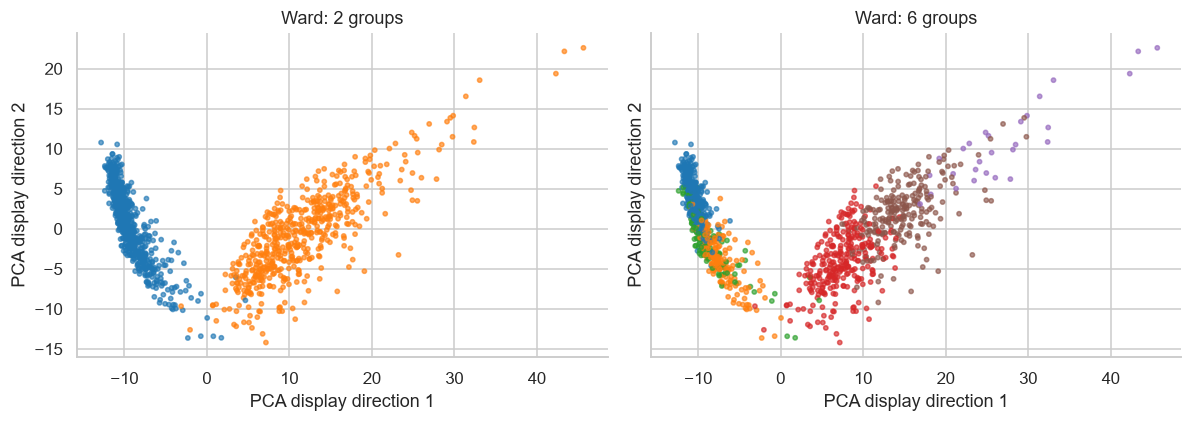

In [19]:
fig,axes=plt.subplots(1,2,figsize=(11,4),sharex=True,sharey=True)
for ax,lab,k in [(axes[0],ward_labels[2],2),(axes[1],ward_labels[6],6)]:
    ax.scatter(view_train[idx_ward,0],view_train[idx_ward,1],c=lab,cmap='tab10',vmin=0,vmax=9,
               s=8,alpha=.65,rasterized=True)
    ax.set(title=f'Ward: {k} groups',xlabel='PCA display direction 1',ylabel='PCA display direction 2')
plt.tight_layout();plt.show()

### 5.5.1 Do subgroups emerge independently within the broad families?

An alternative to global six-way clustering is to fit three groups separately inside each broad region. This checks whether the apparent fine structure is naturally nested or whether the global optimisation crosses the broad split. Agreement is reported as a *negative or positive result*, rather than assuming that a hierarchical procedure must produce more meaningful clusters.

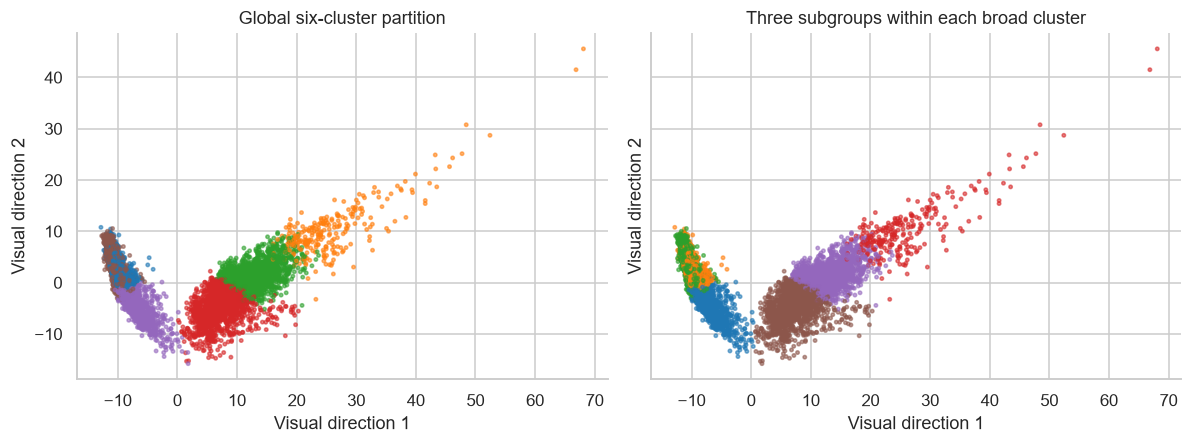

Agreement between global and two-level finer partitions: 0.99


In [20]:
family_subgroups=np.full(len(X_repr),-1,dtype=int)
for g in np.unique(cluster_broad):
    ix=np.flatnonzero(cluster_broad==g)
    km=KMeans(n_clusters=3,n_init=8,random_state=RANDOM_STATE).fit(X_repr[ix])
    family_subgroups[ix]=3*int(g)+km.labels_
fig,axes=plt.subplots(1,2,figsize=(11,4.2),sharex=True,sharey=True)
for ax,lab,title in [(axes[0],cluster_fine,'Global six-cluster partition'),
                     (axes[1],family_subgroups,'Three subgroups within each broad cluster')]:
    ax.scatter(view_train[:,0],view_train[:,1],c=lab,s=5,cmap='tab10',vmin=0,vmax=9,alpha=.58,rasterized=True)
    ax.set(xlabel='Visual direction 1',ylabel='Visual direction 2',title=title)
plt.tight_layout();plt.show()
print('Agreement between global and two-level finer partitions:',
      round(adjusted_rand_score(cluster_fine,family_subgroups),3))

**Interpretation.** A family-specific partition gives each broad group comparable attention, while global K-Means allocates clusters according to the overall variation in the dataset. Their differences demonstrate how a proposed hierarchy depends on the way the finer problem is formulated. This experiment tests for plausible specialised patterns rather than assuming the data must contain equal numbers of subgroups.

## 5.6 Stability across participants

The resampling unit is the *participant*, not an overlapping window. A cluster partition that merely reflects a few individuals is unlikely to reproduce consistently when those people are excluded. We measure agreement on the same fixed reference windows using adjusted Rand index (ARI).

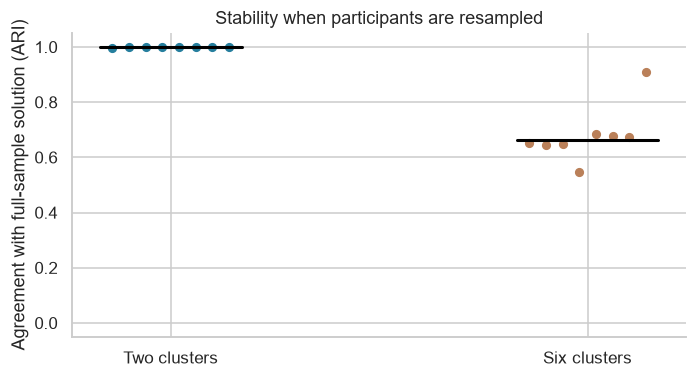

   median    min    max
k                      
2   1.000  0.996  1.000
6   0.663  0.546  0.908


In [21]:
participants=np.sort(meta_train.subject_id.unique())
reference_idx=np.random.default_rng(RANDOM_STATE+18).choice(len(X_repr),size=min(1000,len(X_repr)),replace=False)
resampling=[]
for k in [2,6]:
    ref=cluster_models[k].predict(X_repr[reference_idx])
    for seed in range(8):
        rr=np.random.default_rng(seed+900+k)
        chosen=rr.choice(participants,size=max(3,int(.8*len(participants))),replace=False)
        mask=meta_train.subject_id.isin(chosen).to_numpy()
        alt=KMeans(n_clusters=k,n_init=4,random_state=seed+55).fit(X_repr[mask])
        resampling.append({'k':k,'resample':seed,'agreement':adjusted_rand_score(ref,alt.predict(X_repr[reference_idx]))})
resampling=pd.DataFrame(resampling)
fig,ax=plt.subplots(figsize=(6.5,3.6))
for j,k in enumerate([2,6]):
    vals=resampling.loc[resampling.k==k,'agreement'].to_numpy()
    ax.scatter(np.full(len(vals),j)+np.linspace(-.14,.14,len(vals)),vals,color=['#267f9e','#ba8059'][j],s=25)
    ax.plot([j-.17,j+.17],[np.median(vals)]*2,color='black',lw=2)
ax.set(xticks=[0,1],xticklabels=['Two clusters','Six clusters'],ylabel='Agreement with full-sample solution (ARI)',
       title='Stability when participants are resampled',ylim=(-.05,1.05))
plt.tight_layout();plt.show()
print(resampling.groupby('k').agreement.agg(['median','min','max']).round(3))

**Interpretation.** The previous executed run using this 327-feature representation returned a median participant-resampling ARI of **1.000 for two clusters** and **0.663 for six**. This supports a highly reproducible broad partition but a substantially less secure finer partition. Stability does not verify that clusters correspond to activity labels or that every fine group is equally reliable. Verify the values against the rerun above; the new small-group analysis tests a distinct failure mode hidden by overall ARI.

### 5.6.1 Random initialisation and cluster-specific stability

Overall ARI can conceal a small but consequential group that disappears or splits. We compare alternative K-Means initialisations and measure the **best-matching group's Jaccard overlap** with the smallest reference fine group. This is an alignment diagnostic, not proof that the group is population-wide.

In [22]:
fine_sizes=pd.Series(cluster_fine).value_counts().sort_index()
small_ref_group=int(fine_sizes.idxmin())
small_ref_mask=(cluster_fine==small_ref_group)
seed_stability=[]
for kk in [2,3,k_fine]:
    for seed in range(8):
        fit=KMeans(n_clusters=kk,n_init=1,random_state=400+seed).fit(X_repr)
        rec={'k':kk,'seed':seed,'ARI_against_reference':adjusted_rand_score(cluster_models[kk].labels_,fit.labels_)}
        if kk==k_fine:
            rec['small_group_best_Jaccard']=max(
                np.sum(small_ref_mask & (fit.labels_==g))/max(1,np.sum(small_ref_mask | (fit.labels_==g)))
                for g in range(kk))
        seed_stability.append(rec)
seed_stability=pd.DataFrame(seed_stability)
display(seed_stability.groupby('k')[['ARI_against_reference','small_group_best_Jaccard']].agg(['median','min','max']).round(3))
# Exclude sets of people, refit and inspect the small group's match on a common reference.
small_resamples=[]
for trial in range(8):
    rr=np.random.default_rng(800+trial)
    chosen=rr.choice(participants,size=max(3,int(.80*len(participants))),replace=False)
    fit=KMeans(n_clusters=k_fine,n_init=5,random_state=trial+600).fit(
        X_repr[meta_train.subject_id.isin(chosen).to_numpy()])
    other=fit.predict(X_repr[reference_idx]); ref=cluster_fine[reference_idx]
    small_resamples.append({'trial':trial,'best_Jaccard':max(
        np.sum((ref==small_ref_group)&(other==g))/max(1,np.sum((ref==small_ref_group)|(other==g)))
        for g in range(k_fine))})
print('Small fine-group overlap after participant exclusion:')
display(pd.DataFrame(small_resamples).round(3))

ARI_against_reference               small_group_best_Jaccard            
                 median    min    max                   median  min    max
k                                                                         
2                 1.000  1.000  1.000                      NaN  NaN    NaN
3                 1.000  0.514  1.000                      NaN  NaN    NaN
6                 0.656  0.534  0.997                    0.783  0.3  0.992

Small fine-group overlap after participant exclusion:


,trial,best_Jaccard
0,0,0.487
1,1,0.484
2,2,0.897
3,3,0.974
4,4,0.923
5,5,0.675
6,6,0.864
7,7,0.826


## 5.7 Representation sensitivity

The primary physically grouped, correlation-reduced representation is compared with the full set of distinct features. No activity labels are used to choose which result is preferred. The experiment establishes how strongly the cluster boundaries depend on feature weighting.

2 clusters: ARI between selected and all-distinct representations = 0.993
6 clusters: ARI between selected and all-distinct representations = 0.612


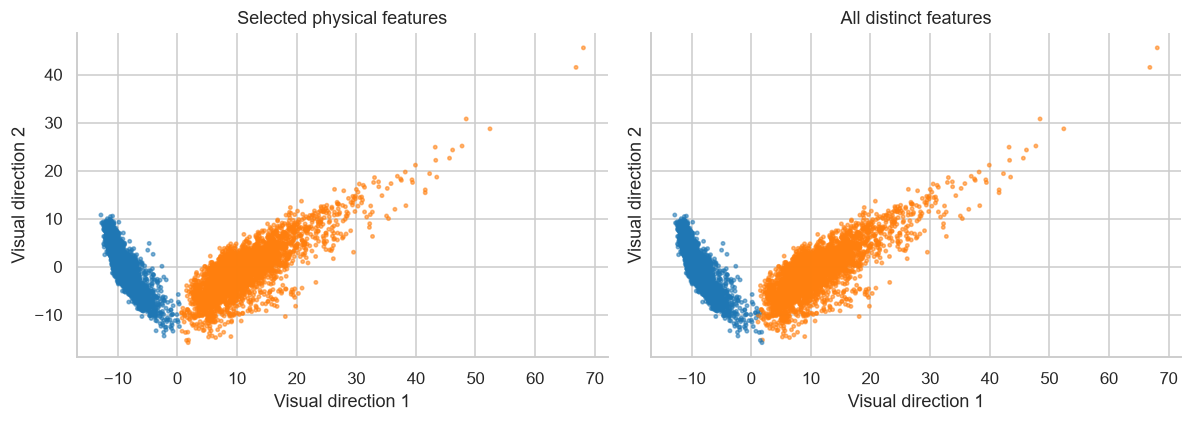

In [23]:
# Diagnostic alternative: keep distinct columns but omit correlation filtering.
X_distinct_scaled=StandardScaler().fit_transform(X_train_clean)
baseline_models={}
for k in [2,6]:
    baseline_models[k]=KMeans(n_clusters=k,n_init=6,random_state=RANDOM_STATE).fit(X_distinct_scaled)
    print(f'{k} clusters: ARI between selected and all-distinct representations = '
          f'{adjusted_rand_score(cluster_models[k].labels_,baseline_models[k].labels_):.3f}')
fig,axes=plt.subplots(1,2,figsize=(11,4),sharex=True,sharey=True)
for ax,lab,title in [(axes[0],cluster_broad,'Selected physical features'),
                     (axes[1],baseline_models[2].labels_,'All distinct features')]:
    ax.scatter(view_train[:,0],view_train[:,1],c=lab,s=5,cmap='tab10',vmin=0,vmax=9,alpha=.55,rasterized=True)
    ax.set(title=title,xlabel='Visual direction 1',ylabel='Visual direction 2')
plt.tight_layout();plt.show()

**Interpretation.** The two panels use identical display coordinates so differences in colour assignment reflect the clustering results, not a changed projection. Strong agreement would indicate that the coarse organisation is comparatively insensitive to correlated feature selection. Disagreement at the finer resolution would restrict claims about small, distinct movement categories. Even near-identical assignments would not establish that the two representations preserve every neighbourhood or anomaly ranking.

## 5.8 Assessment of the clustering resolutions

**Decision rule for interpretation.** A coarse partition supported by separation, multiple model families and participant resampling may be described as a robust *observed structure*. Finer partitions with weak silhouette or material disagreement must remain **exploratory descriptions at a chosen resolution**—even when they expose informative physical variation. In particular, the most flag-rich fine group must be accompanied by its own stability evidence rather than inherited confidence from the two-cluster result.

In [24]:
resolution_assessment=pd.DataFrame(index=[2,3,k_fine])
resolution_assessment['silhouette']=cluster_eval.loc[resolution_assessment.index,'silhouette'].to_numpy()
resolution_assessment['participant_resampling_median_ARI']=[
    resampling.loc[resampling.k==k,'agreement'].median() if k in resampling.k.unique() else np.nan
    for k in resolution_assessment.index]
resolution_assessment['Ward_ARI']=[ward_summary.set_index('k').loc[k,'agreement_with_KMeans'] for k in resolution_assessment.index]
resolution_assessment['GMM_diag_ARI']=[mixture_fit.set_index(['covariance','k']).loc[('diag',k),'agreement_with_KMeans']
                                       for k in resolution_assessment.index]
print('Decision evidence (missing resampling entries were not measured, not assumed):')
display(resolution_assessment.round(3))

Decision evidence (missing resampling entries were not measured, not assumed):


,silhouette,participant_resampling_median_ARI,Ward_ARI,GMM_diag_ARI
2,0.307,1.000,0.980,0.818
3,0.259,NaN,0.858,0.635
6,0.076,0.663,0.529,0.467


## 5.9 Physical interpretation of the observed structure

Once methodological strength is established, the feature distributions can be interpreted. We inspect both the broad divisions and the exploratory finer groups, retaining **raw engineered feature values** where sensor meaning matters. Multiple physical families are represented; no single feature is assumed to fully explain a multivariate cluster.

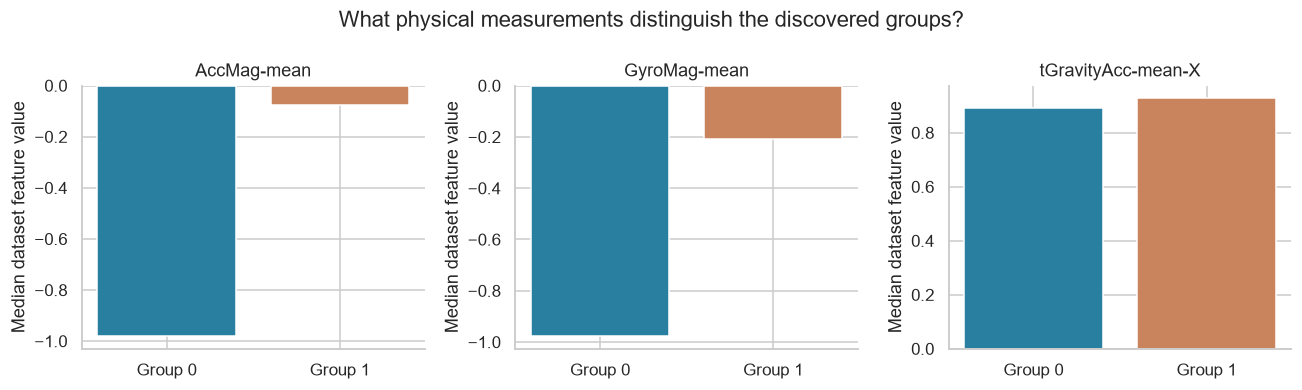

In [25]:
# Direct physical interpretation using actual engineered measurements.
phys_selected=[f for f in ['tBodyAccMag-mean()','tBodyGyroMag-mean()','tGravityAcc-mean()-X'] if f in X_train_raw.columns]
if not phys_selected: phys_selected=selected_names[:3]
profile=X_train_raw[phys_selected].groupby(cluster_broad).median()
fig,axes=plt.subplots(1,len(phys_selected),figsize=(12,3.6))
for ax,f in zip(np.ravel(axes),phys_selected):
    ax.bar([f'Group {i}' for i in profile.index],profile[f],color=['#287f9f','#c9845d'][:len(profile)])
    ax.set(title=f.replace('tBody','').replace('()',''),ylabel='Median dataset feature value')
plt.suptitle('What physical measurements distinguish the discovered groups?')
plt.tight_layout();plt.show()

**Interpretation.** The original findings associated the dominant broad partition chiefly with movement intensity, while certain finer partitions reflected posture and within-movement differences. The present figure tests those same physical distinctions after the representation change. Median differences should be interpreted alongside the distributions: a difference in the average or median does not imply non-overlapping measurements for individual windows.

### 5.9.1 Distributions within the finer clusters

For the six-cluster exploratory partition, we inspect feature distributions rather than relying only on average cluster profiles. Overlap between distributions matters because a pair of clusters can have different typical values while sharing many observations.

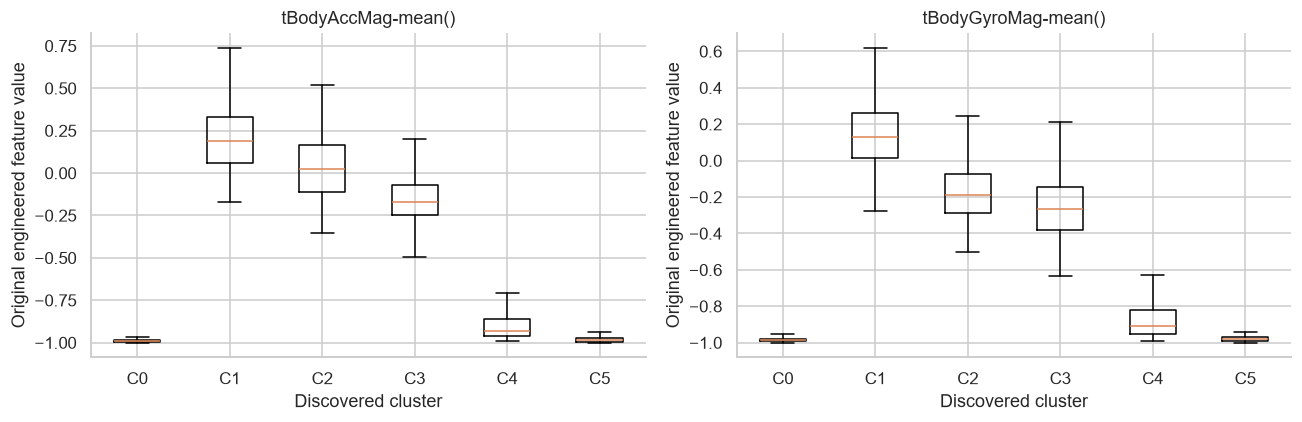

In [26]:
feature_fine=[f for f in ['tBodyAccMag-mean()','tBodyGyroMag-mean()'] if f in X_train_raw.columns]
if not feature_fine: feature_fine=list(X_train_raw.columns[:2])
fig,axes=plt.subplots(1,len(feature_fine),figsize=(12,4),sharex=False)
for ax,f in zip(np.atleast_1d(axes),feature_fine):
    values=[X_train_raw.loc[cluster_fine==g,f].to_numpy() for g in np.unique(cluster_fine)]
    ax.boxplot(values,tick_labels=[f'C{g}' for g in np.unique(cluster_fine)],showfliers=False)
    ax.set(xlabel='Discovered cluster',ylabel='Original engineered feature value',title=f)
plt.tight_layout();plt.show()

**Interpretation.** Differences in the location and spread of these distributions help distinguish clusters that are physically meaningful from partitions arising largely through subtle combinations of correlated features. The figure also exposes where clusters overlap on an individual measurement, even when the multivariate algorithm separates them using several features jointly.

### 5.9.2 Multisensor profile of the exploratory fine groups

A profile across acceleration, jerk, gyroscope and gravity summarises how each fine group differs on physically interpretable measurements. For cross-feature comparability *only in the heatmap*, each feature's values are standardised across training windows; this does not replace the raw-value plots above.

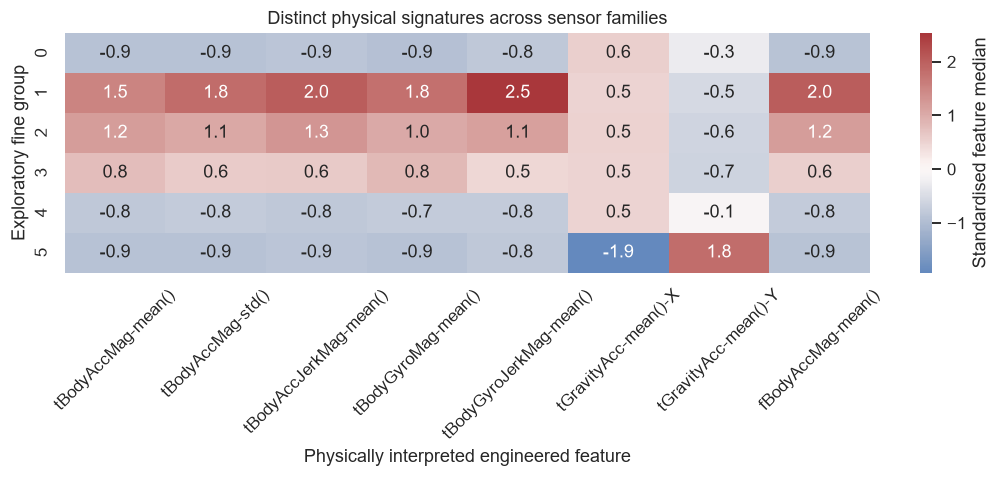

In [27]:
physical_candidates=[
    'tBodyAccMag-mean()','tBodyAccMag-std()','tBodyAccJerkMag-mean()',
    'tBodyGyroMag-mean()','tBodyGyroJerkMag-mean()',
    'tGravityAcc-mean()-X','tGravityAcc-mean()-Y',
    'fBodyAccMag-mean()','fBodyGyroMag-mean()'
]
physical_candidates=[f for f in physical_candidates if f in X_train_raw.columns]
if len(physical_candidates)>=2:
    z_phys=(X_train_raw[physical_candidates]-X_train_raw[physical_candidates].mean())/X_train_raw[physical_candidates].std(ddof=0).replace(0,1)
    group_profile=z_phys.groupby(pd.Series(cluster_fine,index=z_phys.index)).median()
    fig,ax=plt.subplots(figsize=(max(10,len(physical_candidates)*1.06),4.5))
    sns.heatmap(group_profile,center=0,cmap='vlag',annot=True,fmt='.1f',ax=ax,
                cbar_kws={'label':'Standardised feature median'})
    ax.set(xlabel='Physically interpreted engineered feature',ylabel='Exploratory fine group',
           title='Distinct physical signatures across sensor families')
    ax.tick_params(axis='x',rotation=45)
    plt.tight_layout();plt.show()

## 5.10 Relationship to activity categories and participants

Recorded activity labels are used **only after** the discovery and robustness assessment to interpret which known activities occupy the observed groups. Participant composition is inspected separately to detect whether a fine group may be partly person-associated.

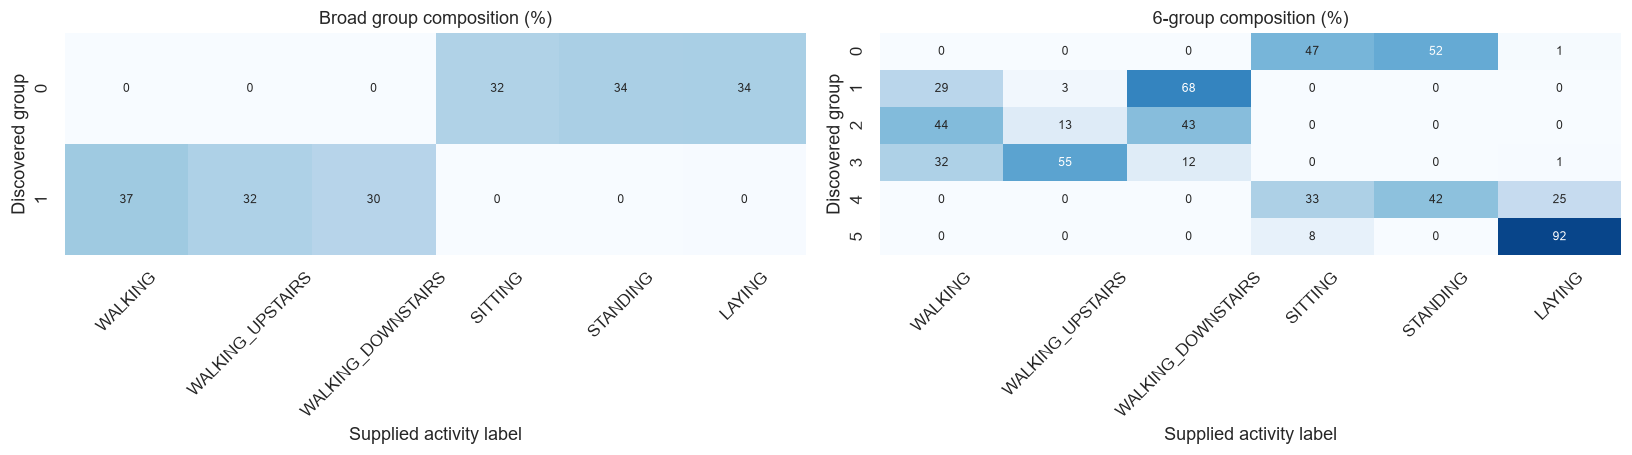

In [28]:
# Two label-composition views, same method of reading both.
def plot_cluster_activity(ax,cluster_ids,activity,title):
    rows=pd.crosstab(pd.Series(cluster_ids,name='Discovered group'),pd.Series(activity,name='Known activity'),normalize='index')
    rows=rows.reindex(columns=ACTIVITIES,fill_value=0)
    sns.heatmap(rows*100,ax=ax,cmap='Blues',vmin=0,vmax=100,annot=True,fmt='.0f',
                cbar=False,annot_kws={'fontsize':8})
    ax.set(title=title,xlabel='Supplied activity label',ylabel='Discovered group')
    ax.tick_params(axis='x',labelrotation=45)
    return rows
fig,axes=plt.subplots(1,2,figsize=(15,4.3))
activity_mix_broad=plot_cluster_activity(axes[0],cluster_broad,meta_train.activity,'Broad group composition (%)')
activity_mix_fine=plot_cluster_activity(axes[1],cluster_fine,meta_train.activity,f'{k_fine}-group composition (%)')
plt.tight_layout();plt.show()

**Interpretation.** The original analysis found strong correspondence between the broad clusters and recorded moving/still activities, with greater mixing among finer groups. Overlap at fine resolution suggests that the cluster boundaries may reflect movement intensity, posture and individual characteristics jointly rather than a one-to-one activity taxonomy.

In [29]:
# Assess whether clusters are associated with participant identity, rather than naming groups after people.
print('Agreement of fine groups with supplied activities (AMI):',
      round(adjusted_mutual_info_score(meta_train.activity,cluster_fine),3))
print('Agreement of fine groups with participant identity (AMI):',
      round(adjusted_mutual_info_score(meta_train.subject_id,cluster_fine),3))
cluster_subject_share=pd.crosstab(pd.Series(cluster_fine),meta_train.subject_id,normalize='index').max(axis=1)
print('Largest single-participant share in each fine group:',
      {int(k):f'{v:.1%}' for k,v in cluster_subject_share.items()})
print('Interpretation: high subject concentration would limit claims of population-wide movement categories.')

# RQ1 exports: cluster assignments and fitted models; no hidden re-clustering downstream.
results_train=meta_train.copy()
results_train['cluster_broad']=cluster_broad
results_train['cluster_fine']=cluster_fine
RQ1={'broad_model':model_broad,'fine_model':model_fine,'fine_k':k_fine,
     'broad_labels':cluster_broad,'fine_labels':cluster_fine,
     'gmm_broad':gmm_broad,'gmm_fine':gmm_fine}

# How consistently does each fine group belong to one of the two broad groups?
nesting=pd.crosstab(pd.Series(cluster_fine,name='fine'),pd.Series(cluster_broad,name='broad'),normalize='index')
print('Fraction of each finer group belonging to its dominant broad group:')
for group,share in nesting.max(axis=1).items():
    print(f'  Fine group {group}: {share:.1%}')
print('This is evidence about nesting; a low share means the finer grouping crosses the broad boundary.')

print('RQ1 hand-off created: broad and finer cluster labels for every training window.')

Agreement of fine groups with supplied activities (AMI): 0.549
Agreement of fine groups with participant identity (AMI): 0.062
Largest single-participant share in each fine group: {0: '7.2%', 1: '30.0%', 2: '9.4%', 3: '12.2%', 4: '9.4%', 5: '9.1%'}
Interpretation: high subject concentration would limit claims of population-wide movement categories.
Fraction of each finer group belonging to its dominant broad group:
  Fine group 0: 100.0%
  Fine group 1: 100.0%
  Fine group 2: 100.0%
  Fine group 3: 99.9%
  Fine group 4: 99.7%
  Fine group 5: 100.0%
This is evidence about nesting; a low share means the finer grouping crosses the broad boundary.
RQ1 hand-off created: broad and finer cluster labels for every training window.


### 5.10.1 Label overlap is not the same as a cluster-count criterion

A two-cluster moving/still division can be strong while receiving a modest ARI against six activity labels. That comparison has a structural ceiling: two groups cannot recover six distinct labels. The activity-composition plots should therefore be read as *interpretation*, not optimisation targets. Likewise, any high participant concentration in a fine group motivates the individual analysis in RQ3 rather than proving a distinctive gait.

## 5.11 RQ1's initial cluster–anomaly investigation

The RQ1 team also investigated whether unusual windows are **scattered** or correspond to discoverable structure. We retain this analysis rather than reclassifying it as RQ3. Two global, PCA-based scores distinguish (i) departure from a reduced linear subspace and (ii) extreme positions *within* that subspace. The resulting shortlists are compared with the RQ1 clusters. These are **different anomaly definitions**, not ground-truth labels or a replacement for RQ2's explanatory study.

PCA retained variance: 0.828
Agreement of reconstruction and PCA-distance shortlists (Jaccard): 0.521


reconstruction      PCA_distance     
                mean  sum         mean  sum
group                                      
0              0.003    5        0.001    1
1              0.754  196        0.608  158
2              0.062   88        0.070   99
3              0.011   17        0.027   44
4              0.045   55        0.051   63
5              0.006    7        0.003    3

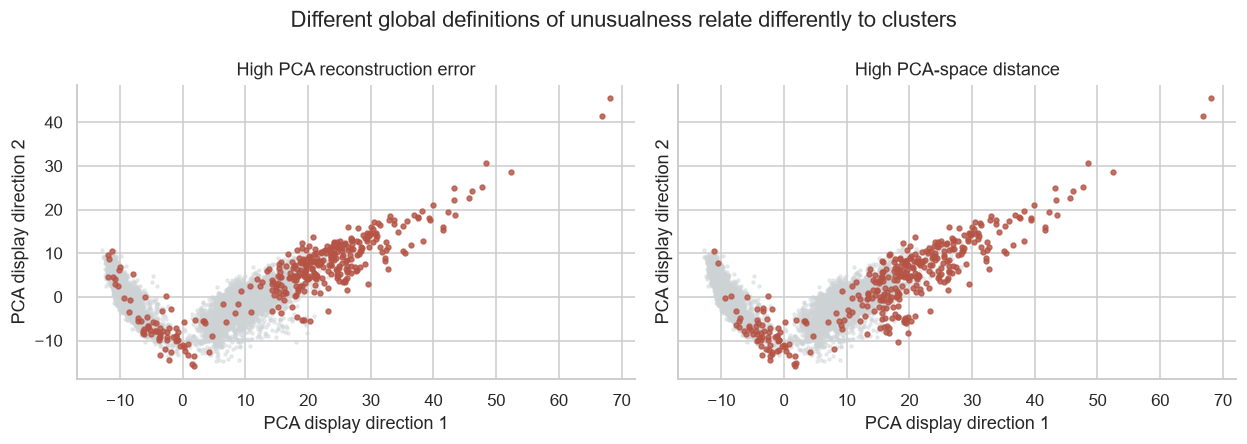

In [30]:
# PCA anomaly scores on the same analysis matrix, trained without activity labels.
PCA_ANOM_COMPONENTS=min(50,X_repr.shape[1],len(X_repr)-1)
pca_anom=PCA(n_components=PCA_ANOM_COMPONENTS,svd_solver='randomized',random_state=RANDOM_STATE).fit(X_repr)
z_pca=pca_anom.transform(X_repr)
score_reconstruction=np.mean((X_repr-pca_anom.inverse_transform(z_pca))**2,axis=1)
score_pca_distance=np.sqrt(np.sum((z_pca**2)/np.maximum(pca_anom.explained_variance_,1e-9),axis=1))
flag_reconstruction=score_reconstruction>=np.quantile(score_reconstruction,.95)
flag_pca_distance=score_pca_distance>=np.quantile(score_pca_distance,.95)
print('PCA retained variance:',round(float(pca_anom.explained_variance_ratio_.sum()),3))
print('Agreement of reconstruction and PCA-distance shortlists (Jaccard):',
      round(np.logical_and(flag_reconstruction,flag_pca_distance).sum()/
            max(1,np.logical_or(flag_reconstruction,flag_pca_distance).sum()),3))
cluster_pca=pd.DataFrame({'group':cluster_fine,'reconstruction':flag_reconstruction,
                          'PCA_distance':flag_pca_distance}).groupby('group').agg(['mean','sum'])
display(cluster_pca.round(3))
fig,axes=plt.subplots(1,2,figsize=(11.5,4.1),sharex=True,sharey=True)
for ax,flags,title in zip(axes,[flag_reconstruction,flag_pca_distance],
                          ['High PCA reconstruction error','High PCA-space distance']):
    ax.scatter(view_train[:,0],view_train[:,1],c='#cdd2d5',s=4,alpha=.4,rasterized=True)
    ax.scatter(view_train[flags,0],view_train[flags,1],c='#b55344',s=10,alpha=.78,rasterized=True)
    ax.set(xlabel='PCA display direction 1',ylabel='PCA display direction 2',title=title)
plt.suptitle('Different global definitions of unusualness relate differently to clusters')
plt.tight_layout();plt.show()

### Discussion of RQ1

The interpretation should distinguish *levels of evidence*. The broad movement division is supported when independent criteria and participant resampling agree; finer groups can capture physically distinctive substructure yet vary under representation and model assumptions. The Ward hierarchy and within-family analysis indicate whether a nested description is informative or merely an artefact of a chosen partition. The PCA anomaly comparison demonstrates that cluster membership and 'unusualness' are related but not identical, and that the interpretation changes with the score used. The number of recorded activities is not used to decide how many natural groups exist.

**Result to resolve after Run All:** report the selected broad structure, the relative stability of finer resolutions, the physical signature and participant composition of any small group, and which anomaly definition highlights it. Do not claim that a six-way grouping is uniquely validated simply because it is informative.

# 6. RQ2 — Movement Variability and Apparent Unusualness

**Investigators: Youssef and Sushanth; incorporating the original variability and physical EDA.** RQ2 tests a two-part explanation: some movements may exhibit greater variation, and this variation may make them disproportionately unusual to **global** detectors. We test within-person variability, compare reference populations and detectors, and intervene on movement spread. The clustering reference comes **from RQ1**; it is not independently chosen again.

## 6.1 Variation within and between participants

An activity can be broadly distributed because each person varies considerably *within that activity* or because people's typical measurements differ. These are distinct explanations. We decompose squared multivariate distance into participant-centred within-group and between-participant components, using the common feature matrix; then examine how consistently the highest-variation activity appears across participants. This is a descriptive decomposition, not a biological causal estimate.

,n_windows,total_spread,within_spread,between_spread,between_share
activity,,,,,
WALKING,1226,233.949,134.825,99.124,0.424
WALKING_UPSTAIRS,1073,214.671,136.206,78.464,0.366
WALKING_DOWNSTAIRS,986,380.321,246.477,133.845,0.352
SITTING,1286,140.128,125.677,14.451,0.103
STANDING,1374,120.958,105.771,15.187,0.126
LAYING,1407,174.343,141.377,32.966,0.189


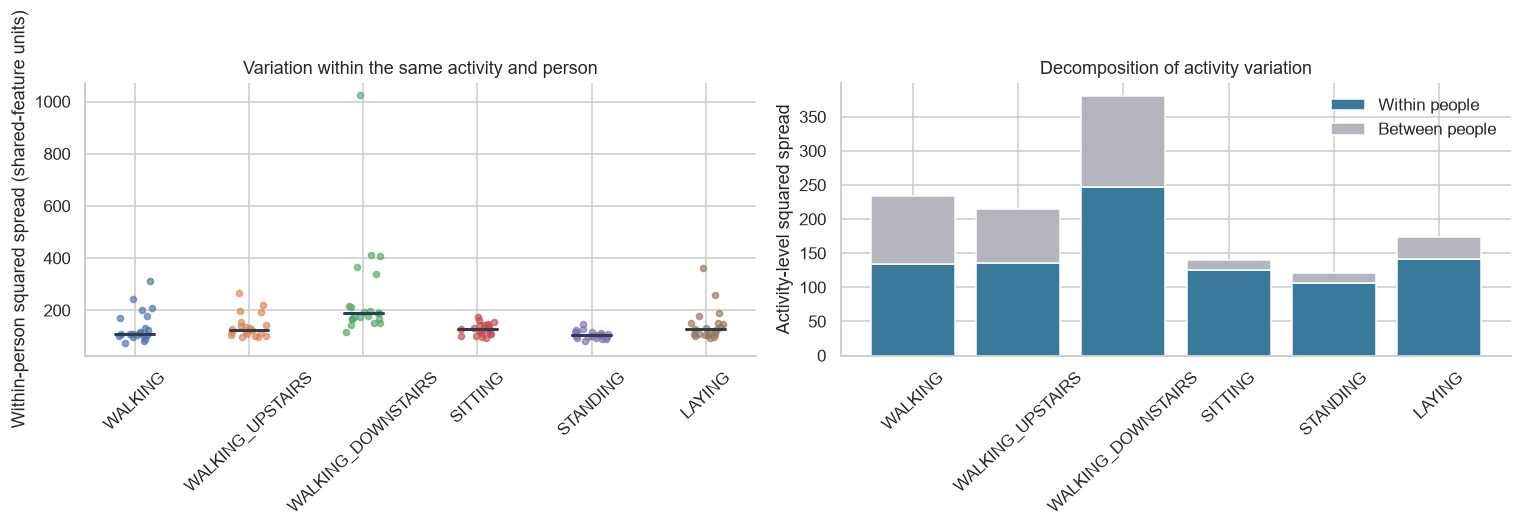

Activity with greatest within-person spread (participant counts):


,participants
WALKING,1
WALKING_UPSTAIRS,0
WALKING_DOWNSTAIRS,18
SITTING,0
STANDING,0
LAYING,2


In [31]:
act_arr=meta_train.activity.to_numpy()
sub_arr=meta_train.subject_id.to_numpy()
within_person_rows=[]
variance_decomp=[]
for activity in ACTIVITIES:
    amask=(act_arr==activity)
    block=X_repr[amask]; ids=sub_arr[amask]
    mu=block.mean(axis=0)
    total=float(np.square(block-mu).sum())
    within_sum=0.
    for sid in np.unique(ids):
        obs=block[ids==sid]
        ss=float(np.square(obs-obs.mean(axis=0)).sum())
        within_sum+=ss
        within_person_rows.append({'activity':activity,'subject_id':int(sid),'windows':len(obs),
                                   'within_spread':ss/max(len(obs),1)})
    variance_decomp.append({'activity':activity,'n_windows':len(block),
                            'total_spread':total/max(len(block),1),
                            'within_spread':within_sum/max(len(block),1),
                            'between_spread':(total-within_sum)/max(len(block),1),
                            'between_share':(total-within_sum)/max(total,1e-12)})
within_person_spread=pd.DataFrame(within_person_rows)
variation_decomp=pd.DataFrame(variance_decomp).set_index('activity').reindex(ACTIVITIES)
display(variation_decomp.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for j,activity in enumerate(ACTIVITIES):
    s=within_person_spread.loc[within_person_spread.activity==activity,'within_spread'].to_numpy()
    axes[0].scatter(np.full(len(s),j)+np.random.default_rng(RANDOM_STATE+j).uniform(-.16,.16,len(s)),
                    s,alpha=.65,s=16)
    axes[0].plot([j-.17,j+.17],[np.median(s)]*2,color='#2d3f4f',lw=2)
axes[0].set(xticks=np.arange(len(ACTIVITIES)),xticklabels=ACTIVITIES,
            ylabel='Within-person squared spread (shared-feature units)',title='Variation within the same activity and person')
axes[0].tick_params(axis='x',rotation=43)
pos=np.arange(len(ACTIVITIES))
axes[1].bar(pos,variation_decomp.within_spread,color='#397a9b',label='Within people')
axes[1].bar(pos,variation_decomp.between_spread,bottom=variation_decomp.within_spread,
            color='#b2b6bc',label='Between people')
axes[1].set(xticks=pos,xticklabels=ACTIVITIES,ylabel='Activity-level squared spread',
            title='Decomposition of activity variation')
axes[1].tick_params(axis='x',rotation=43)
axes[1].legend(frameon=False)
plt.tight_layout();plt.show()
wide_within=within_person_spread.pivot(index='subject_id',columns='activity',values='within_spread')
most_var=wide_within.idxmax(axis=1)
print('Activity with greatest within-person spread (participant counts):')
display(most_var.value_counts().reindex(ACTIVITIES,fill_value=0).to_frame('participants'))

**Interpretation.** This experiment directly tests whether high activity-level variation persists *within* individual participants instead of being entirely caused by differences among participants. The count of participants with each activity as their most variable must be reported alongside any activity-wide result. Between-person variation is investigated more closely in RQ3 as evidence for individual differences.

## 6.2 Defining global unusualness

For a window, the global k-NN score is the distance to its 15th-nearest **other training window** in the same representation. The highest 5% of scores are analysed as a shortlist for comparison, not asserted to be the true anomaly prevalence. RQ2 evaluates whether this global definition systematically over-represents certain activities.

In [32]:
K_NEIGHBORS=15
TOP_FRAC=.05
nn_global=NearestNeighbors(n_neighbors=K_NEIGHBORS+1,n_jobs=-1).fit(X_repr)
train_dist,train_neighbors=nn_global.kneighbors(X_repr)
score_global=train_dist[:,K_NEIGHBORS]
threshold_global=float(np.quantile(score_global,1-TOP_FRAC))
flag_global=score_global>=threshold_global

def jaccard(a,b):
    a=np.asarray(a,dtype=bool); b=np.asarray(b,dtype=bool)
    return np.logical_and(a,b).sum()/max(1,np.logical_or(a,b).sum())

print('Number of globally high-scoring windows:',int(flag_global.sum()),
      '| training windows:',len(X_repr),'| threshold:',round(threshold_global,3))

Number of globally high-scoring windows: 368 | training windows: 7352 | threshold: 19.875


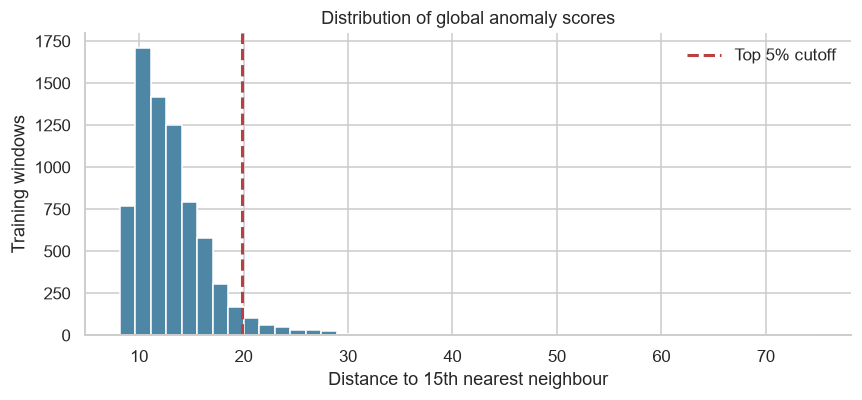

In [33]:
fig,ax=plt.subplots(figsize=(8,3.8))
ax.hist(score_global,bins=45,color='#4e86a5')
ax.axvline(threshold_global,color='#b84043',ls='--',lw=2,label='Top 5% cutoff')
ax.set(xlabel='Distance to 15th nearest neighbour',ylabel='Training windows',
       title='Distribution of global anomaly scores')
ax.legend(frameon=False)
plt.tight_layout();plt.show()

**Interpretation.** The score distribution shows whether the upper tail consists of a gradual extension of ordinary variation or a small number of particularly distant observations. A percentile cutoff necessarily produces a shortlist even without a natural gap in the score distribution. Consequently, the locations and characteristics of flagged observations are more informative than the count alone.

### 6.2.1 Where the global high scores occur

We display flagged windows on the same PCA map used for the clustering analysis. Cluster colours indicate RQ1's finer partition; red outlines identify observations with globally high anomaly scores. This shows whether flagged windows lie at the periphery, between regions, or within recognisable groups.

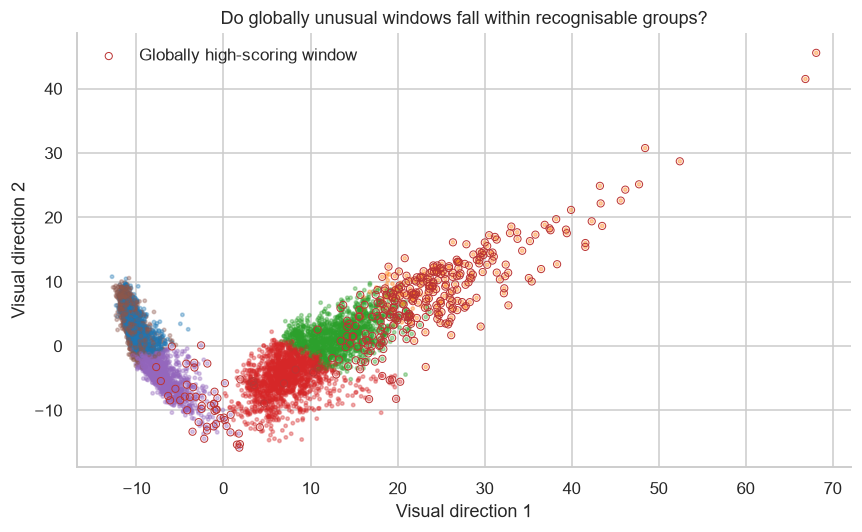

In [34]:
fig,ax=plt.subplots(figsize=(8,5))
ax.scatter(view_train[:,0],view_train[:,1],c=cluster_fine,cmap='tab10',vmin=0,vmax=9,s=5,alpha=.35,rasterized=True)
ax.scatter(view_train[flag_global,0],view_train[flag_global,1],facecolors='none',edgecolors='#bb3434',
           s=22,linewidths=.65,label='Globally high-scoring window',rasterized=True)
ax.set(xlabel='Visual direction 1',ylabel='Visual direction 2',
       title='Do globally unusual windows fall within recognisable groups?')
ax.legend(frameon=False,loc='best');plt.tight_layout();plt.show()

**Interpretation.** In the preceding 327-feature execution, a small exploratory fine group carried a disproportionate share of global k-NN flags. The plotted pattern connects the RQ1 movement structure to RQ2's operational definition of unusualness; it does not imply that the small group is stable across methods or that its windows are physical errors. The group-specific percentages are computed below and must be interpreted alongside RQ1's robustness evidence.

In [35]:
cluster_flags=pd.DataFrame({'group':cluster_fine,'flag':flag_global}).groupby('group').agg(windows=('flag','size'),flagged=('flag','sum'),flag_rate=('flag','mean'))
print('Global flags by discovered group:')
display(cluster_flags.style.format({'flag_rate':'{:.1%}'}))

Global flags by discovered group:


,windows,flagged,flag_rate
group,,,
0,1669,0,0.0%
1,260,208,80.0%
2,1420,94,6.6%
3,1616,21,1.3%
4,1224,45,3.7%
5,1163,0,0.0%


**Cluster-level interpretation.** Differences in flag rates indicate whether the global distance rule treats certain discovered groups as less typical than others. A group that is small or diffuse may generate more high distances without containing erroneous observations. The important comparison is between global and within-group unusualness, developed in Section 6.4.

## 6.3 Do anomaly detectors agree?

We compare detectors with different reference assumptions: global k-NN and Isolation Forest, local density (LOF), distance to RQ1's nearest fine-cluster centre, and distance standardised by the reference cluster's typical radius. We also retain the group-relative k-NN score below. The key question is **which movements and observations change status**, not how many detectors can be listed.

In [36]:
iforest=IsolationForest(n_estimators=160,max_samples='auto',random_state=RANDOM_STATE,n_jobs=-1).fit(X_repr)
score_iforest=-iforest.score_samples(X_repr)
lof=LocalOutlierFactor(n_neighbors=20,novelty=True,n_jobs=-1).fit(X_repr)
score_lof=-lof.negative_outlier_factor_
flags_iforest=score_iforest>=np.quantile(score_iforest,1-TOP_FRAC)
flags_lof=score_lof>=np.quantile(score_lof,1-TOP_FRAC)
print('Jaccard overlap with global k-NN flags:')
print('  Isolation Forest:',round(jaccard(flag_global,flags_iforest),3))
print('  Local Outlier Factor:',round(jaccard(flag_global,flags_lof),3))
print('  Isolation Forest vs LOF:',round(jaccard(flags_iforest,flags_lof),3))

Jaccard overlap with global k-NN flags:
  Isolation Forest: 0.625
  Local Outlier Factor: 0.256
  Isolation Forest vs LOF: 0.166


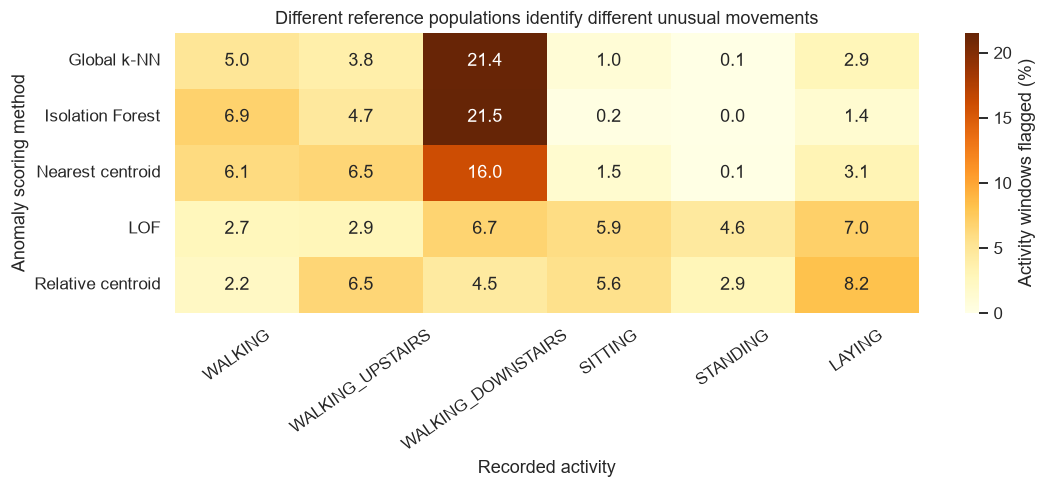

Detector shortlist overlap (Jaccard):


,Global k-NN,Isolation Forest,Nearest centroid,LOF,Relative centroid
Global k-NN,1.00,0.62,0.66,0.26,0.23
Isolation Forest,0.62,1.00,0.53,0.17,0.17
Nearest centroid,0.66,0.53,1.00,0.25,0.34
LOF,0.26,0.17,0.25,1.00,0.35
Relative centroid,0.23,0.17,0.34,0.35,1.00


Walking-downstairs rate (%) under participant resampling:


,2.5%,median,97.5%
method,,,
Global k-NN,10.6,21.2,35.6
Isolation Forest,10.4,21.3,36.7
LOF,3.2,6.5,11.4
Nearest centroid,7.8,16.0,27.3
Relative centroid,1.7,4.4,8.3


In [37]:
centroid_dist=model_fine.transform(X_repr)
score_nearest_centroid=centroid_dist.min(axis=1)
within_centroid=centroid_dist[np.arange(len(X_repr)),cluster_fine]
centroid_scale=pd.Series(within_centroid).groupby(cluster_fine).median().replace(0,1e-9)
score_rel_centroid=within_centroid/centroid_scale.reindex(cluster_fine).to_numpy()
all_detector_scores={
    'Global k-NN':score_global,
    'Isolation Forest':score_iforest,
    'Nearest centroid':score_nearest_centroid,
    'LOF':score_lof,
    'Relative centroid':score_rel_centroid
}
all_detector_flags={name:np.asarray(score)>=np.quantile(score,.95)
                    for name,score in all_detector_scores.items()}
detector_rates=pd.DataFrame({name:pd.Series(flags).groupby(meta_train.activity).mean().reindex(ACTIVITIES)*100
                             for name,flags in all_detector_flags.items()})
fig,ax=plt.subplots(figsize=(10.3,4.6))
sns.heatmap(detector_rates.T,annot=True,fmt='.1f',cmap='YlOrBr',vmin=0,
            cbar_kws={'label':'Activity windows flagged (%)'},ax=ax)
ax.set(xlabel='Recorded activity',ylabel='Anomaly scoring method',
       title='Different reference populations identify different unusual movements')
ax.tick_params(axis='x',rotation=35)
plt.tight_layout();plt.show()
print('Detector shortlist overlap (Jaccard):')
display(pd.DataFrame({a:{b:jaccard(all_detector_flags[a],all_detector_flags[b])
                              for b in all_detector_flags} for a in all_detector_flags}).round(2))
# Subject-bootstrap uncertainty for each method's activity-specific rate, not individual windows.
rng_boot=np.random.default_rng(RANDOM_STATE+160)
by_subject={sid:np.flatnonzero(sub_arr==sid) for sid in participants}
bootstrap_rate=[]
for _ in range(300):
    draw=rng_boot.choice(participants,size=len(participants),replace=True)
    idx=np.concatenate([by_subject[sid] for sid in draw])
    for method,flags in all_detector_flags.items():
        dm=(act_arr[idx]=='WALKING_DOWNSTAIRS')
        if dm.any():
            bootstrap_rate.append({'method':method,'downstairs_rate':float(flags[idx][dm].mean())})
bootstrap_rate=pd.DataFrame(bootstrap_rate)
ci=bootstrap_rate.groupby('method').downstairs_rate.quantile([.025,.5,.975]).unstack().rename(
    columns={.025:'2.5%',.5:'median',.975:'97.5%'})
print('Walking-downstairs rate (%) under participant resampling:')
display((100*ci).round(1))

**Comparison to evaluate.** If global detectors flag variable movements more frequently while relative detectors do not, unusualness depends substantially on reference scale. Disagreement is an observation about the **operational definition** of unusualness, not evidence that one detector is intrinsically correct. The bootstrap intervals resample participants as the independent units while holding the detectors fitted.

## 6.4 Group-conditional anomaly scores

The RQ1 fine partition provides a reference for scoring within discovered groups. This answers a different question from the global distance: does a window remain unusual compared with others of its *own* movement group? Since the fine partition is less stable than the broad one, we later check this dependence on the number of reference groups.

### 6.4.1 Cluster-relative k-NN scoring

A window can be globally uncommon yet typical within a distinct movement group. We therefore calculate the distance to nearby observations **within the RQ1 fine cluster** and standardise those within-group distances using robust cluster-specific reference values. The resulting contextual score answers a different question from global k-NN distance.

In [38]:
# Cluster-relative nearest-neighbour scores, scaled within each discovered cluster.
# Training reference pools, centres, and scales are frozen for Section 8 generalisation.
cluster_refs={}; score_local_raw=np.full(len(X_repr),np.nan)
local_models={}
for g in np.unique(cluster_fine):
    ix=np.flatnonzero(cluster_fine==g)
    k_eff=min(K_NEIGHBORS,len(ix)-1)
    if k_eff<1: raise ValueError('Discovered cluster too small to score within-group unusualness')
    nn=NearestNeighbors(n_neighbors=k_eff+1,n_jobs=-1).fit(X_repr[ix])
    dist=nn.kneighbors(X_repr[ix])[0][:,k_eff]
    score_local_raw[ix]=dist
    local_models[int(g)]=(nn,k_eff,ix)

cluster_refs={}
score_context=np.zeros(len(X_repr))
for g in np.unique(cluster_fine):
    ix=np.flatnonzero(cluster_fine==g)
    med=float(np.median(score_local_raw[ix]))
    mad=float(median_abs_deviation(score_local_raw[ix],scale='normal'))
    if mad<1e-8: mad=float(np.std(score_local_raw[ix]))+1e-8
    cluster_refs[int(g)]=(med,mad)
    score_context[ix]=(score_local_raw[ix]-med)/mad
threshold_context=float(np.quantile(score_context,1-TOP_FRAC))
flag_context=score_context>=threshold_context
print('Number of contextual flags:',flag_context.sum(),
      'Overlap with global shortlist:',f'{jaccard(flag_global,flag_context):.1%}')
print('A context-adjusted score is relative to a discovered group; do not compare its raw numerical scale with global distances.')

results_train['score_global']=score_global
results_train['flag_global']=flag_global
results_train['score_context']=score_context
results_train['flag_context']=flag_context
results_train['score_iforest']=score_iforest
results_train['score_lof']=score_lof
RQ2={'global_model':nn_global,'global_threshold':threshold_global,'context_threshold':threshold_context,
     'local_models':local_models,'local_scales':cluster_refs,'iforest':iforest,'lof':lof}

Number of contextual flags: 368 Overlap with global shortlist: 22.5%
A context-adjusted score is relative to a discovered group; do not compare its raw numerical scale with global distances.


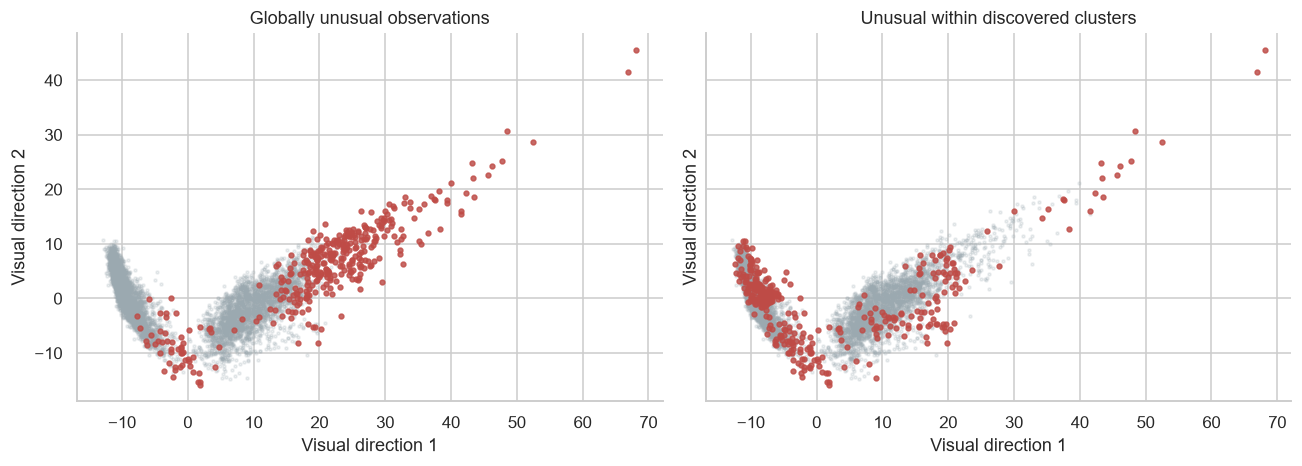

In [39]:
fig,axes=plt.subplots(1,2,figsize=(12,4.4),sharex=True,sharey=True)
for ax,flag,title in zip(axes,[flag_global,flag_context],
                         ['Globally unusual observations','Unusual within discovered clusters']):
    ax.scatter(view_train[:,0],view_train[:,1],s=4,c='#9ba9b0',alpha=.18,rasterized=True)
    ax.scatter(view_train[flag,0],view_train[flag,1],s=10,c='#bf4b46',alpha=.8,rasterized=True)
    ax.set(xlabel='Visual direction 1',ylabel='Visual direction 2',title=title)
plt.tight_layout();plt.show()

**Interpretation.** Changes in which regions contain flagged observations show the influence of the reference population. The original group found limited overlap between global and cluster-relative shortlists, consistent with many globally uncommon windows belonging to coherent smaller movement groups. This distinction is the main connection between RQ1 and RQ2. A cluster-relative score does not automatically produce a more correct detector: its validity depends on the credibility of the RQ1 clusters and the adequacy of within-cluster sample sizes.

### 6.4.2 Global versus contextual flags by activity

We now examine flag rates for the six labelled activities. Rates, rather than raw flagged counts, account for different activity sample sizes. The same activity order is retained in the global and contextual comparisons.

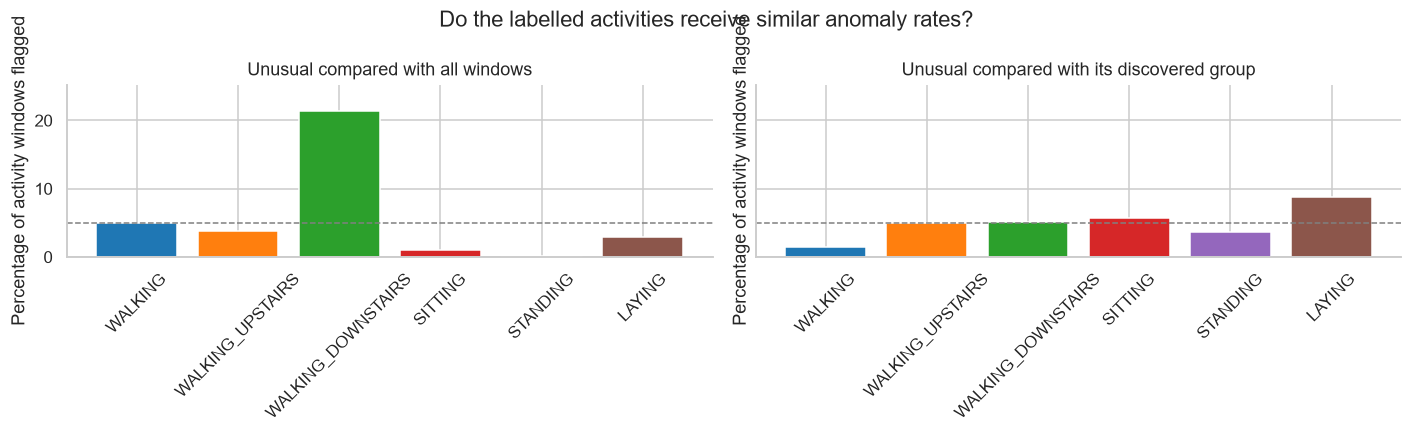

5% is the overall training shortlist rate, not an expected 5% per activity.


In [40]:
rates=pd.DataFrame({'activity':meta_train.activity,'global':flag_global,'contextual':flag_context}).groupby('activity')[['global','contextual']].mean().reindex(ACTIVITIES)*100
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,col,title in zip(axes,['global','contextual'],['Unusual compared with all windows','Unusual compared with its discovered group']):
    ax.bar(ACTIVITIES,rates[col],color=[ACTIVITY_COLORS[a] for a in ACTIVITIES]);ax.axhline(5,color='grey',ls='--',lw=1)
    ax.set(title=title,ylabel='Percentage of activity windows flagged',ylim=(0,max(15,float(rates.to_numpy().max())*1.18)))
    ax.tick_params(axis='x',labelrotation=45)
plt.suptitle('Do the labelled activities receive similar anomaly rates?')
plt.tight_layout();plt.show()
print('5% is the overall training shortlist rate, not an expected 5% per activity.')

**Interpretation.** The preceding execution showed that **walking downstairs** received the highest global k-NN flag rate (about **21.4%**) and a substantially lower contextual rate (about **5.1%**). This disparity illustrates how the reference population changes apparent unusualness. The rerun above should be checked before the numbers are reproduced in the final report; they refer to sensor-score distributions, not verified movement abnormalities.

### 6.4.3 Within-activity dispersion and global flag rates

The extent of movement variation is central to RQ2. We examine both a direct physical feature distribution and a multivariate measure of how far windows lie from their activity's typical sensor profile. The physical figure helps explain the measurement differences; the multivariate quantity checks whether that impression holds across the selected features.

C:\Users\muhat\AppData\Local\Temp\ipykernel_39856\11625165.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=activity_frame,x='activity',y='body_acc_magnitude',order=ACTIVITIES,


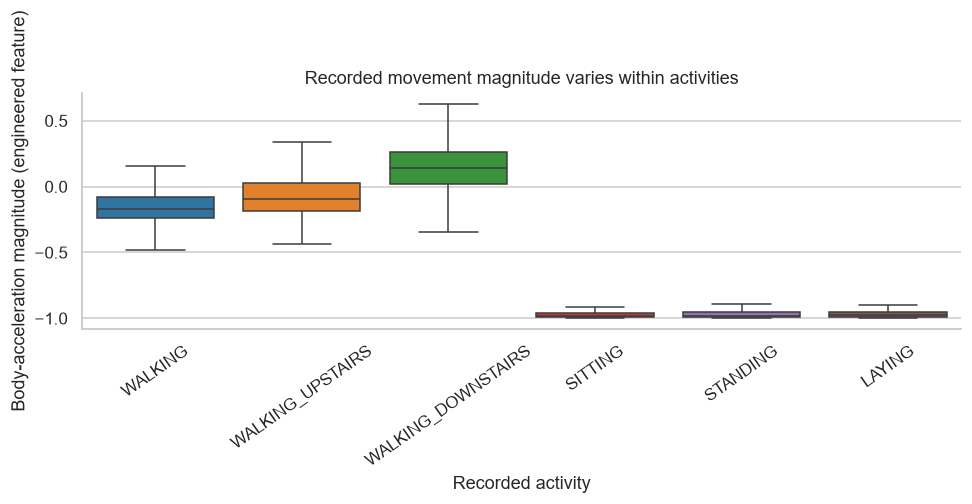

In [41]:
activity_frame=pd.DataFrame({'activity':meta_train.activity.to_numpy(),
                             'body_acc_magnitude':X_train_raw['tBodyAccMag-mean()'].to_numpy()})
fig,ax=plt.subplots(figsize=(9,4.2))
sns.boxplot(data=activity_frame,x='activity',y='body_acc_magnitude',order=ACTIVITIES,
            palette=ACTIVITY_COLORS,showfliers=False,ax=ax)
ax.set(xlabel='Recorded activity',ylabel='Body-acceleration magnitude (engineered feature)',
       title='Recorded movement magnitude varies within activities')
ax.tick_params(axis='x',labelrotation=35)
plt.tight_layout();plt.show()

In [42]:
activity_spread={}; activity_distances=np.full(len(X_repr),np.nan)
for activity in ACTIVITIES:
    ix=np.flatnonzero(meta_train.activity.to_numpy()==activity)
    centre=X_repr[ix].mean(axis=0)
    dist=np.linalg.norm(X_repr[ix]-centre,axis=1)
    activity_distances[ix]=dist
    activity_spread[activity]=float(np.median(dist))
spread=pd.Series(activity_spread).reindex(ACTIVITIES)
rates=pd.DataFrame({'activity':meta_train.activity,'global':flag_global,'contextual':flag_context}).groupby('activity')[['global','contextual']].mean().reindex(ACTIVITIES)*100
variation_results=pd.DataFrame({'median_distance_to_activity_centre':spread,
                                'global_flags_pct':rates['global'],
                                'contextual_flags_pct':rates['contextual']})
display(variation_results.round(2))
print('Across the six activities, rank correlation between variation and global flag rate:',
      round(float(spearmanr(spread.values,rates['global'].values).statistic),3))

,median_distance_to_activity_centre,global_flags_pct,contextual_flags_pct
WALKING,13.38,4.98,1.39
WALKING_UPSTAIRS,13.21,3.82,5.03
WALKING_DOWNSTAIRS,15.87,21.40,5.07
SITTING,10.44,1.01,5.68
STANDING,10.14,0.07,3.71
LAYING,11.51,2.91,8.74


Across the six activities, rank correlation between variation and global flag rate: 1.0


**Interpretation.** The earlier 327-feature execution found a pronounced walking-downstairs global anomaly concentration and a positive association between activity spread and global flagging. The feature distributions and multivariate dispersion now allow this association to be examined explicitly. A correlation across only six activities is descriptive; the **equal-spread intervention** is the stronger test of whether dispersion can explain the detector response.

### 6.4.4 Additional density and scaled-distance checks

The original investigation also compared Gaussian likelihood with within-group scaled distances. We retain this as a focused disagreement check: these assumptions affect which observations appear unusual. Neither the raw likelihood nor the scaled distance should be read as a clinical abnormality score.

In [43]:
# Both scores use the shared training representation and RQ1 model definitions.
score_gmm=-gmm_fine.score_samples(X_repr)
score_cluster_mahal=np.zeros(len(X_repr))
for g in np.unique(cluster_fine):
    ix=np.flatnonzero(cluster_fine==g)
    block=X_repr[ix]
    centre=block.mean(axis=0)
    # Shrink towards a shared positive diagonal scale to avoid zero variance.
    variances=.9*block.var(axis=0)+.1*np.maximum(X_repr.var(axis=0),1e-6)
    score_cluster_mahal[ix]=np.sqrt(np.sum((block-centre)**2/np.maximum(variances,1e-6),axis=1))
flags_gmm=score_gmm>=np.quantile(score_gmm,.95)
flags_cluster_mahal=score_cluster_mahal>=np.quantile(score_cluster_mahal,.95)
print('Jaccard overlap with global k-NN:')
for name,flags in [('GMM density',flags_gmm),('Cluster-wise scaled distance',flags_cluster_mahal)]:
    print(f'  {name}: {jaccard(flag_global,flags):.3f}')

Jaccard overlap with global k-NN:
  GMM density: 0.443
  Cluster-wise scaled distance: 0.303


**Interpretation.** These alternatives test whether the global shortlist is specific to Euclidean neighbourhood distance. GMM density can favour windows that fit its estimated covariance structure, while the cluster-conditioned distance discounts some of the spread associated with a particular movement group. Their differences are meaningful evidence about the definition of unusualness, not competing estimates of classification accuracy. The physical and spatial examples above remain the primary visual evidence.

### 6.4.5 Sensitivity to the number of reference groups

The original RQ2 investigation found that a high-intensity subgroup can seem globally anomalous when absorbed into a broad family, but much less anomalous when treated as its own group. We repeat that analysis using only **RQ1's fitted K-Means partitions**—no new clustering is performed in RQ2. At each resolution, distance to the nearest centroid is contrasted with the same distance divided by its own cluster's median radius. The result reveals how the reference definition changes which activities are over-flagged; it does not validate the finer value of `k`.

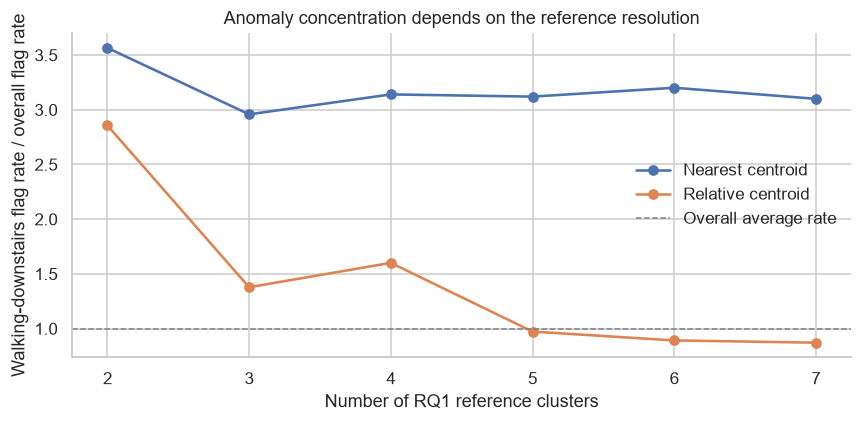

scoring,Nearest centroid,Relative centroid
k,,
2,3.57,2.86
3,2.96,1.38
4,3.14,1.60
5,3.12,0.97
6,3.20,0.89
7,3.10,0.87


In [44]:
reference_resolution=[]
for kk in [2,3,4,5,6,7]:
    fitted=cluster_models[kk]
    distances=fitted.transform(X_repr)
    ids=fitted.labels_
    own=distances[np.arange(len(X_repr)),ids]
    scale=pd.Series(own).groupby(ids).median().replace(0,1e-9)
    rel=own/scale.reindex(ids).to_numpy()
    for method,score in [('Nearest centroid',own),('Relative centroid',rel)]:
        flags=score>=np.quantile(score,.95)
        downstairs=(act_arr=='WALKING_DOWNSTAIRS')
        enrich=float(flags[downstairs].mean()/max(flags.mean(),1e-9))
        reference_resolution.append({'k':kk,'scoring':method,'downstairs_enrichment':enrich,
                                     'downstairs_flag_pct':100*flags[downstairs].mean()})
ref_sensitivity=pd.DataFrame(reference_resolution)
fig,ax=plt.subplots(figsize=(8,4))
for name,group in ref_sensitivity.groupby('scoring'):
    ax.plot(group.k,group.downstairs_enrichment,marker='o',lw=1.7,label=name)
ax.axhline(1,ls='--',lw=1,color='grey',label='Overall average rate')
ax.set(xlabel='Number of RQ1 reference clusters',
       ylabel='Walking-downstairs flag rate / overall flag rate',
       title='Anomaly concentration depends on the reference resolution')
ax.legend(frameon=False);plt.tight_layout();plt.show()
display(ref_sensitivity.pivot(index='k',columns='scoring',values='downstairs_enrichment').round(2))

## 6.5 Physical meaning of the highly flagged fine group

Rather than assuming every high anomaly score is a one-off sensor error, compare the small, high-flag-rate discovered group with other windows in the **same broad movement family**. Acceleration magnitude, jerk, rotation and gravity/orientation features can distinguish movement vigour from changes in sensor positioning. We also examine differences *within the same participants* to avoid attributing every physical difference to who happened to be recorded.

,high-flag group,other windows in broad family
tBodyAccMag-mean(),0.189,-0.099
tBodyAccJerkMag-mean(),0.152,-0.278
tBodyGyroMag-mean(),0.131,-0.224
tGravityAcc-mean()-X,0.921,0.929
tGravityAcc-mean()-Y,-0.192,-0.227


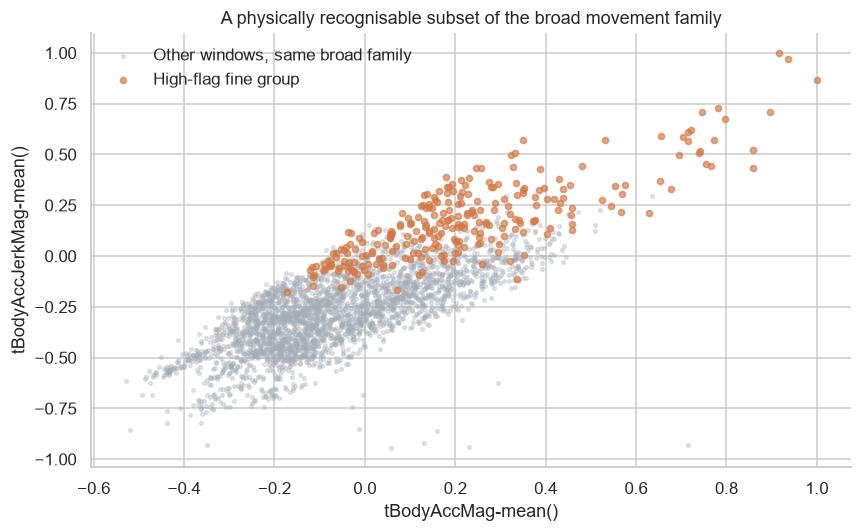

,subject,windows_inside,tBodyAccMag-mean(): inside,tBodyAccMag-mean(): outside
0,23,78,0.056,-0.057
1,19,57,0.531,0.017
2,14,33,0.250,-0.010
3,8,31,0.187,0.100
4,6,29,0.350,-0.032


Examined group 1: 260 windows, 208 global flags; 12 participants.


In [45]:
# Choose the fine group with greatest observed share of all global flags; disclose this selection.
target_group=int(cluster_flags.flagged.idxmax())
group_mask=cluster_fine==target_group
broad_majority=int(pd.Series(cluster_broad[group_mask]).mode().iloc[0])
comparison_mask=(cluster_broad==broad_majority)&(~group_mask)
small_phys=[f for f in ['tBodyAccMag-mean()','tBodyAccJerkMag-mean()',
                        'tBodyGyroMag-mean()','tGravityAcc-mean()-X','tGravityAcc-mean()-Y']
            if f in X_train_raw.columns]
if small_phys:
    physical_contrast=pd.DataFrame({'high-flag group':X_train_raw.loc[group_mask,small_phys].median(),
                                   'other windows in broad family':X_train_raw.loc[comparison_mask,small_phys].median()})
    display(physical_contrast.round(3))
    f0=small_phys[0];f1=small_phys[1] if len(small_phys)>1 else small_phys[0]
    fig,ax=plt.subplots(figsize=(8,5))
    ax.scatter(X_train_raw.loc[comparison_mask,f0],X_train_raw.loc[comparison_mask,f1],s=6,alpha=.3,
               label='Other windows, same broad family',color='#a5adb6',rasterized=True)
    ax.scatter(X_train_raw.loc[group_mask,f0],X_train_raw.loc[group_mask,f1],s=16,alpha=.65,
               label='High-flag fine group',color='#d37743',rasterized=True)
    ax.set(xlabel=f0,ylabel=f1,title='A physically recognisable subset of the broad movement family')
    ax.legend(frameon=False);plt.tight_layout();plt.show()
    top_subjects=meta_train.loc[group_mask,'subject_id'].value_counts().head(5).index
    within_contrast=[]
    for sid in top_subjects:
        inside=group_mask & (sub_arr==sid)
        outside=comparison_mask & (sub_arr==sid)
        if inside.any() and outside.any():
            within_contrast.append({'subject':sid,'windows_inside':int(inside.sum()),
                                    f'{f0}: inside':X_train_raw.loc[inside,f0].median(),
                                    f'{f0}: outside':X_train_raw.loc[outside,f0].median()})
    display(pd.DataFrame(within_contrast).round(3))
print(f'Examined group {target_group}: {int(group_mask.sum())} windows, '
      f'{int(np.sum(group_mask&flag_global))} global flags; '
      f'{meta_train.loc[group_mask,"subject_id"].nunique()} participants.')

### 6.5.1 Examples from the original raw signals

Select two examples based on their **actual global scores**. If the high-flag group has an unflagged member, compare the lowest-scoring unflagged window with the highest-scoring flagged window. Otherwise label the first case as **relatively lower-scoring within a highly flagged group**, not 'typical'. This avoids implying a median window is globally normal when most of the group is flagged.

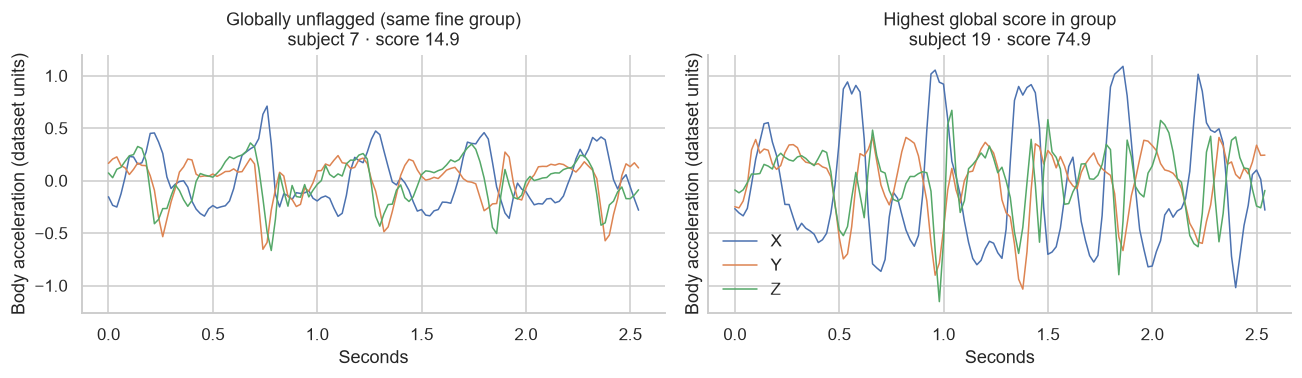

In [46]:
if signals_available:
    chosen=np.flatnonzero(group_mask)
    low_candidates=chosen[~flag_global[chosen]]
    low_idx=int(low_candidates[np.argmin(score_global[low_candidates])]) if len(low_candidates) else int(chosen[np.argmin(score_global[chosen])])
    high_idx=int(chosen[np.argmax(score_global[chosen])])
    low_label='Globally unflagged (same fine group)' if len(low_candidates) else 'Lowest score within highly flagged group'
    fig,axes=plt.subplots(1,2,figsize=(12,3.6),sharey=True)
    for ax,idx,label in zip(axes,[low_idx,high_idx],[low_label,'Highest global score in group']):
        for axis in 'xyz':
            ax.plot(np.arange(128)/50,body_acc[axis][idx],lw=1,label=axis.upper())
        ax.set(xlabel='Seconds',ylabel='Body acceleration (dataset units)',
               title=f'{label}\nsubject {sub_arr[idx]} · score {score_global[idx]:.1f}')
    axes[1].legend(frameon=False);plt.tight_layout();plt.show()
else:
    print('Raw inertial signals unavailable. Figure omitted; feature-level physical comparisons remain available.')

## 6.6 Can variation account for the anomaly concentration?

The equal-spread intervention retains each activity's feature-space centre but rescales its within-activity spread to a common magnitude. This uses known activity labels **only as an explanatory counterfactual**. It deliberately changes the data geometry and must not be described as improved preprocessing or causal proof of natural movement differences.

### 6.6.1 Equalising within-activity spread

To test whether unequal spread contributes to the unequal global flag rates, we retain each activity's mean feature profile but rescale deviations around that profile to a common total within-activity variance. We then recompute the global distance-based shortlist. This controlled, activity-informed intervention is an explanatory test and not the feature representation used for the principal unsupervised analyses.

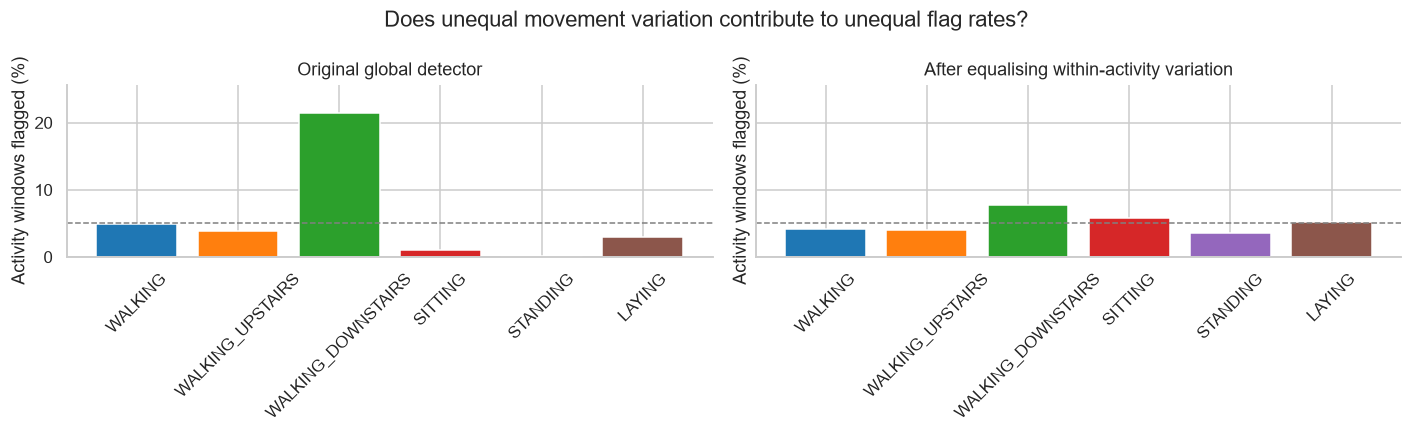

Original and equalised global anomaly rates (%):


,original,equal_spread
activity,,
WALKING,5.0,4.2
WALKING_UPSTAIRS,3.8,4.0
WALKING_DOWNSTAIRS,21.4,7.7
SITTING,1.0,5.8
STANDING,0.1,3.6
LAYING,2.9,5.3


Activity labels were used only for this explanatory intervention, not to fit the original global detector.


In [47]:
# A controlled, label-informed analysis: equalise total within-activity spread in the common feature space.
# This is not the default feature representation and cannot be used when activity labels are unknown.
all_acts=meta_train.activity.to_numpy()
trace_by_activity={}
for a in ACTIVITIES:
    block=X_repr[all_acts==a]
    trace_by_activity[a]=float(np.var(block,axis=0,ddof=1).sum())
target_spread=float(np.mean(list(trace_by_activity.values())))
X_equal_spread=X_repr.copy()
for a in ACTIVITIES:
    mask=(all_acts==a)
    centre=X_repr[mask].mean(axis=0)
    scale=np.sqrt(target_spread/max(trace_by_activity[a],1e-12))
    X_equal_spread[mask]=centre+(X_repr[mask]-centre)*scale

nn_equal=NearestNeighbors(n_neighbors=K_NEIGHBORS+1,n_jobs=-1).fit(X_equal_spread)
score_equal=nn_equal.kneighbors(X_equal_spread)[0][:,K_NEIGHBORS]
flag_equal=score_equal>=np.quantile(score_equal,.95)
compare=pd.DataFrame({'activity':all_acts,'original':flag_global,'equal_spread':flag_equal})
compare=compare.groupby('activity')[['original','equal_spread']].mean().reindex(ACTIVITIES)*100
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,col,title in zip(axes,['original','equal_spread'],
                        ['Original global detector','After equalising within-activity variation']):
    ax.bar(ACTIVITIES,compare[col],color=[ACTIVITY_COLORS[a] for a in ACTIVITIES])
    ax.axhline(5,ls='--',color='grey',lw=1)
    ax.set(title=title,ylabel='Activity windows flagged (%)',ylim=(0,max(15,compare.to_numpy().max()*1.2)))
    ax.tick_params(axis='x',labelrotation=45)
plt.suptitle('Does unequal movement variation contribute to unequal flag rates?')
plt.tight_layout();plt.show()
print('Original and equalised global anomaly rates (%):')
display(compare.round(1))
print('Activity labels were used only for this explanatory intervention, not to fit the original global detector.')

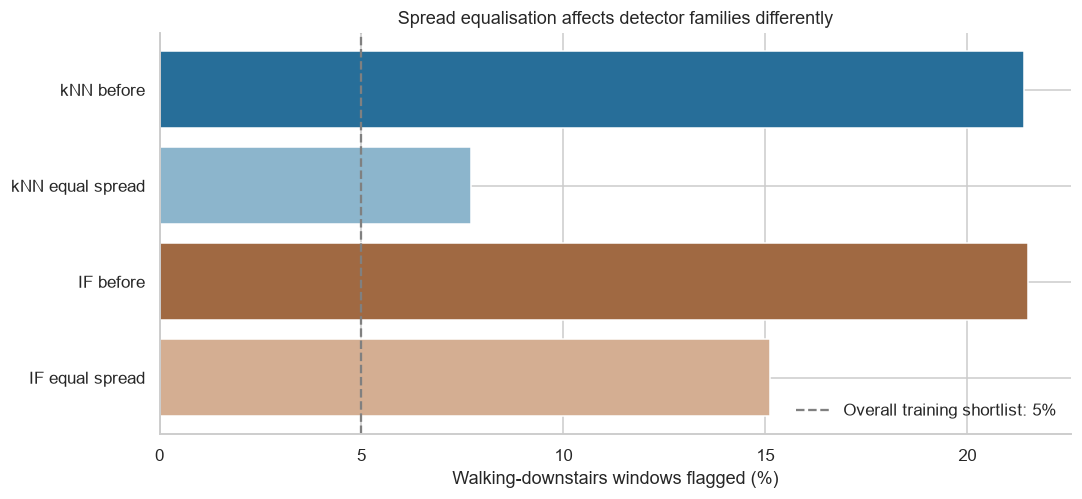

,kNN before,kNN equal spread,IF before,IF equal spread
WALKING,4.98,4.16,6.85,8.40
WALKING_UPSTAIRS,3.82,4.01,4.66,6.43
WALKING_DOWNSTAIRS,21.40,7.71,21.50,15.11
SITTING,1.01,5.83,0.23,0.93
STANDING,0.07,3.57,0.00,0.44
LAYING,2.91,5.26,1.35,2.06


Global k-NN shortlist overlap before/after spread intervention: 0.435


In [48]:
# Apply a second model family to the same spread-equalisation intervention.
score_iforest_equal=-IsolationForest(n_estimators=160,random_state=RANDOM_STATE,n_jobs=-1).fit(
    X_equal_spread).score_samples(X_equal_spread)
flags_iforest_equal=score_iforest_equal>=np.quantile(score_iforest_equal,.95)
spread_counterfactual=pd.DataFrame({
    'kNN before':pd.Series(flag_global).groupby(act_arr).mean(),
    'kNN equal spread':pd.Series(flag_equal).groupby(act_arr).mean(),
    'IF before':pd.Series(flags_iforest).groupby(act_arr).mean(),
    'IF equal spread':pd.Series(flags_iforest_equal).groupby(act_arr).mean()
}).reindex(ACTIVITIES)*100
fig,ax=plt.subplots(figsize=(10,4.7))
part=spread_counterfactual.loc['WALKING_DOWNSTAIRS']
ax.barh(np.arange(len(part)),part.values,color=['#276e99','#8cb5cc','#a06942','#d4ae92'])
ax.axvline(5,color='grey',ls='--',label='Overall training shortlist: 5%')
ax.set(yticks=np.arange(len(part)),yticklabels=part.index,
       xlabel='Walking-downstairs windows flagged (%)',
       title='Spread equalisation affects detector families differently')
ax.invert_yaxis();ax.legend(frameon=False);plt.tight_layout();plt.show()
display(spread_counterfactual.round(2))
print('Global k-NN shortlist overlap before/after spread intervention:',
      round(jaccard(flag_global,flag_equal),3))

**Interpretive consequence.** A reduction in downstairs flags after spread equalisation supports the explanation that global distance is partly sensitive to unequal activity dispersion. Different reductions for k-NN and Isolation Forest demonstrate that this explanation is detector-dependent. Remaining flags may reflect other aspects of the distribution; neither intervention identifies actual abnormal movement.

## 6.7 Recording-edge effects as an alternative explanation

The original RQ2 tested whether flags in low-motion activities coincide with recording-block boundaries. The UCI HAR data do not supply verified transition annotations, so we reconstruct only **approximate contiguous blocks** using participant/activity continuity and raw-signal overlap. A boundary may coincide with transitions or recording procedures, but is not a labelled physical transition. The segment IDs are also used in RQ3 to study temporal recurrence.

Approximate contiguous recording blocks: 600 | boundaries are NOT verified activity transitions


edge_rate                     \
detector           Cluster-relative k-NN Global k-NN    LOF   
activity                                                      
LAYING                             0.176       0.060  0.131   
SITTING                            0.101       0.030  0.158   
STANDING                           0.089       0.003  0.128   
WALKING                            0.014       0.051  0.034   
WALKING_DOWNSTAIRS                 0.047       0.240  0.065   
WALKING_UPSTAIRS                   0.051       0.047  0.035   

                             middle_rate                     
detector           Cluster-relative k-NN Global k-NN    LOF  
activity                                                     
LAYING                             0.060       0.020  0.051  
SITTING                            0.041       0.003  0.024  
STANDING                           0.020       0.000  0.019  
WALKING                            0.013       0.050  0.024  
WALKING_DOWNSTAIRS                 0.057       0.195  0.072  
WALKING_UPSTAIRS                   0.050       0.030  0.023

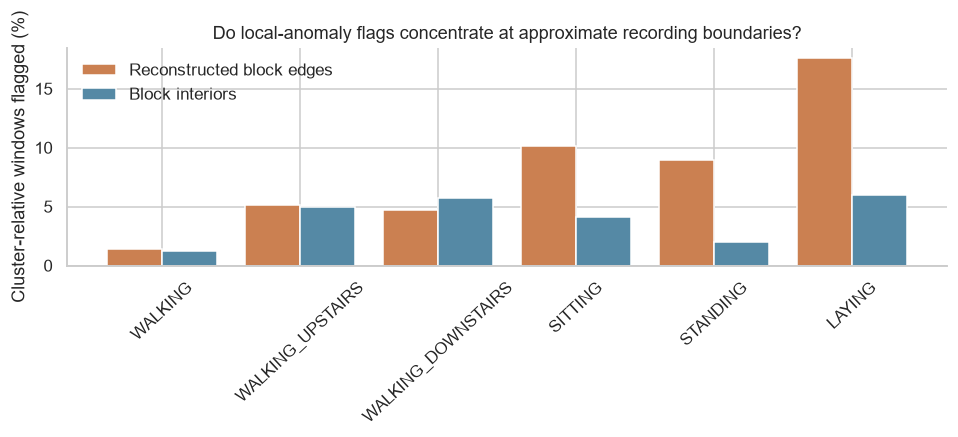

In [49]:
same_group=(meta_train.subject_id.eq(meta_train.subject_id.shift()) &
            meta_train.activity_id.eq(meta_train.activity_id.shift())).to_numpy()
if signals_available:
    sig=body_acc['x']
    overlap_ok=np.r_[False,np.all(np.isclose(sig[:-1,64:],sig[1:,:64],atol=1e-5),axis=1)]
    segment_start=~(same_group & overlap_ok)
else:
    segment_start=~same_group
segment_start[0]=True
results_train['segment_id']=np.cumsum(segment_start)-1
results_train['position']=results_train.groupby('segment_id').cumcount()
segment_size=results_train.groupby('segment_id').position.transform('size')
boundary=(results_train.position.lt(2)|results_train.position.ge(segment_size-2))&(segment_size>=6)
interior=(~boundary)&(segment_size>=6)
results_train['approx_edge']=boundary
results_train['segment_length']=segment_size
print('Approximate contiguous recording blocks:',results_train.segment_id.nunique(),
      '| boundaries are NOT verified activity transitions')
edge_rows=[]
for activity in ACTIVITIES:
    a=(act_arr==activity)
    for name,flag in [('Global k-NN',flag_global),('LOF',flags_lof),('Cluster-relative k-NN',flag_context)]:
        e=a&boundary;mid=a&interior
        edge_rows.append({'activity':activity,'detector':name,'edge_n':int(e.sum()),
                          'edge_rate':float(np.mean(flag[e])) if e.any() else np.nan,
                          'middle_rate':float(np.mean(flag[mid])) if mid.any() else np.nan})
edge_df=pd.DataFrame(edge_rows)
display(edge_df.pivot(index='activity',columns='detector',values=['edge_rate','middle_rate']).round(3))
fig,ax=plt.subplots(figsize=(9,4))
show_edge=edge_df[edge_df.detector=='Cluster-relative k-NN'].set_index('activity').reindex(ACTIVITIES)
pos=np.arange(len(ACTIVITIES))
ax.bar(pos-.2,100*show_edge.edge_rate,width=.4,label='Reconstructed block edges',color='#cb8051')
ax.bar(pos+.2,100*show_edge.middle_rate,width=.4,label='Block interiors',color='#5589a5')
ax.set(xticks=pos,xticklabels=ACTIVITIES,ylabel='Cluster-relative windows flagged (%)',
       title='Do local-anomaly flags concentrate at approximate recording boundaries?')
ax.tick_params(axis='x',rotation=43);ax.legend(frameon=False)
plt.tight_layout();plt.show()

In [50]:
# Additional raw-sensor check, comparing block edges with interiors within same person/activity.
if signals_available:
    gyro=np.sqrt(sum(load_signal('train','body_gyro',ax)**2 for ax in 'xyz'))
    total={ax:load_signal('train','total_acc',ax) for ax in 'xyz'}
    v0=np.column_stack([total[ax][:,:32].mean(axis=1) for ax in 'xyz'])
    v1=np.column_stack([total[ax][:,-32:].mean(axis=1) for ax in 'xyz'])
    denom=np.maximum(np.linalg.norm(v0,axis=1)*np.linalg.norm(v1,axis=1),1e-12)
    tilt_change=np.degrees(np.arccos(np.clip((v0*v1).sum(axis=1)/denom,-1,1)))
    raw_edge=pd.DataFrame({'subject_id':sub_arr,'activity':act_arr,'edge':boundary,
                           'rotation':gyro.mean(axis=1),'tilt_change_deg':tilt_change})
    raw_edge=raw_edge[(boundary|interior)&raw_edge.activity.isin(['SITTING','STANDING','LAYING'])]
    comparable=raw_edge.groupby(['subject_id','activity','edge'])[['rotation','tilt_change_deg']].median().unstack('edge').dropna()
    raw_edge_summary=pd.DataFrame({name:{'paired person/activity cells':len(comparable),
             'edge higher than interior (%)':100*float(np.mean(comparable[(name,True)]>comparable[(name,False)])) if len(comparable) else np.nan,
             'median edge / interior ratio':float(np.median(comparable[(name,True)]/np.maximum(comparable[(name,False)],1e-9))) if len(comparable) else np.nan}
         for name in ['rotation','tilt_change_deg']}).T
    display(raw_edge_summary.round(2))
else:
    print('Raw-signal boundary comparisons skipped: inertial matrices unavailable.')

,paired person/activity cells,edge higher than interior (%),median edge / interior ratio
rotation,63.0,100.00,2.95
tilt_change_deg,63.0,90.48,1.37


## 6.8 Robustness to neighbourhood and shortlist definitions

Neighbour count and threshold change which windows are shortlisted. Compare **per-activity rates and rankings**, rather than overinterpreting Jaccard overlap when shortlist size changes (a perfectly nested 2.5% vs 5% shortlist has maximum Jaccard 0.5).

In [51]:
sensitivity=[]
for neighbours in [5,K_NEIGHBORS,30]:
    d=NearestNeighbors(n_neighbors=neighbours+1,n_jobs=-1).fit(X_repr).kneighbors(X_repr)[0][:,neighbours]
    for fraction in [.025,.05,.10]:
        flags=d>=np.quantile(d,1-fraction)
        rate=pd.Series(flags).groupby(meta_train.activity).mean().reindex(ACTIVITIES)*100
        sensitivity.append({'k':neighbours,'shortlist_fraction':fraction,
                            'highest_rate_activity':rate.idxmax(),
                            'highest_rate_pct':round(float(rate.max()),2),
                            'overlap_with_reference':jaccard(flags,flag_global)})
sensitivity=pd.DataFrame(sensitivity)
display(sensitivity.round(3))

,k,shortlist_fraction,highest_rate_activity,highest_rate_pct,overlap_with_reference
0,5,0.025,WALKING_DOWNSTAIRS,11.56,0.500
1,5,0.050,WALKING_DOWNSTAIRS,21.81,0.845
2,5,0.100,WALKING_DOWNSTAIRS,40.57,0.498
3,15,0.025,WALKING_DOWNSTAIRS,11.36,0.500
4,15,0.050,WALKING_DOWNSTAIRS,21.40,1.000
5,15,0.100,WALKING_DOWNSTAIRS,38.54,0.500
6,30,0.025,WALKING_DOWNSTAIRS,11.26,0.500
7,30,0.050,WALKING_DOWNSTAIRS,20.89,0.932
8,30,0.100,WALKING_DOWNSTAIRS,36.31,0.500


**Interpretation.** The important robustness question is whether the same movement types remain disproportionately flagged across reasonable neighbourhood choices, rather than whether the identical windows remain in every fixed-size shortlist. A change in flagged membership is expected when the fraction itself changes. Results that depend strongly on a single setting should be reported as sensitivity rather than stable evidence of abnormal behaviour.

### 6.8.1 Participant-level uncertainty in anomaly rates

The overlapping windows do not constitute independent samples. To describe uncertainty more conservatively, we resample whole participants rather than individual rows and recalculate the difference between global and contextual anomaly rates for the activity with the highest original global flag rate. This analysis is descriptive: it conditions on the training detectors, and the available participants are not a random sample of the entire population.

In [52]:
rr=np.random.default_rng(RANDOM_STATE+57)
selected_activity=rates['global'].idxmax()
sub_ids=np.sort(meta_train.subject_id.unique())
bootstrap_diffs=[]
for _ in range(350):
    sampled_subjects=rr.choice(sub_ids,size=len(sub_ids),replace=True)
    pieces=[results_train.loc[results_train.subject_id==sid] for sid in sampled_subjects]
    boot=pd.concat(pieces,ignore_index=True)
    group=boot.loc[boot.activity==selected_activity]
    if len(group):
        bootstrap_diffs.append(100*(group.flag_global.mean()-group.flag_context.mean()))
observed_diff=float(rates.loc[selected_activity,'global']-rates.loc[selected_activity,'contextual'])
print('Activity with largest global flag rate:',selected_activity)
print('Global minus contextual flag rate (percentage points):',round(observed_diff,2))
print('Participant-bootstrap 95% interval (percentage points):',
      np.round(np.percentile(bootstrap_diffs,[2.5,97.5]),2))

Activity with largest global flag rate: WALKING_DOWNSTAIRS
Global minus contextual flag rate (percentage points): 16.33
Participant-bootstrap 95% interval (percentage points): [ 6.3  28.76]


**Interpretation.** The previous 327-feature execution found a **positive** participant-bootstrap interval for the difference between global and contextual walking-downstairs rates (approximately **6.3–28.8 percentage points**). Whole-participant resampling limits naive window-level precision, but the interval conditions on the already-fitted detectors and does not establish causal movement differences. Confirm the new interval from the rerun.

### Discussion of RQ2

The evidence should answer both clauses of the question. Within-person spread and the activity-level decomposition establish whether movement types vary differently, without automatically attributing the variation to participants. Detector comparisons reveal whether this variability influences anomaly rankings. The equal-spread experiment makes the explanation testable, while the recording-edge and physical-signal checks investigate competing causes. Global and cluster-relative scores may describe the **same windows differently** because their reference populations differ; this is a finding about anomaly definitions, not ground truth.

The most consequential observations to report after execution are the number of participants for whom walking downstairs has the highest within-person spread; the excess global flag rate; the detector-specific response to equal-spread adjustment; and the extent to which conclusions survive alternative group and neighbourhood definitions.

# 7. RQ3 — Individual Differences and Isolated Departures

**Investigators: Muhatasim and Subhashini; incorporating the original participant-specific analysis.** RQ3 asks a separate question from RQ1 and RQ2: whether flagged windows reflect **consistent participant-associated measurements** or **isolated departures**. We must distinguish (i) differences in people's usual feature profiles, (ii) concentration of high scores, (iii) temporal recurrence and (iv) departure relative to the same person's comparable movements. These are not interchangeable definitions of 'systematic'.

## 7.1 Evidence for participant-specific profiles within the same activity

The RQ2 decomposition established how much activity variation lies within and between people. Here we inspect *which* people differ across activities and whether a participant's distinctive profile is consistent across relevant measurements. We do not assume that an identifier represents an innate gait signature: phone placement and recording conditions can also differ by person.

### 7.1.1 Between-person share of variance by activity

The physical examples are supplemented by a multivariate decomposition of movement variation. For each activity, we compare the feature-space variation attributable to differences between participant mean profiles with total variation among that activity's windows. This quantifies participant association without treating any person's identity as an anomalous class.

In [53]:
between_person_results=[]
for activity in ACTIVITIES:
    ix=np.flatnonzero(meta_train.activity.to_numpy()==activity)
    block=X_repr[ix]
    ids=meta_train.subject_id.to_numpy()[ix]
    overall=block.mean(axis=0)
    total=np.sum((block-overall)**2)
    between=0.0
    for sid in np.unique(ids):
        part=block[ids==sid]
        between+=len(part)*np.sum((part.mean(axis=0)-overall)**2)
    between_person_results.append({'activity':activity,'between_person_share':between/max(total,1e-12)})
between_person_results=pd.DataFrame(between_person_results)
display(between_person_results.round(3))

,activity,between_person_share
0,WALKING,0.424
1,WALKING_UPSTAIRS,0.366
2,WALKING_DOWNSTAIRS,0.352
3,SITTING,0.103
4,STANDING,0.126
5,LAYING,0.189


**Interpretation.** A large between-participant share indicates that individuals' typical measurements differ relative to the total variation recorded for that activity. The original Task 5 found stronger participant-related structure during walking than during stationary activities. This comparison examines whether that observation persists after feature selection, while remaining descriptive because each participant contributes overlapping windows and potentially distinct recording conditions.

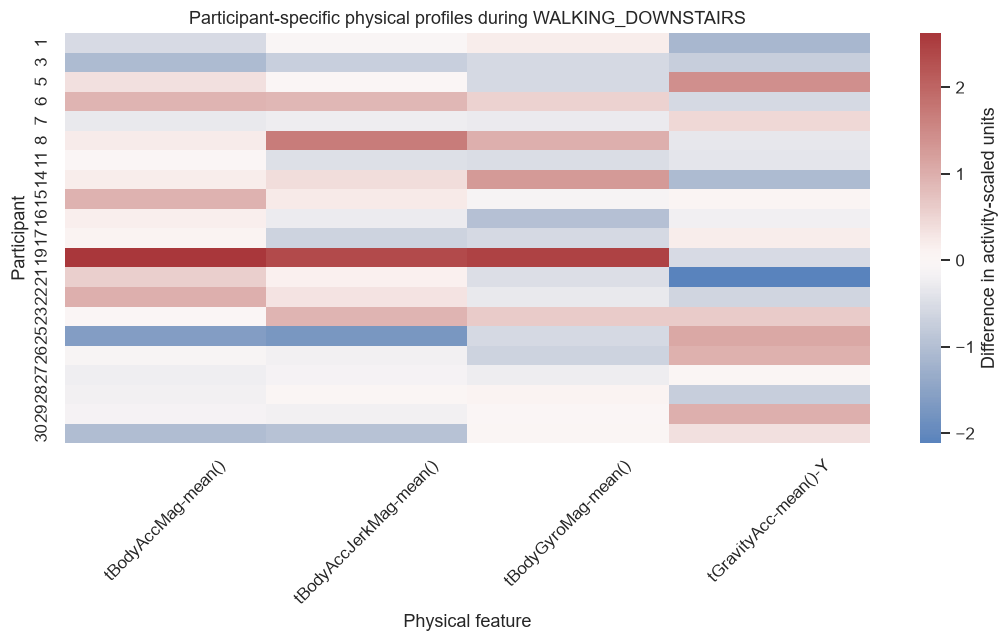

Selected the activity with greatest observed total feature-space spread: WALKING_DOWNSTAIRS


In [54]:
# Participant feature profiles under the same recorded activity. Display deviations from each
# activity's mean, not raw profiles pooled across unlike activities.
profile_features=[f for f in ['tBodyAccMag-mean()','tBodyAccJerkMag-mean()',
                              'tBodyGyroMag-mean()','tGravityAcc-mean()-Y'] if f in X_train_raw.columns]
if profile_features:
    chosen_activity=variation_decomp['total_spread'].idxmax()
    mask=(act_arr==chosen_activity)
    prof=X_train_raw.loc[mask,profile_features].copy()
    prof['subject_id']=sub_arr[mask]
    subject_profile=prof.groupby('subject_id')[profile_features].median()
    pooled=X_train_raw.loc[mask,profile_features]
    centered_profile=(subject_profile-pooled.mean())/pooled.std(ddof=0).replace(0,1)
    fig,ax=plt.subplots(figsize=(10,6))
    sns.heatmap(centered_profile,center=0,cmap='vlag',ax=ax,cbar_kws={'label':'Difference in activity-scaled units'})
    ax.set(xlabel='Physical feature',ylabel='Participant',
           title=f'Participant-specific physical profiles during {chosen_activity}')
    ax.tick_params(axis='x',rotation=45)
    plt.tight_layout();plt.show()
    print('Selected the activity with greatest observed total feature-space spread:',chosen_activity)

## 7.2 Are high anomaly scores concentrated in particular people?

The global top-5% flags from RQ2 give a common target. We measure both participant-specific **flag rates** and each person's contribution to all flags. The comparison adjusts for the composition of discovered movement groups. Raw top-five counts are insufficient because participants contribute different numbers of windows.

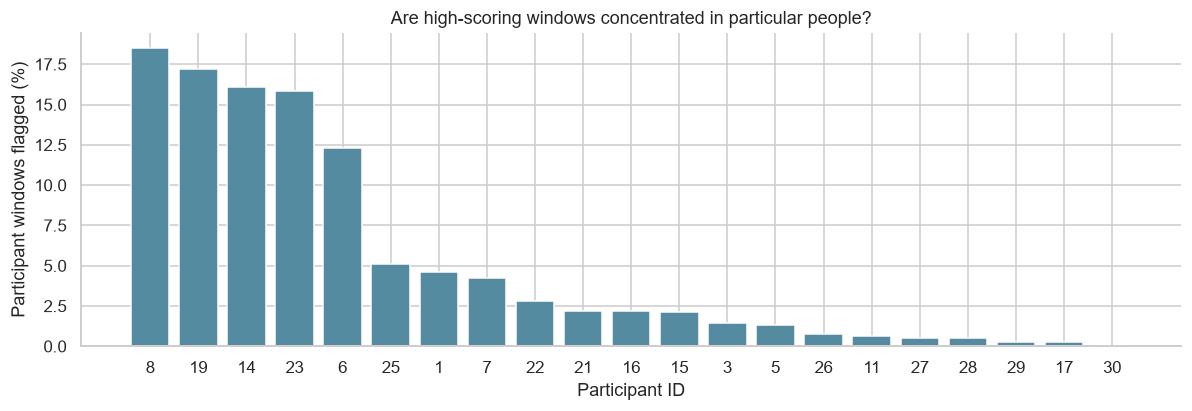

Top-three participants contribute 47.0% of global flagged windows.
How much of the concentration may reflect cluster mix?


,windows,flag_pct,expected_pct
subject_id,,,
8,281,18.5,11.5
19,360,17.2,14.6
14,323,16.1,9.9
23,372,15.9,18.2
6,325,12.3,9.9
25,409,5.1,1.4
1,347,4.6,4.5
7,308,4.2,6.6


Observed versus expected is descriptive; overlapping windows prevent a naive independence-based p-value.


In [55]:
person=results_train.groupby('subject_id').agg(windows=('flag_global','size'),flagged=('flag_global','sum'))
person['flag_pct']=person.flagged/person.windows*100
# Group-mix expected count: for each person's assigned discovered clusters, use the overall cluster flag rates.
cluster_rate=results_train.groupby('cluster_fine').flag_global.mean()
expected=results_train.cluster_fine.map(cluster_rate)
person['expected_pct']=pd.DataFrame({'subject_id':results_train.subject_id,'expected':expected}).groupby('subject_id').expected.mean()*100
person=person.sort_values('flag_pct',ascending=False)
fig,ax=plt.subplots(figsize=(11,3.9))
ax.bar(person.index.astype(str),person.flag_pct,color='#548ba1')
ax.set(xlabel='Participant ID',ylabel='Participant windows flagged (%)',
       title='Are high-scoring windows concentrated in particular people?')
plt.tight_layout();plt.show()
print('Top-three participants contribute',
      f'{person.nlargest(3,"flagged").flagged.sum()/max(1,person.flagged.sum()):.1%}',
      'of global flagged windows.')
print('How much of the concentration may reflect cluster mix?')
display(person[['windows','flag_pct','expected_pct']].head(8).round(1))
print('Observed versus expected is descriptive; overlapping windows prevent a naive independence-based p-value.')

**Interpretation.** The original RQ3 found marked concentration among a small subset of participants for global detectors. The present bar chart makes that concentration visible, while the group-adjusted expectation asks whether a participant is unusual simply because they contribute more windows from a high-flag movement group. An association with participant identity does not identify its physical cause; phone placement or recording protocol may be involved.

### 7.2.1 Concentration controlling for cluster membership

We compare the share of all global flags contributed by the three highest-contributing participants with a shuffled reference that preserves the number of flags within each discovered cluster. The permutation tests association after accounting for cluster membership; because windows overlap, its uncertainty should not be interpreted as an independent-window sampling model.

In [56]:
observed_top3=(person.nlargest(3,'flagged').flagged.sum()/max(1,person.flagged.sum()))
permuted_top3=[]
rr=np.random.default_rng(RANDOM_STATE+93)
for _ in range(300):
    shuffled=np.zeros(len(results_train),dtype=bool)
    for group,ix in results_train.groupby('cluster_fine').groups.items():
        idx=np.asarray(list(ix),dtype=int)
        vals=flag_global[idx].copy()
        rr.shuffle(vals)
        shuffled[idx]=vals
    counts=pd.Series(shuffled).groupby(results_train.subject_id).sum().nlargest(3)
    permuted_top3.append(float(counts.sum()/max(1,shuffled.sum())))
print('Top-three share of all global flags:',round(observed_top3,3))
print('Cluster-preserving shuffled reference, median and 95% range:',
      np.round(np.percentile(permuted_top3,[50,2.5,97.5]),3))

Top-three share of all global flags: 0.47
Cluster-preserving shuffled reference, median and 95% range: [0.423 0.399 0.446]


**Interpretation.** If the observed share substantially exceeds the cluster-preserving reference, there is evidence of participant-associated concentration beyond broad differences in discovered group membership. The test does not distinguish systematic movement habits from session-specific sensor conditions. Its comparison also treats windows as exchangeable within clusters, so the temporal dependence described above remains a limitation.

## 7.3 Temporal evidence: episodes versus isolated windows

Consecutive overlapping windows may all represent a *single* physical episode. We count runs **within reconstructed recording blocks** and compare adjacent flags with a segment-preserving shuffled reference. This helps distinguish temporally concentrated episodes from dispersed flags, but does not prove long-term personal consistency.

Flagged recording episodes: 184 | single-window episodes: 120 | longest run (windows): 8


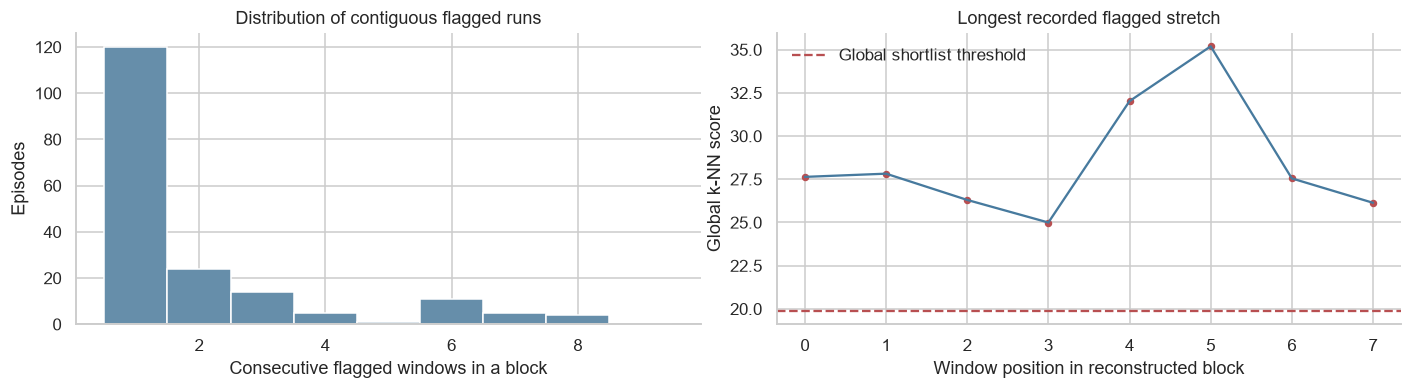

In [57]:
# Uses the segment_id and position created by RQ2's recording-boundary analysis.
run_details=[]
for seg,frame in results_train.groupby('segment_id',sort=False):
    arr=frame.flag_global.to_numpy()
    begin=None
    for j,flag in enumerate(np.r_[arr,False]):
        if flag and begin is None: begin=j
        if not flag and begin is not None:
            run_details.append({'segment_id':int(seg),'start':int(begin),'length':int(j-begin),
                                'subject_id':int(frame.subject_id.iloc[begin]),
                                'activity':frame.activity.iloc[begin],
                                'window_id':int(frame.window_id.iloc[begin])})
            begin=None
runs=pd.DataFrame(run_details,columns=['segment_id','start','length','subject_id','activity','window_id'])
print('Flagged recording episodes:',len(runs),
      '| single-window episodes:',int((runs.length==1).sum()) if len(runs) else 0,
      '| longest run (windows):',int(runs.length.max()) if len(runs) else 0)
if len(runs):
    chosen_run=runs.sort_values(['length','segment_id'],ascending=[False,True]).iloc[0]
    frame=results_train.loc[results_train.segment_id==chosen_run.segment_id]
    fig,axes=plt.subplots(1,2,figsize=(13,3.7))
    axes[0].hist(runs.length,bins=np.arange(.5,max(3,int(runs.length.max())+2),1),color='#668eaa')
    axes[0].set(xlabel='Consecutive flagged windows in a block',ylabel='Episodes',
                title='Distribution of contiguous flagged runs')
    axes[1].plot(frame.position,frame.score_global,color='#477a9e')
    axes[1].axhline(threshold_global,color='#b84f51',ls='--',label='Global shortlist threshold')
    axes[1].scatter(frame.loc[frame.flag_global,'position'],frame.loc[frame.flag_global,'score_global'],
                    s=15,color='#b84f51')
    axes[1].set(xlabel='Window position in reconstructed block',ylabel='Global k-NN score',
                title='Longest recorded flagged stretch')
    axes[1].legend(frameon=False)
    plt.tight_layout();plt.show()

### 7.3.1 Persistence relative to shuffled episodes

To distinguish a persistent run from a shortlist with the same number of flags distributed randomly within each segment, we shuffle flags **inside each reconstructed segment**, preserving its length and number of flagged windows. This is a descriptive reference comparison. It does not remove the physical dependence introduced by overlapping measurements.

In [58]:
def count_adjacent_flags(frame):
    total=0
    for _,part in frame.groupby('segment_id',sort=False):
        flags=part.flag_global.to_numpy()
        total+=int(np.sum(flags[:-1]&flags[1:]))
    return total
observed_pairs=count_adjacent_flags(results_train)
random_pairs=[]
rr=np.random.default_rng(RANDOM_STATE+42)
for rep in range(200):
    count=0
    for _,part in results_train.groupby('segment_id',sort=False):
        flags=part.flag_global.to_numpy().copy()
        rr.shuffle(flags)
        count+=int(np.sum(flags[:-1]&flags[1:]))
    random_pairs.append(count)
print('Adjacent flagged-window pairs:',observed_pairs)
print('Segment-preserving randomised reference (median; 2.5th–97.5th percentile):',
      np.round(np.percentile(random_pairs,[50,2.5,97.5]),1))

Adjacent flagged-window pairs: 184
Segment-preserving randomised reference (median; 2.5th–97.5th percentile): [167. 159. 175.]


**Interpretation.** An excess of neighbouring flags over this reference indicates clustering of high scores within the reconstructed episodes, rather than a completely dispersed shortlist. It is not evidence that the participant has a permanent unusual gait: temporary intensity changes, phone movement and activity transitions can all generate short runs. This motivates comparing observations at participant and movement-group level.

### 7.3.2 Do flags recur in separate recording blocks?

Repeated flags in different blocks provide stronger *descriptive* evidence of recurrent observations than a long sequence of overlapping windows from one block. We report both the number of affected blocks and participant-normalised rates; blocks are reconstructed proxies and can reflect different recording sessions or conditions.

,blocks,flagged_blocks,flagged_windows,share_of_blocks_flagged
subject_id,,,,
8,29,16,52,0.552
19,28,15,62,0.536
14,28,15,52,0.536
23,28,12,59,0.429
6,28,11,40,0.393
7,28,10,13,0.357
1,33,6,16,0.182
21,28,6,9,0.214
22,28,6,9,0.214


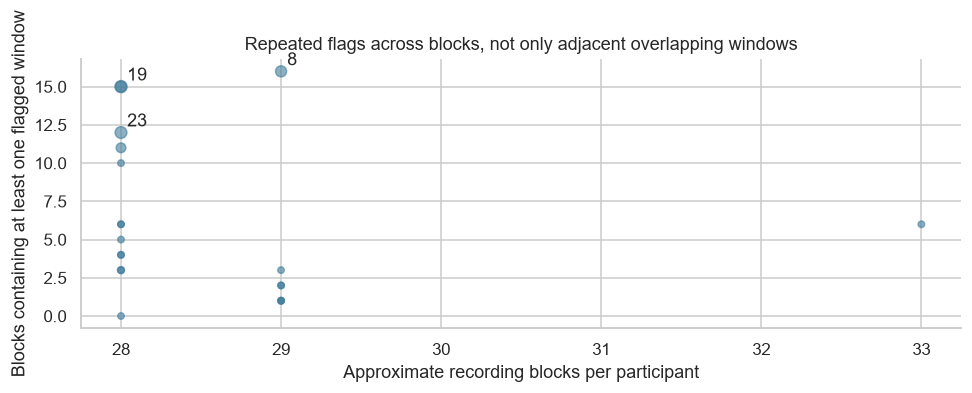

In [59]:
participant_episode=results_train.groupby(['subject_id','segment_id']).agg(
    windows=('flag_global','size'),flagged=('flag_global','sum'),activity=('activity','first')).reset_index()
participant_episode['any_flag']=participant_episode.flagged>0
recurrence=participant_episode.groupby('subject_id').agg(
    blocks=('segment_id','size'),flagged_blocks=('any_flag','sum'),flagged_windows=('flagged','sum'))
recurrence['share_of_blocks_flagged']=recurrence.flagged_blocks/recurrence.blocks.replace(0,np.nan)
display(recurrence.sort_values(['flagged_blocks','flagged_windows'],ascending=False).head(12).round(3))
fig,ax=plt.subplots(figsize=(9,3.5))
ax.scatter(recurrence.blocks,recurrence.flagged_blocks,
           s=np.maximum(18,recurrence.flagged_windows.to_numpy()),alpha=.6,color='#427d9b')
for sid,row in recurrence.nlargest(3,'flagged_windows').iterrows():
    ax.annotate(str(sid),(row.blocks,row.flagged_blocks),xytext=(4,4),textcoords='offset points')
ax.set(xlabel='Approximate recording blocks per participant',ylabel='Blocks containing at least one flagged window',
       title='Repeated flags across blocks, not only adjacent overlapping windows')
plt.tight_layout();plt.show()

## 7.4 Participant × movement-group differences

A participant can be unusually represented in a given movement group without having a globally abnormal gait. We inspect their rate and score distribution **relative to others in the same group**. An operational repeated-elevation rule can summarise patterns, but its outcome must be examined as threshold-dependent rather than declared the percentage of 'systematic' behaviour.

### 7.4.1 Repeated participant–group elevations

A participant who repeatedly produces high scores within one discovered movement group differs from someone who has only an occasional high-scoring window. We examine participant–cluster cells with enough observations to support a comparison. The rule below identifies cells with both an elevated typical score and a higher-than-expected frequency of flagged windows. It is an operational descriptive category, not a validated classification of people.

In [60]:
# Participant/group-level repetition check; based on previously computed global scores, not new discovery.
MIN_CELL_SIZE=12
cell=results_train.groupby(['subject_id','cluster_fine']).agg(
    n=('flag_global','size'),flagged=('flag_global','sum'),
    median_score=('score_global','median'),flag_rate=('flag_global','mean'))
group_rate=results_train.groupby('cluster_fine').flag_global.mean()
group_med=results_train.groupby('cluster_fine').score_global.median()
cell['expected_rate']=[float(group_rate[g]) for _,g in cell.index]
cell['expected_median']=[float(group_med[g]) for _,g in cell.index]
cell['repeated_elevated_pattern']=(cell.n>=MIN_CELL_SIZE) & (cell.flagged>=3) &     (cell.flag_rate>=2*cell.expected_rate.clip(lower=.01)) & (cell.median_score>cell.expected_median)
identified=cell.loc[cell.repeated_elevated_pattern]
flags_in_cells=int(identified.flagged.sum())
print(f'Cells meeting the repeated participant/group rule: {len(identified)}.')
print(f'Flags within those cells: {flags_in_cells} of {flag_global.sum()} '
      f'({flags_in_cells/max(1,int(flag_global.sum())):.1%}).')
print('The remaining flags are NOT automatically isolated; the rule has limited power and depends on its thresholds.')
if len(identified):
    display(identified.sort_values('flagged',ascending=False)[['n','flagged','flag_rate','expected_rate']].head(8)
            .style.format({'flag_rate':'{:.1%}','expected_rate':'{:.1%}'}))

Cells meeting the repeated participant/group rule: 6.
Flags within those cells: 71 of 368 (19.3%).
The remaining flags are NOT automatically isolated; the rule has limited power and depends on its thresholds.


**Interpretation.** The resulting cells identify combinations in which unusualness is not confined to a single extreme window. At the same time, a cell that does not satisfy this rule is not necessarily an isolated departure: it may simply have too few observations or fail one of the chosen thresholds. The evidence should be evaluated alongside the temporal analysis and participant concentration, rather than reduced to a single systematic-versus-isolated percentage.

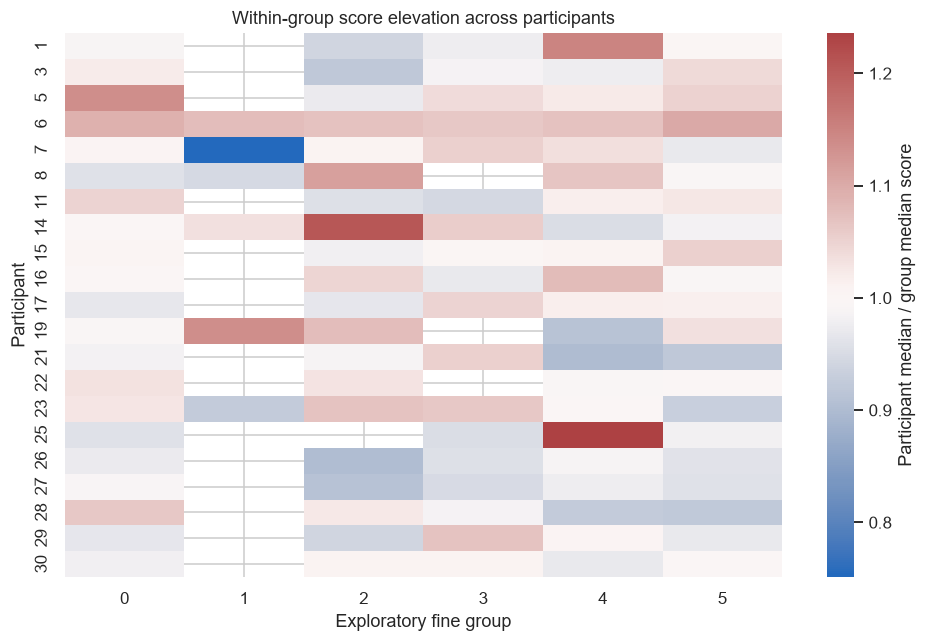

Cells above twice their group median score: 0


In [61]:
# Continuous view supporting the binary participant/group rule.
cell_display=cell.loc[cell.n>=12].copy()
if len(cell_display):
    gmed=results_train.groupby('cluster_fine').score_global.median()
    cell_display['relative_median_score']=cell_display['median_score']/np.maximum(
        cell_display.index.get_level_values('cluster_fine').map(gmed).to_numpy(),1e-9)
    mat=cell_display['relative_median_score'].unstack('cluster_fine')
    fig,ax=plt.subplots(figsize=(9,6))
    sns.heatmap(mat,center=1,cmap='vlag',ax=ax,cbar_kws={'label':'Participant median / group median score'})
    ax.set(xlabel='Exploratory fine group',ylabel='Participant',
           title='Within-group score elevation across participants')
    plt.tight_layout();plt.show()
    print('Cells above twice their group median score:',int((cell_display.relative_median_score>2).sum()))

## 7.5 Is a globally unusual window also unusual for its own participant?

Scores are compared against neighbourhoods of **other** windows from the same participant and discovered movement group. This provides a more individual-relative definition, but can be fragile for small participant–group cells; only sufficiently populated cells are used. Do not interpret agreement of two top-5% shortlists as the proportion of 'true' unusual events.

### 7.5.1 Person-relative nearest-neighbour scores

To test whether globally high scores are also high compared with the same individual's other windows of the same discovered group, we calculate participant–cluster neighbourhood distances. This is a train-only explanatory analysis; unseen participants do not have enough established personal reference data for the same procedure without adaptation.

Windows with sufficient personal reference: 7317/7352.
Overlap between global flags and individual-relative flags (valid subset): 17.5%


Person-relative shortlist,False,True
Global shortlist,,
False,6704,259
True,247,107


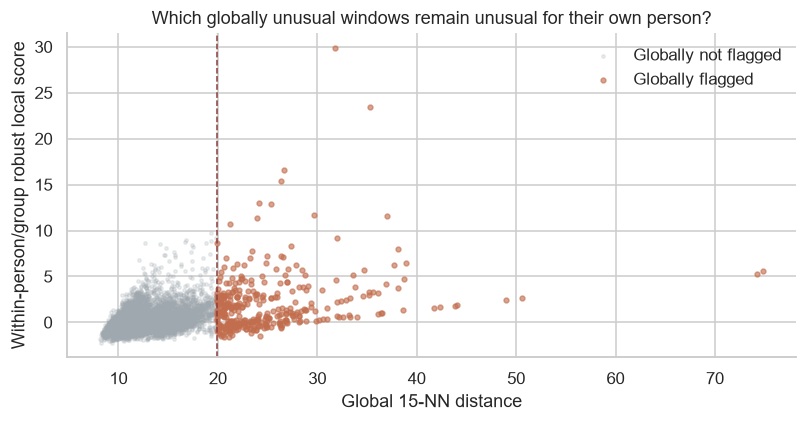

In [62]:
# Own-person, own-group reference: local k-NN distances exclude each window itself.
# Robust group-specific scaling avoids confusing a person's characteristic spread with an outlier.
within_person_score=np.full(len(X_repr),np.nan)
within_person_z=np.full(len(X_repr),np.nan)
for (subj,g),grp in results_train.groupby(['subject_id','cluster_fine']):
    ix=grp.index.to_numpy()
    if len(ix)<12: continue
    k=min(K_NEIGHBORS,len(ix)-1)
    local=NearestNeighbors(n_neighbors=k+1).fit(X_repr[ix])
    d=local.kneighbors(X_repr[ix])[0][:,k]
    med=np.median(d)
    mad=float(median_abs_deviation(d,scale='normal'))
    if mad<1e-8: mad=float(np.std(d))+1e-8
    within_person_score[ix]=d
    within_person_z[ix]=(d-med)/mad
valid=np.isfinite(within_person_z)
if valid.sum()>10:
    own_flags=np.zeros(len(X_repr),dtype=bool)
    own_flags[valid]=within_person_z[valid]>=np.quantile(within_person_z[valid],.95)
    print(f'Windows with sufficient personal reference: {valid.sum()}/{len(valid)}.')
    print('Overlap between global flags and individual-relative flags (valid subset):',
          f'{jaccard(flag_global[valid],own_flags[valid]):.1%}')
    category_counts=pd.crosstab(pd.Series(flag_global[valid],name='Global shortlist'),
                                pd.Series(own_flags[valid],name='Person-relative shortlist'))
    display(category_counts)
    fig,ax=plt.subplots(figsize=(7.5,4))
    ax.scatter(score_global[valid & ~flag_global],within_person_z[valid & ~flag_global],
               s=5,alpha=.2,color='#9fa8ae',rasterized=True,label='Globally not flagged')
    ax.scatter(score_global[valid & flag_global],within_person_z[valid & flag_global],
               s=10,alpha=.62,color='#c26e4e',rasterized=True,label='Globally flagged')
    ax.axvline(threshold_global,ls='--',lw=1,color='#8b3d3d')
    ax.set(xlabel='Global 15-NN distance',ylabel='Within-person/group robust local score',
           title='Which globally unusual windows remain unusual for their own person?')
    ax.legend(frameon=False);plt.tight_layout();plt.show()
else:
    print('Not enough individual reference windows for meaningful scoring.')

**Interpretation.** A low overlap between the global and personal shortlists indicates that population-level atypicality and within-person departure are identifying different cases. This would support distinguishing persistent individual patterns from rare changes relative to that individual. Such a score is not automatically more trustworthy; small participant–cluster groups and overlapping neighbouring windows can make personal estimates unstable.

## 7.6 Are consistent differences explained by simple participant offsets?

Subtracting a participant's average feature vector tests one specific mechanism: fixed person-level shifts in the selected feature space. It does not remove different individual variances, phone-placement changes or recording conditions, so similarity of shortlists should be interpreted narrowly.

### 7.6.1 Sensitivity to removing participant means

We subtract each participant's mean feature vector and recompute the global distance score. This checks whether participant-level offsets alone account for the unusualness ranking. It is a sensitivity analysis: participant centring changes the meaning of the feature space and is not applied to the principal RQ1/RQ2 models.

In [63]:
X_subject_centred=X_repr-pd.DataFrame(X_repr).groupby(meta_train.subject_id).transform('mean').to_numpy()
d_centred=NearestNeighbors(n_neighbors=K_NEIGHBORS+1,n_jobs=-1).fit(X_subject_centred).kneighbors(X_subject_centred)[0][:,K_NEIGHBORS]
f_centred=d_centred>=np.quantile(d_centred,.95)
print('Overlap of original and participant-centred global shortlists:',f'{jaccard(flag_global,f_centred):.1%}')
print('Rank correlation of original and participant-centred scores:',
      round(float(spearmanr(score_global,d_centred).statistic),3))
print('Small changes would mean participant means alone do not explain most flags; large changes would indicate sensitivity to participant offsets.')

Overlap of original and participant-centred global shortlists: 88.2%
Rank correlation of original and participant-centred scores: 0.983
Small changes would mean participant means alone do not explain most flags; large changes would indicate sensitivity to participant offsets.


**Interpretation.** The original investigation found that subtracting individual mean vectors changed the anomaly ranking only modestly. If this persists, participant concentration cannot be attributed solely to a fixed offset from the population mean. Other differences, including within-participant movement patterns, changes in variability or recording conditions, remain possible. This experiment does not identify which explanation is correct.

## 7.7 Activity context and sensitivity of systematic-pattern definitions

The apparent concentration of anomalies depends on whether 'comparable movement' means a broad discovered family, a fine exploratory cluster or one of the recorded activities. We make this sensitivity explicit instead of reporting one arbitrary systematic-versus-isolated percentage as a fact of human movement.

### 7.7.1 Participant rates by recorded activity

The supplied activity labels allow us to distinguish participant concentration arising from particular movement types. We inspect the activity-level flag rates of participants making the largest contribution to the global shortlist, rather than assuming that every participant differs uniformly across their recordings.

In [64]:
focus_subjects=person.nlargest(3,'flagged').index
sub_activity=(results_train.loc[results_train.subject_id.isin(focus_subjects)]
              .groupby(['subject_id','activity']).flag_global.agg(['size','mean']).reset_index())
sub_activity['flag_pct']=100*sub_activity['mean']
display(sub_activity.pivot(index='subject_id',columns='activity',values='flag_pct')
        .reindex(columns=ACTIVITIES).round(1))

activity,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
subject_id,,,,,,
8,18.8,29.3,71.1,2.2,1.9,3.7
19,42.3,17.5,82.1,1.4,0.0,0.0
23,27.1,2.0,75.9,1.5,0.0,0.0


**Interpretation.** Concentration confined to one activity suggests that a person's unusualness is conditional on the movement being performed, whereas consistently elevated scores across activities suggest a broader participant-associated effect. Because the six activities were recorded under a restricted protocol, these differences do not establish a general characteristic of the participant outside the dataset.

### 7.7.2 Broad, fine and activity-reference definitions

The choice of broad versus fine discovered clusters changes the reference group used to define a recurring participant-associated pattern. We apply the same descriptive rule under both resolutions and a known-activity grouping, to test how dependent the interpretation is on that choice.

In [65]:
def persistent_cells(group_values):
    frame=pd.DataFrame({'subject':results_train.subject_id.to_numpy(),
                        'group':np.asarray(group_values),
                        'score':score_global,'flag':flag_global})
    by=frame.groupby(['subject','group']).agg(n=('flag','size'),flags=('flag','sum'),
                                              median=('score','median'),rate=('flag','mean'))
    grp_rate=frame.groupby('group').flag.mean()
    grp_med=frame.groupby('group').score.median()
    expected=np.array([grp_rate[g] for _,g in by.index])
    medians=np.array([grp_med[g] for _,g in by.index])
    selected=(by.n.to_numpy()>=MIN_CELL_SIZE)&(by['flags'].to_numpy()>=3)&             (by.rate.to_numpy()>=2*np.maximum(expected,.01))&             (by['median'].to_numpy()>medians)
    return int(selected.sum()),int(by['flags'].to_numpy()[selected].sum())/max(1,int(flag_global.sum()))

context_sensitivity=[]
for name,groups in [('Broad clusters',cluster_broad),('Finer clusters',cluster_fine),
                    ('Known activity labels',meta_train.activity.to_numpy())]:
    cells,share=persistent_cells(groups)
    context_sensitivity.append({'reference_group':name,'elevated_participant_groups':cells,
                                'share_of_flags_in_these_groups':share})
display(pd.DataFrame(context_sensitivity).round(3))

,reference_group,elevated_participant_groups,share_of_flags_in_these_groups
0,Broad clusters,6,0.747
1,Finer clusters,6,0.193
2,Known activity labels,16,0.772


**Interpretation.** Different partitions define different populations of comparable windows. The original RQ3 found appreciable variation in the share classified as systematic when the reference grouping changed. Such sensitivity is a substantive finding: a global score, a coarse movement family and a fine movement group need not agree about whether a participant's observation is typical. The reported shares therefore describe the chosen operational rule, not a definitive partition of all human movement into systematic and isolated phenomena.

In [66]:
results_train['repeated_pattern_cell']=[bool(cell.loc[(sid,g),'repeated_elevated_pattern'])
                                       for sid,g in zip(results_train.subject_id,results_train.cluster_fine)]
print('Shared training results include:',list(results_train.columns))

Shared training results include: ['subject_id', 'activity_id', 'activity', 'window_id', 'cluster_broad', 'cluster_fine', 'score_global', 'flag_global', 'score_context', 'flag_context', 'score_iforest', 'score_lof', 'segment_id', 'position', 'approx_edge', 'segment_length', 'repeated_pattern_cell']


## 7.8 Physical case studies selected from the evidence

Choose representative *participant/activity combinations* from the global-rate analysis, then compare physical feature distributions and raw inertial traces across multiple windows. The case studies illustrate observed profiles; a single trace cannot establish stable individual motor behaviour.

Recorded activity used for participant comparison: WALKING_DOWNSTAIRS


,participant,feature,median,IQR,flag_rate
0,14,tBodyAccMag-mean(),0.175,0.152,0.822
1,14,tBodyAccJerkMag-mean(),0.002,0.182,0.822
2,14,tBodyGyroMag-mean(),0.161,0.230,0.822
3,17,tBodyAccMag-mean(),0.157,0.113,0.000
4,17,tBodyAccJerkMag-mean(),-0.241,0.130,0.000
5,17,tBodyGyroMag-mean(),-0.222,0.146,0.000


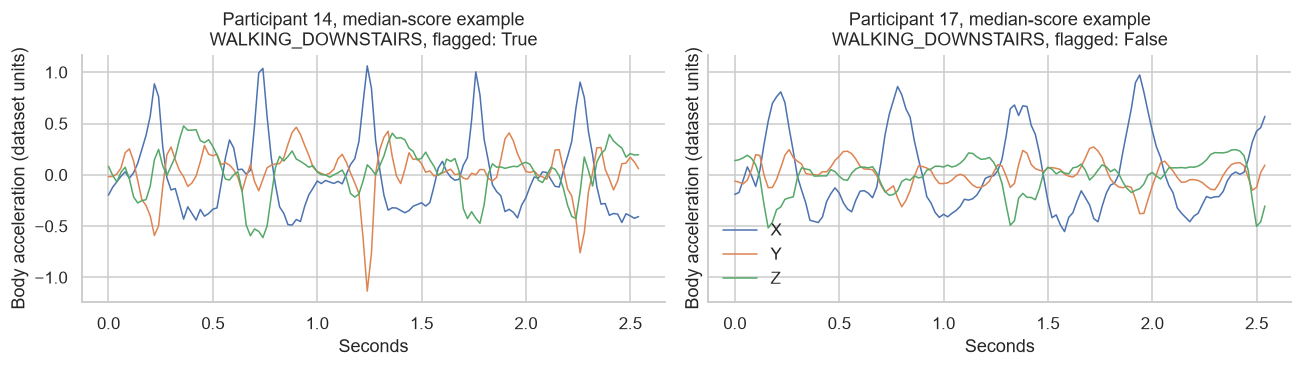

In [67]:
focus_activity=results_train.loc[results_train.flag_global,'activity'].value_counts().idxmax()
activity_person=results_train[results_train.activity==focus_activity].groupby('subject_id').agg(
    n=('flag_global','size'),rate=('flag_global','mean'),flags=('flag_global','sum'))
activity_person=activity_person[activity_person.n>=15]
if len(activity_person)>=2:
    high_sid=int(activity_person.rate.idxmax())
    low_sid=int(activity_person.rate.idxmin())
    feats=[f for f in ['tBodyAccMag-mean()','tBodyAccJerkMag-mean()','tBodyGyroMag-mean()'] if f in X_train_raw]
    example_rows=[]
    for sid in [high_sid,low_sid]:
        ix=(sub_arr==sid)&(act_arr==focus_activity)
        for feat in feats:
            example_rows.append({'participant':sid,'feature':feat,'median':X_train_raw.loc[ix,feat].median(),
                                 'IQR':X_train_raw.loc[ix,feat].quantile(.75)-X_train_raw.loc[ix,feat].quantile(.25),
                                 'flag_rate':float(flag_global[ix].mean())})
    print('Recorded activity used for participant comparison:',focus_activity)
    display(pd.DataFrame(example_rows).round(3))
    if signals_available:
        ids=[]
        for sid in [high_sid,low_sid]:
            cand=np.flatnonzero((sub_arr==sid)&(act_arr==focus_activity))
            ids.append(int(cand[np.argmin(np.abs(score_global[cand]-np.median(score_global[cand])))]))
        fig,axes=plt.subplots(1,2,figsize=(12,3.5),sharey=True)
        for ax,idx,sid in zip(axes,ids,[high_sid,low_sid]):
            for axis in 'xyz':ax.plot(np.arange(128)/50,body_acc[axis][idx],lw=1,label=axis.upper())
            ax.set(xlabel='Seconds',ylabel='Body acceleration (dataset units)',
                   title=f'Participant {sid}, median-score example\n{focus_activity}, flagged: {bool(flag_global[idx])}')
        axes[-1].legend(frameon=False)
        plt.tight_layout();plt.show()
else:
    print('Insufficient participants with >=15 windows for this activity; case study omitted.')

### Discussion of RQ3

The experiments address two hypotheses that can coexist: **participant-associated differences** and **isolated departures**. Within-activity participant profiles and group-adjusted concentration establish whether high scores associate with individuals. Run length and recurrence across reconstructed blocks assess whether high-scoring measurements are temporally concentrated or episodic. Person-relative scoring tests whether apparent global outliers are less exceptional in a participant's own movement distribution. Differences in the answer across broad clusters, finer groups and known activities must be retained as part of the result.

Crucially, high participant concentration does **not** by itself establish enduring individual motor behaviour. Adjacent flagged windows are dependent, and participant identity confounds individual movement characteristics with phone placement and recording protocol. The answer to RQ3 should distinguish supported recurrence from ambiguous mechanisms rather than force every flagged window into a definitive systematic/isolated category.

# 8. Overall Synthesis and Generalisation

This final section answers the **single overarching research question** by combining RQ1's movement structure, RQ2's variation and anomaly explanations, and RQ3's individual/temporal evidence. Generalisation is an **evaluation of those findings**, not a new research question. All train-derived representation choices, cluster models, anomaly reference pools and thresholds are frozen before using the subject-disjoint held-out split.

## 8.1 Joint evidence on structure and unusualness

The same windows have been tracked throughout the investigation. This table deliberately juxtaposes group size, activity composition, global flagging, group-relative flagging and participant breadth. It is a synthesis of the three questions, not a replacement for their individual discussions.

In [68]:
synthesis=results_train.groupby('cluster_fine').agg(
    windows=('window_id','size'),
    global_flags=('flag_global','sum'),
    global_rate=('flag_global','mean'),
    contextual_rate=('flag_context','mean'),
    participants=('subject_id','nunique'))
synthesis['share_of_global_flags']=synthesis.global_flags/max(1,int(results_train.flag_global.sum()))
synthesis['most_common_recorded_activity']=[activity_mix_fine.loc[g].idxmax() for g in synthesis.index]
display(synthesis[['windows','global_rate','contextual_rate','share_of_global_flags',
                   'participants','most_common_recorded_activity']].style.format({
    'global_rate':'{:.1%}','contextual_rate':'{:.1%}','share_of_global_flags':'{:.1%}'}))

,windows,global_rate,contextual_rate,share_of_global_flags,participants,most_common_recorded_activity
cluster_fine,,,,,,
0,1669,0.0%,5.9%,0.0%,21,STANDING
1,260,80.0%,8.1%,56.5%,12,WALKING_DOWNSTAIRS
2,1420,6.6%,3.5%,25.5%,20,WALKING
3,1616,1.3%,3.9%,5.7%,21,WALKING_UPSTAIRS
4,1224,3.7%,6.5%,12.2%,21,STANDING
5,1163,0.0%,4.9%,0.0%,21,LAYING


**Interpretation.** The central comparison is whether a group containing a disproportionate share of global flags remains unusual under the group-relative detector. A substantial reduction indicates that global distance was partly measuring the rarity or distinctness of a coherent subgroup rather than isolated departures within it. Participant and activity correspondence add context, but neither source of labels establishes that a particular high-scoring window is an objectively abnormal human movement.

## 8.2 Generalisation: unseen participants and frozen movement structure

Apply the training-fitted feature selector, standardiser, PCA display and K-Means partitions to the original nine test participants **without refitting**. The supplied labels describe the assigned groups after prediction; they are never used to adjust the clustering.

Held-out windows: 2,947 from 9 new participants.


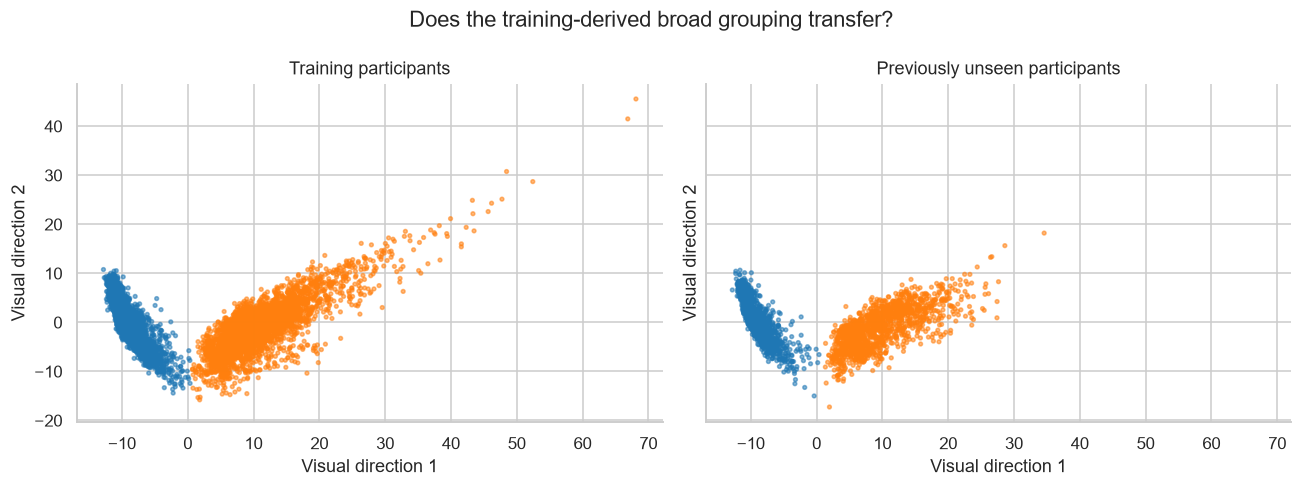

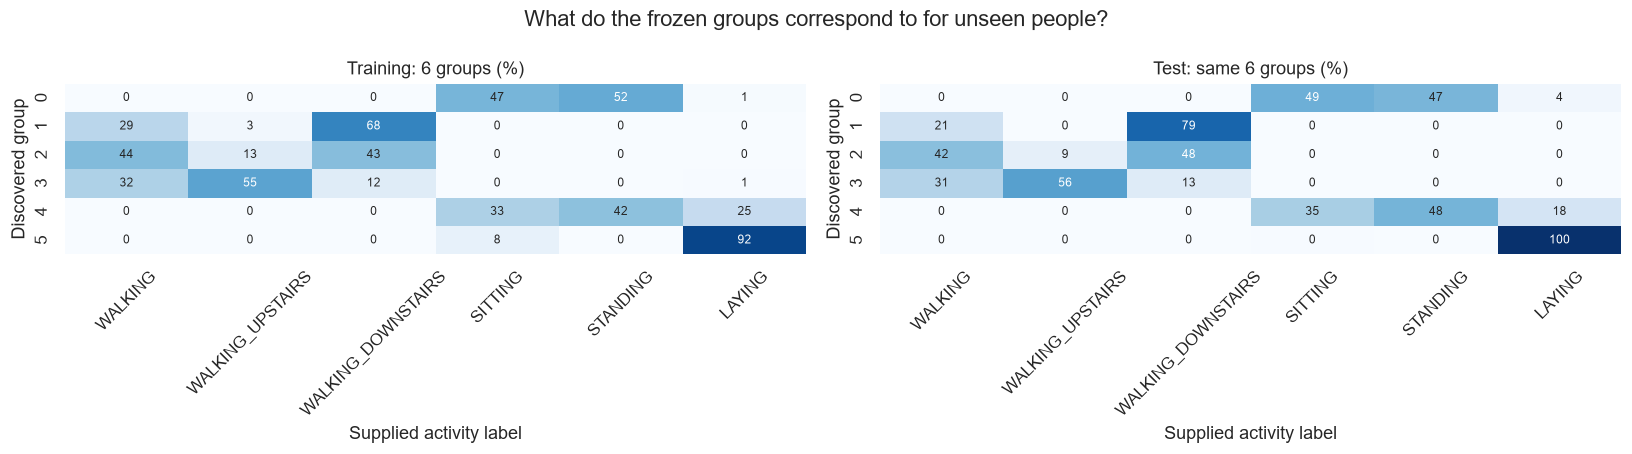

The label composition is interpreted after applying frozen clusters; it is not used to refit them.


In [69]:
# Frozen preprocessing and RQ1 models: no fitting to the test split.
X_test_raw,meta_test=load_split('test')
assert set(meta_train.subject_id).isdisjoint(set(meta_test.subject_id)), 'Train/test subjects must not overlap'
X_test_repr=scaler.transform(selector.transform(X_test_raw))
view_test=pca_view.transform(X_test_repr)
test_broad=model_broad.predict(X_test_repr)
test_fine=model_fine.predict(X_test_repr)
print(f'Held-out windows: {len(meta_test):,} from {meta_test.subject_id.nunique()} new participants.')

# Both panels use the training-fitted 2D projection and the training-fitted cluster centres.
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharex=True,sharey=True)
for ax,points,labs,title in [(axes[0],view_train,cluster_broad,'Training participants'),
                              (axes[1],view_test,test_broad,'Previously unseen participants')]:
    ax.scatter(points[:,0],points[:,1],c=labs,s=6,cmap='tab10',vmin=0,vmax=9,alpha=.55,rasterized=True)
    ax.set(title=title,xlabel='Visual direction 1',ylabel='Visual direction 2')
plt.suptitle('Does the training-derived broad grouping transfer?')
plt.tight_layout();plt.show()

fig,axes=plt.subplots(1,2,figsize=(15,4.2))
plot_cluster_activity(axes[0],cluster_fine,meta_train.activity,f'Training: {k_fine} groups (%)')
plot_cluster_activity(axes[1],test_fine,meta_test.activity,f'Test: same {k_fine} groups (%)')
plt.suptitle('What do the frozen groups correspond to for unseen people?')
plt.tight_layout();plt.show()
print('The label composition is interpreted after applying frozen clusters; it is not used to refit them.')

**Interpretation.** Similar broad regions and cluster–activity relationships in both splits would support transfer of the discovered structure to new participants. Differences in subgroup composition would qualify claims about the generality of finer clusters. The test data cannot establish that the discovered groups are uniquely correct, but they can reveal whether the training-derived partition behaves consistently in a subject-disjoint population.

## 8.3 Generalisation: do anomaly patterns transfer?

A training top-5% threshold does not imply 5% of unseen windows must be flagged. Test windows use **training reference neighbours**, while cluster-relative scores use the frozen group-specific neighbourhoods and scales. Differences across activities and participants describe transfer of the scoring behaviour, not detection accuracy against unavailable ground-truth anomaly labels.

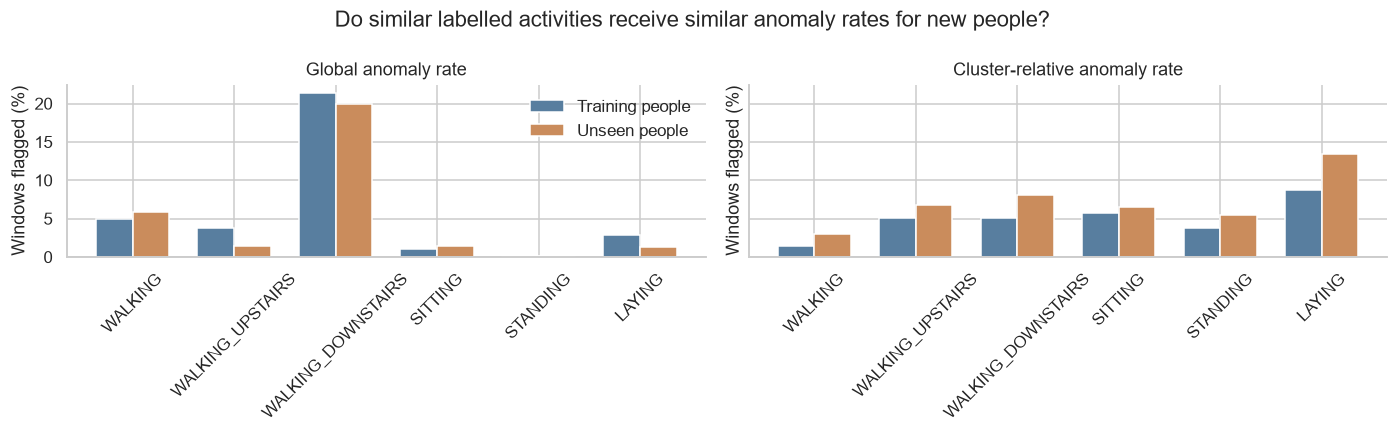

Overall global flag rate: training 5.0% , unseen participants 4.6%
A changed rate is evidence of changed scoring behaviour, not proof of anomaly-detector error.


In [70]:
# Test global score: no self-neighbour in training reference, so use the same 15-neighbour rank.
d_test=nn_global.kneighbors(X_test_repr,n_neighbors=K_NEIGHBORS)[0]
test_score_global=d_test[:,K_NEIGHBORS-1]
test_flag_global=test_score_global>=threshold_global

test_score_context=np.empty(len(X_test_repr))
for g in np.unique(test_fine):
    ix=np.flatnonzero(test_fine==g)
    nn,k_eff,ref_ix=local_models[int(g)]
    raw=nn.kneighbors(X_test_repr[ix],n_neighbors=k_eff)[0][:,k_eff-1]
    med,spread_g=cluster_refs[int(g)]
    test_score_context[ix]=(raw-med)/spread_g
test_flag_context=test_score_context>=threshold_context

results_test=meta_test.copy()
results_test['cluster_broad']=test_broad;results_test['cluster_fine']=test_fine
results_test['score_global']=test_score_global;results_test['flag_global']=test_flag_global
results_test['score_context']=test_score_context;results_test['flag_context']=test_flag_context

def activity_rates(frame):
    return frame.groupby('activity')[['flag_global','flag_context']].mean().reindex(ACTIVITIES)*100
train_rates=activity_rates(results_train);test_rates=activity_rates(results_test)
fig,axes=plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,name in zip(axes,['flag_global','flag_context']):
    x=np.arange(len(ACTIVITIES));width=.36
    ax.bar(x-width/2,train_rates[name],width,color='#587e9f',label='Training people')
    ax.bar(x+width/2,test_rates[name],width,color='#ca8c5c',label='Unseen people')
    ax.set_xticks(x,ACTIVITIES,rotation=45)
    ax.set(ylabel='Windows flagged (%)',title=('Global' if name=='flag_global' else 'Cluster-relative')+' anomaly rate')
axes[0].legend(frameon=False)
plt.suptitle('Do similar labelled activities receive similar anomaly rates for new people?')
plt.tight_layout();plt.show()
print('Overall global flag rate: training',f'{flag_global.mean():.1%}',
      ', unseen participants',f'{test_flag_global.mean():.1%}')
print('A changed rate is evidence of changed scoring behaviour, not proof of anomaly-detector error.')

**Interpretation.** The training shortlist is defined at 5%, but the proportion flagged in test data is not fixed. An increase or decrease for unseen people reflects how their feature measurements compare with the training references. The comparison by labelled activity shows whether the broad anomaly-pattern conclusions recur, without providing ground-truth anomaly labels or making a claim of detection accuracy.

### 8.3.1 Participant-level variability in the held-out set

RQ3's individual-difference argument can be checked descriptively without treating test participants as additional training observations. For each recorded activity, compare the held-out participants' within-person spread and their contribution to the flagged windows. The inference remains limited by only nine new people and the same collection protocol.

,participants,median_person_spread,IQR_person_spread,median_person_flag_rate
activity,,,,
WALKING,9,126.483,84.158,0.017
WALKING_UPSTAIRS,9,143.228,51.628,0.000
WALKING_DOWNSTAIRS,9,217.320,71.383,0.167
SITTING,9,126.618,24.929,0.020
STANDING,9,110.779,16.891,0.000
LAYING,9,134.898,37.985,0.017


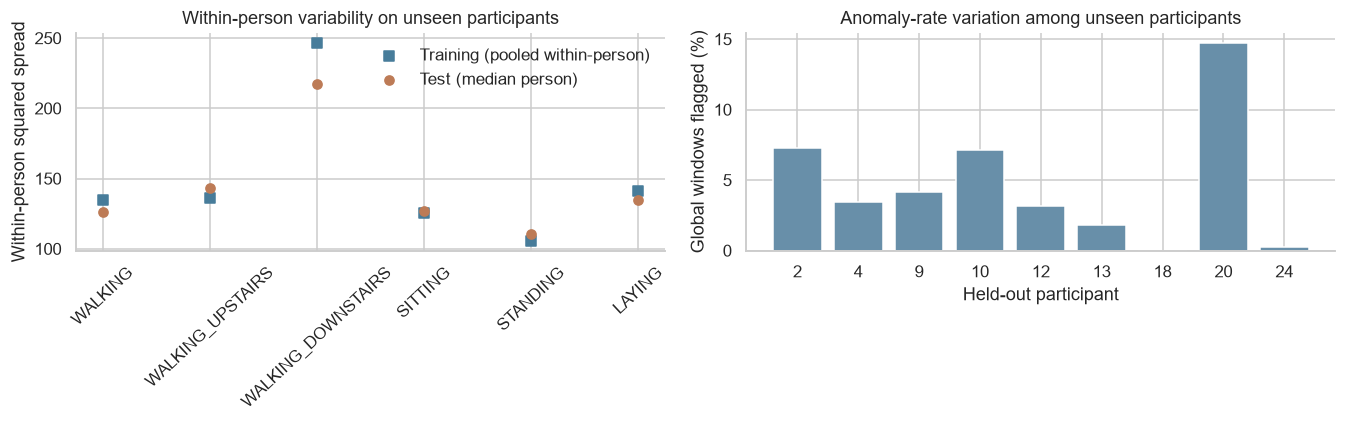

In [71]:
test_act=meta_test.activity.to_numpy();test_sub=meta_test.subject_id.to_numpy()
heldout_person=[]
for activity in ACTIVITIES:
    for sid in np.unique(test_sub):
        ix=(test_act==activity)&(test_sub==sid)
        if ix.sum()>=2:
            x=X_test_repr[ix]
            heldout_person.append({'activity':activity,'subject_id':int(sid),'windows':int(ix.sum()),
                                   'within_spread':float(np.mean(np.sum((x-x.mean(axis=0))**2,axis=1))),
                                   'global_flag_rate':float(test_flag_global[ix].mean())})
heldout_person=pd.DataFrame(heldout_person)
heldout_stats=heldout_person.groupby('activity').agg(
    participants=('subject_id','nunique'),median_person_spread=('within_spread','median'),
    IQR_person_spread=('within_spread',lambda z:z.quantile(.75)-z.quantile(.25)),
    median_person_flag_rate=('global_flag_rate','median')).reindex(ACTIVITIES)
display(heldout_stats.round(3))
fig,axes=plt.subplots(1,2,figsize=(12.4,4))
axes[0].scatter(np.arange(len(ACTIVITIES)),variation_decomp.loc[ACTIVITIES,'within_spread'],
                marker='s',label='Training (pooled within-person)',color='#477c9a')
axes[0].scatter(np.arange(len(ACTIVITIES)),heldout_stats.median_person_spread,
                marker='o',label='Test (median person)',color='#bd7b56')
axes[0].set(xticks=np.arange(len(ACTIVITIES)),xticklabels=ACTIVITIES,
            ylabel='Within-person squared spread',title='Within-person variability on unseen participants')
axes[0].tick_params(axis='x',rotation=43);axes[0].legend(frameon=False)
heldout_flags=results_test.groupby('subject_id').flag_global.mean()*100
axes[1].bar(heldout_flags.index.astype(str),heldout_flags.values,color='#688fa9')
axes[1].set(xlabel='Held-out participant',ylabel='Global windows flagged (%)',
            title='Anomaly-rate variation among unseen participants')
plt.tight_layout();plt.show()

## 8.4 Supervised predictability as a complementary perspective

A classifier may accurately distinguish six **labelled** activities even if unsupervised clustering does not recover six well-separated geometric groups. A logistic-regression baseline is tuned by participant-grouped training folds, with feature selection and scaling refitted within each fold, and then evaluated once on the untouched test participants. This supervised check is **supporting evidence**, not another research question.

Training-only, participant-grouped CV macro-F1: [0.939 0.975 0.947 0.854] | mean: 0.929
Held-out six-activity accuracy: 95.0%
Held-out macro-F1: 0.950
Held-out balanced accuracy: 0.949


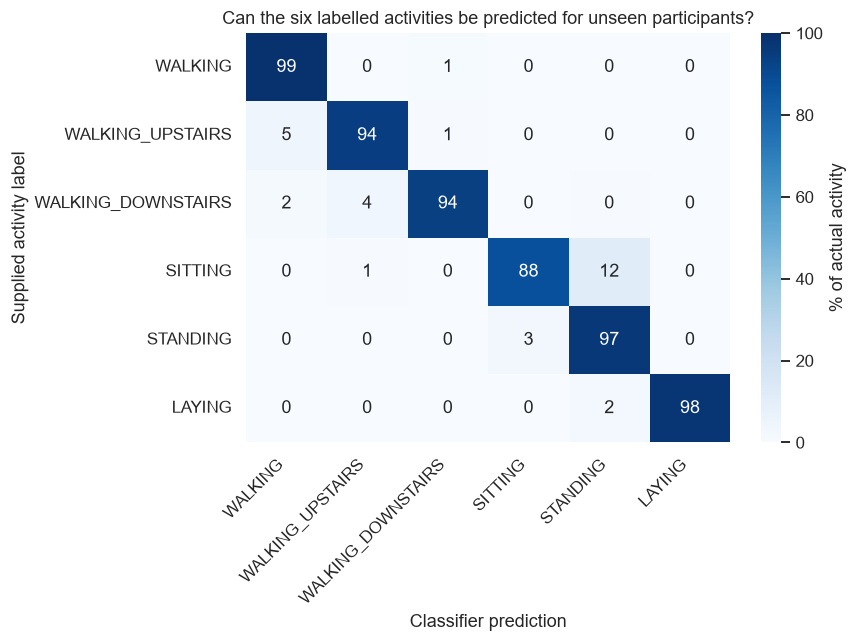

Held-out moving/still classification accuracy: 100.0%


In [72]:
from sklearn.model_selection import GroupKFold
# Full raw features enter this pipeline: every training fold independently selects and scales them.
classification_pipeline=Pipeline([
    ('physical_features',HARPhysicalFeatureSelector(threshold=.95)),
    ('standardise',StandardScaler()),
    ('classifier',LogisticRegression(max_iter=1800,solver='lbfgs'))
])
cv=GroupKFold(n_splits=4)
cv_f1=cross_val_score(classification_pipeline,X_train_raw,meta_train.activity,
                      groups=meta_train.subject_id,cv=cv,scoring='f1_macro',n_jobs=1)
print('Training-only, participant-grouped CV macro-F1:',np.round(cv_f1,3),
      '| mean:',round(float(np.mean(cv_f1)),3))
classification_pipeline.fit(X_train_raw,meta_train.activity)
pred_test=classification_pipeline.predict(X_test_raw)
print('Held-out six-activity accuracy:',f'{accuracy_score(meta_test.activity,pred_test):.1%}')
print('Held-out macro-F1:',f'{f1_score(meta_test.activity,pred_test,average="macro"):.3f}')
print('Held-out balanced accuracy:',f'{balanced_accuracy_score(meta_test.activity,pred_test):.3f}')

cm=confusion_matrix(meta_test.activity,pred_test,labels=ACTIVITIES,normalize='true')
fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(cm*100,ax=ax,annot=True,fmt='.0f',cmap='Blues',vmin=0,vmax=100,cbar_kws={'label':'% of actual activity'})
ax.set_xticklabels(ACTIVITIES,rotation=45,ha='right')
ax.set_yticklabels(ACTIVITIES,rotation=0)
ax.set(xlabel='Classifier prediction',ylabel='Supplied activity label',
       title='Can the six labelled activities be predicted for unseen participants?')
plt.tight_layout();plt.show()

# Binary moving-vs-still is a label-informed SUPERVISED accuracy measure, not cluster validity.
MOVING={'WALKING','WALKING_UPSTAIRS','WALKING_DOWNSTAIRS'}
true_family=np.isin(meta_test.activity,MOVING);pred_family=np.isin(pred_test,MOVING)
print('Held-out moving/still classification accuracy:',f'{accuracy_score(true_family,pred_family):.1%}')

**Interpretation.** A high six-activity classification score alongside weaker six-cluster separation would demonstrate that labelled activities are discriminable using supervised boundaries without necessarily forming six compact, naturally separated groups. The confusion matrix identifies which activity pairs are difficult to predict for unseen people. Classification is not a measure of anomaly ground truth or proof that the cluster assignments recover the labelled categories.

## 8.5 Integrated answer to the overarching question

**Organisation (RQ1).** Discuss which movement divisions are reproducible across clustering assumptions and participants, how physical measurements characterise them, and which finer divisions are sensitive or overlapping. State explicitly that the labelled activity count is not automatically the natural cluster count.

**Variation (RQ2).** Describe the observed within-person versus between-person spread, the activity-specific concentration of high global anomaly scores, and the effects of changing detector and reference population. The spread-equalisation intervention should be interpreted as a test of a plausible statistical mechanism, not a causal proof about human movement.

**Individual behaviour (RQ3).** Distinguish persistent participant-level feature differences, concentration within recorded movement groups, recurring segments and isolated departures. Short runs of overlapping windows do not demonstrate durable personal traits; the dataset cannot fully separate gait from phone placement or recording conditions.

**Generalisation.** Use frozen assignments, held-out anomaly rates and classification errors to decide which aspects recur for previously unseen people. A high supervised classification score alongside weak fine-cluster separation is not contradictory: supervision can learn boundaries between known classes that do not naturally form compact clusters.

**Integrated conclusion:** Smartphone sensor features can reveal strong broad movement organisation and meaningful variation within it, but the status of an unusual window depends on whether the reference is the whole dataset, a movement group or a person's comparable behaviour. The degree to which these findings reflect stable individual motor characteristics remains less certain than the existence of broad movement structure. The final submitted interpretation must be reconciled against the results of this integrated rerun, not copied from the standalone 540-feature notebooks.

## 8.6 Limitations and threats to validity

- **Measurement and representation:** engineered features are strongly dependent; within-family correlation filtering changes distance weighting and may not preserve all physical information. Standardisation does not neutralise remaining feature-family imbalance.
- **Clustering:** Euclidean K-Means, Ward and Gaussian mixtures use different geometry and assumptions. Finer clusters may not be stable, and a 2-D PCA scatterplot cannot validate high-dimensional cluster separation.
- **Anomaly interpretation:** fixed top-fraction shortlists are comparisons, not ground-truth abnormal events. Local detectors and context-rescaled scores are not directly interchangeable. Sensitivity to group count and detector parameters is part of the finding.
- **Dependence and participant confounding:** overlapping windows inflate apparent sample size; participant-level resampling is preferred for inferential summaries. Phone placement, recording procedures and actual movement may vary together.
- **Temporal interpretation:** reconstructed recording blocks and boundaries are proxies, not verified transition labels. Multiple adjacent flagged windows may reflect one event.
- **Generalisation:** nine held-out participants from the same dataset protocol test subject transfer, not universal movement behaviour. Model calibration, class imbalance and changes in activity mix can affect reported percentages.

These limitations qualify the conclusions; none require replacing the investigation with a different, unrelated modelling task.

# 9. References, Reproducibility and Research Integrity

Anguita, D., Ghio, A., Oneto, L., Parra, X. and Reyes-Ortiz, J. L. (2013). *A public domain dataset for human activity recognition using smartphones*. ESANN 2013, 437–442. [UCI dataset](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones).

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.

Breunig, M. M., Kriegel, H.-P., Ng, R. T. and Sander, J. (2000). LOF: Identifying density-based local outliers. *Proceedings of ACM SIGMOD*, 93–104.

Liu, F. T., Ting, K. M. and Zhou, Z.-H. (2008). Isolation Forest. *Proceedings of IEEE ICDM*, 413–422.

MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proceedings of the Fifth Berkeley Symposium on Mathematical Statistics and Probability*, 1, 281–297.

**Reproducibility.** Run cells from the first to last in a fresh kernel. Set `HAR_DATA_DIR` if the dataset is not directly under the notebook. The feature selector, scalers, clustering, anomaly references and thresholds are fitted exclusively on the training split. Experimental randomness is explicitly seeded. The original test data are not loaded until Section 8. Save the complete executed notebook and check all numerical claims, figures and interpretation together.

**Generative-AI integrity statement (group confirmation required).** This integrated version was reorganised and partly drafted with AI assistance using the members' existing notebooks. Before submitting, the group must accurately disclose the assistance received, confirm credit for each experimental contribution, independently verify code and statistical reasoning, and revise any conclusions that do not match the final executed results.